# Modelo de difusión Bernoulli condicionado para la generación de máscaras tumorales

**Objetivo específico 2:** Desarrollar un modelo de difusión condicionado por plano anatómico y tipo de tumor para la generación de máscaras sintéticas de tumores cerebrales.

Se implementa un modelo de difusión Bernoulli con arquitectura U-Net condicionada para generar máscaras binarias de tumores cerebrales. El procedimiento comprende la preparación del conjunto BRISC depurado, el entrenamiento con tres ponderaciones espaciales basadas en la región efectiva $R_i$, la generación de máscaras sintéticas y su postprocesamiento mediante controles de plausibilidad morfológica.

## 1. Librerías y reproducibilidad

Se importan las dependencias y se establece el dispositivo de cálculo y las semillas aleatorias.

In [1]:
from __future__ import annotations

import os
import re
import gc
import json
import math
import time
import random
import shutil
from copy import deepcopy
from dataclasses import dataclass, asdict
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from scipy import ndimage
from scipy.ndimage import gaussian_filter
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

print('PyTorch:', torch.__version__)
print('CUDA disponible:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print(
        'VRAM total (GB):',
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2,
        ),
    )


PyTorch: 2.11.0+cu128
CUDA disponible: True
GPU: NVIDIA GeForce RTX 4060 Ti
VRAM total (GB): 16.0


In [2]:
# Semilla global
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Reproducibilidad razonable. Si se requiere máxima velocidad, benchmark puede dejarse en True.
torch.backends.cudnn.benchmark = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', DEVICE)


Dispositivo: cuda


## 2. Configuración del experimento

Se especifican los parámetros del modelo, las tres ponderaciones de la región efectiva y los directorios de entrada y salida. Cada ponderación se entrena de forma independiente.

In [3]:
@dataclass
class Config:
    # Datos
    DATA_ROOT: str = 'data/BRISC2025/segmentation_task/train'
    TEST_ROOT: str = 'data/BRISC2025/segmentation_task/test'
    MASK_DIRNAME: str = 'masks'
    IMAGE_DIRNAME: str = 'images'

    # Máscaras BRISC
    MASK_THRESHOLD: int = 127
    MASK_CONNECTIVITY: int = 2  # 2 = conectividad de 8 vecinos en 2D

    # Región efectiva OE1
    INTENSITY_THRESHOLD: int = 15
    ROI_CONNECTIVITY: int = 2  # conectividad de 8 vecinos 
    ROI_OUTSIDE_WEIGHT: float = 0.10  # 0.10 / 0.50 / 1.00

    # División reproducible del BRISC test
    TEST_SPLIT_RANDOM_STATE: int = 20260915
    VALIDATION_FRACTION: float = 0.50

    # Carpeta común del OE2
    BASE_RESULTS_ROOT: str = 'results/OE2'

    PROFILE: str = 'final'  # 'desarrollo' o 'final'

    # Modelo / difusión Bernoulli
    RANDOM_STATE: int = 42
    IMAGE_SIZE: int = 256
    BASE_CHANNELS: int = 64
    TIME_EMB_DIM: int = 256
    TIMESTEPS: int = 1000
    BETA_START: float = 1e-4
    BETA_END: float = 2e-2
    LAMBDA_BCE: float = 1.0
    PROB_EPS: float = 1e-6

    # Entrenamiento
    BATCH_SIZE: int = 6
    EPOCHS: int = 150
    LR: float = 1e-4
    WEIGHT_DECAY: float = 1e-4
    GRAD_CLIP: float = 1.0
    EMA_DECAY: float = 0.9999
    NUM_WORKERS: int = 0
    USE_AMP: bool = False

    # Monitoreo / diagnóstico
    SAMPLE_EVERY: int = 5
    SAVE_EVERY: int = 5
    EARLY_STOP_PATIENCE: int = 30
    VAL_SEED: int = 20260810
    VAL_TIMESTEP_BINS: int = 10
    MONITOR_SEED: int = 20260811
    MONITOR_SAMPLING_STEPS: int = 50
    COMPARE_EMA_EVERY: int = 10
    DIAGNOSTIC_N: int = 3

    # Muestreo final
    SAMPLING_STEPS: int = 100
    THRESHOLD: float = 0.5

    # Control de calidad morfológico
    # Intervalo central del 99%: [q0.005, q0.995]
    QC_Q_LOW: float = 0.005
    QC_Q_HIGH: float = 0.995
    MIN_COMPONENT_PIXELS: int = 8

    # Postprocesamiento final
    # Valor actual. Cambiar aquí si el análisis final de sigma selecciona otro.
    POSTPROCESS_SIGMA: float = 2.0
    POSTPROCESS_THRESHOLD: float = 0.5
    MAX_ATTEMPT_FACTOR: int = 20


CFG = Config()

# El entrenamiento permanece desactivado por defecto.
RUN_TRAINING = False

if CFG.PROFILE not in {'desarrollo', 'final'}:
    raise ValueError(
        "CFG.PROFILE debe ser 'desarrollo' o 'final'."
    )

if CFG.ROI_OUTSIDE_WEIGHT not in {0.1, 0.5, 1.0}:
    raise ValueError(
        'CFG.ROI_OUTSIDE_WEIGHT debe ser 0.1, 0.5 o 1.0.'
    )

if not 0.0 < CFG.VALIDATION_FRACTION < 1.0:
    raise ValueError(
        'CFG.VALIDATION_FRACTION debe estar entre 0 y 1.'
    )

if CFG.PROFILE == 'desarrollo':
    CFG.IMAGE_SIZE = 128
    CFG.BASE_CHANNELS = 48
    CFG.BATCH_SIZE = 8
    CFG.EPOCHS = 30
    CFG.TIMESTEPS = 500
    CFG.SAMPLING_STEPS = 50
    CFG.MONITOR_SAMPLING_STEPS = 25
    CFG.SAMPLE_EVERY = 1
    CFG.SAVE_EVERY = 1
    CFG.COMPARE_EMA_EVERY = 5

CONNECTIVITY_STRUCTURE = ndimage.generate_binary_structure(
    rank=2,
    connectivity=CFG.ROI_CONNECTIVITY,
)





# Rutas relativas a la raíz del repositorio.
def localizar_raiz_repositorio():
    """Localiza el repositorio desde su raíz o un subdirectorio."""
    actual = Path.cwd().resolve()
    for candidato in (actual, *actual.parents):
        if (candidato / 'notebooks' / 'OE2').is_dir():
            return candidato
    raise FileNotFoundError(
        'No se encontró la raíz del repositorio (notebooks/OE2). '
        'Ejecutar JupyterLab desde la raíz o un subdirectorio del repositorio.'
    )


REPO_ROOT = localizar_raiz_repositorio()

DATA_ROOT = REPO_ROOT / CFG.DATA_ROOT
TEST_ROOT = REPO_ROOT / CFG.TEST_ROOT
MASK_DIR = DATA_ROOT / CFG.MASK_DIRNAME
TEST_MASK_DIR = TEST_ROOT / CFG.MASK_DIRNAME
TRAIN_IMAGE_DIR = DATA_ROOT / CFG.IMAGE_DIRNAME
TEST_IMAGE_DIR = TEST_ROOT / CFG.IMAGE_DIRNAME

BASE_RESULTS_ROOT = REPO_ROOT / CFG.BASE_RESULTS_ROOT


def weight_folder_name(weight: float) -> str:
    code = int(round(float(weight) * 10))
    return f'roiOE1_peso{code:02d}'


WEIGHT_FOLDER = weight_folder_name(
    CFG.ROI_OUTSIDE_WEIGHT
)

OUTPUT_ROOT = (
    BASE_RESULTS_ROOT
    / 'difusion_bernoulli'
    / CFG.PROFILE
    / WEIGHT_FOLDER
)

# Recursos compartidos entre los tres pesos y reutilizables en OE3.
PREPROCESS_ROOT = (
    BASE_RESULTS_ROOT
    / 'preprocesamiento'
)
ROI_CACHE_ROOT = (
    PREPROCESS_ROOT
    / f'roiOE1_umbral{CFG.INTENSITY_THRESHOLD}'
)
ROI_CACHE_TRAIN_DIR = ROI_CACHE_ROOT / 'train'
ROI_CACHE_TEST_DIR = ROI_CACHE_ROOT / 'test'

COMMON_SPLIT_DIR = BASE_RESULTS_ROOT / 'particiones'
COMMON_SPLIT_CSV = (
    COMMON_SPLIT_DIR
    / 'brisc_test_validation_test_50_50.csv'
)

CHECKPOINT_DIR = OUTPUT_ROOT / 'checkpoints'
SAMPLE_DIR = OUTPUT_ROOT / 'muestras_entrenamiento'
SYNTH_DIR = OUTPUT_ROOT / 'mascaras_sinteticas_preliminares'
FINAL_SYNTH_DIR = OUTPUT_ROOT / 'mascaras_sinteticas_finales'
TABLE_DIR = OUTPUT_ROOT / 'tablas'
DIAGNOSTIC_DIR = OUTPUT_ROOT / 'diagnosticos'
RECON_DIR = DIAGNOSTIC_DIR / 'reconstruccion_y0'
EMA_COMPARE_DIR = DIAGNOSTIC_DIR / 'comparacion_modelo_ema'

for ruta in (MASK_DIR, TRAIN_IMAGE_DIR, TEST_MASK_DIR, TEST_IMAGE_DIR):
    if not ruta.is_dir():
        raise FileNotFoundError(f'No se encontró el directorio BRISC esperado: {ruta}')

for d in [
    OUTPUT_ROOT,
    CHECKPOINT_DIR,
    SAMPLE_DIR,
    SYNTH_DIR,
    FINAL_SYNTH_DIR,
    TABLE_DIR,
    DIAGNOSTIC_DIR,
    RECON_DIR,
    EMA_COMPARE_DIR,
    ROI_CACHE_TRAIN_DIR,
    ROI_CACHE_TEST_DIR,
    COMMON_SPLIT_DIR,
]:
    d.mkdir(parents=True, exist_ok=True)

print(json.dumps(asdict(CFG), indent=2, ensure_ascii=False))
print('\nMétodo: bernoulli')
print('Perfil:', CFG.PROFILE)
print('Máscaras:', MASK_DIR)
print('Imágenes MRI:', TRAIN_IMAGE_DIR)
print('Umbral de intensidad OE1:', CFG.INTENSITY_THRESHOLD)
print('Peso fuera de R_i:', CFG.ROI_OUTSIDE_WEIGHT)
print('Carpeta del experimento:', WEIGHT_FOLDER)
print('Split compartido OE2/OE3:', COMMON_SPLIT_CSV)
print('Cache R_i:', ROI_CACHE_ROOT)
print('Resultados:', OUTPUT_ROOT)


{
  "DATA_ROOT": "data/BRISC2025/segmentation_task/train",
  "TEST_ROOT": "data/BRISC2025/segmentation_task/test",
  "MASK_DIRNAME": "masks",
  "IMAGE_DIRNAME": "images",
  "MASK_THRESHOLD": 127,
  "MASK_CONNECTIVITY": 2,
  "INTENSITY_THRESHOLD": 15,
  "ROI_CONNECTIVITY": 2,
  "ROI_OUTSIDE_WEIGHT": 0.1,
  "TEST_SPLIT_RANDOM_STATE": 20260915,
  "VALIDATION_FRACTION": 0.5,
  "BASE_RESULTS_ROOT": "results/OE2",
  "PROFILE": "final",
  "RANDOM_STATE": 42,
  "IMAGE_SIZE": 256,
  "BASE_CHANNELS": 64,
  "TIME_EMB_DIM": 256,
  "TIMESTEPS": 1000,
  "BETA_START": 0.0001,
  "BETA_END": 0.02,
  "LAMBDA_BCE": 1.0,
  "PROB_EPS": 1e-06,
  "BATCH_SIZE": 6,
  "EPOCHS": 150,
  "LR": 0.0001,
  "WEIGHT_DECAY": 0.0001,
  "GRAD_CLIP": 1.0,
  "EMA_DECAY": 0.9999,
  "NUM_WORKERS": 0,
  "USE_AMP": false,
  "SAMPLE_EVERY": 5,
  "SAVE_EVERY": 5,
  "EARLY_STOP_PATIENCE": 30,
  "VAL_SEED": 20260810,
  "VAL_TIMESTEP_BINS": 10,
  "MONITOR_SEED": 20260811,
  "MONITOR_SAMPLING_STEPS": 50,
  "COMPARE_EMA_EVERY": 10,
  

## 3. Lectura de las máscaras BRISC

Se identifican las máscaras del conjunto depurado y sus condiciones de tipo de tumor y plano anatómico.

In [4]:
TUMOR_MAP = {
    'gl': 'Glioma',
    'me': 'Meningioma',
    'pi': 'Pituitario',
}

PLANE_MAP = {
    'ax': 'Axial',
    'co': 'Coronal',
    'sa': 'Sagital',
}

FILENAME_RE = re.compile(
    r'^brisc2025_(?P<split>train|test)_(?P<index>\d+)_(?P<tumor>gl|me|pi)_(?P<plane>ax|co|sa)_(?P<sequence>t1)$',
    flags=re.IGNORECASE,
)


def parse_mask_filename(path: Path) -> dict | None:
    m = FILENAME_RE.match(path.stem)
    if m is None:
        return None
    d = m.groupdict()
    return {
        'path': str(path),
        'basename': path.stem,
        'split_original': d['split'].lower(),
        'index': int(d['index']),
        'tumor_code': d['tumor'].lower(),
        'tumor': TUMOR_MAP[d['tumor'].lower()],
        'plane_code': d['plane'].lower(),
        'plane': PLANE_MAP[d['plane'].lower()],
        'sequence': d['sequence'].lower(),
    }


def build_mask_dataframe(mask_dir: Path) -> pd.DataFrame:
    if not mask_dir.exists():
        raise FileNotFoundError(
            f'No existe la carpeta de máscaras: {mask_dir}\n'
            'Revise CFG.DATA_ROOT y CFG.MASK_DIRNAME.'
        )

    rows = []
    ignored = []
    for p in sorted(mask_dir.iterdir()):
        if not p.is_file() or p.suffix.lower() not in {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}:
            continue
        row = parse_mask_filename(p)
        if row is None:
            ignored.append(p.name)
        else:
            rows.append(row)

    if not rows:
        raise RuntimeError('No se encontraron máscaras con el patrón de BRISC esperado.')

    df = pd.DataFrame(rows)
    df['condition'] = df['tumor_code'] + '_' + df['plane_code']

    if ignored:
        print(f'Advertencia: {len(ignored)} archivos no coincidieron con el patrón y fueron ignorados.')
        print('Primeros archivos ignorados:', ignored[:10])

    return df

masks_df = build_mask_dataframe(MASK_DIR)
test_df = build_mask_dataframe(TEST_MASK_DIR)
print('Número de máscaras encontradas:', len(masks_df))
display(masks_df.head())


Número de máscaras encontradas: 3792


,path,basename,split_original,index,tumor_code,tumor,plane_code,plane,sequence,condition
0,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,brisc2025_train_00001_gl_ax_t1,train,1,gl,Glioma,ax,Axial,t1,gl_ax
1,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,brisc2025_train_00002_gl_ax_t1,train,2,gl,Glioma,ax,Axial,t1,gl_ax
2,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,brisc2025_train_00003_gl_ax_t1,train,3,gl,Glioma,ax,Axial,t1,gl_ax
3,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,brisc2025_train_00004_gl_ax_t1,train,4,gl,Glioma,ax,Axial,t1,gl_ax
4,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,brisc2025_train_00005_gl_ax_t1,train,5,gl,Glioma,ax,Axial,t1,gl_ax


### 3.1 Exclusiones opcionales

Se aplica, cuando existe, un listado de máscaras excluidas del análisis.

In [5]:
# Opcional: nombres base SIN extensión que se deseen excluir.
EXCLUDE_BASENAMES = set()

# También se puede cargar automáticamente un CSV con una columna llamada `basename`.
EXCLUSION_CSV = DATA_ROOT / 'exclusiones_oe2.csv'
if EXCLUSION_CSV.exists():
    exc_df = pd.read_csv(EXCLUSION_CSV)
    if 'basename' not in exc_df.columns:
        raise ValueError(f'{EXCLUSION_CSV} debe contener una columna `basename`.')
    EXCLUDE_BASENAMES.update(exc_df['basename'].astype(str).tolist())

if EXCLUDE_BASENAMES:
    n_before = len(masks_df)
    masks_df = masks_df.loc[~masks_df['basename'].isin(EXCLUDE_BASENAMES)].reset_index(drop=True)
    print('Máscaras excluidas:', n_before - len(masks_df))
else:
    print('No se aplicaron exclusiones adicionales.')


No se aplicaron exclusiones adicionales.


## 4. Auditoría de las máscaras

Se verifica la validez de las máscaras y se resume la frecuencia de las nueve condiciones tumor–plano.

In [6]:
def mask_basic_info(path_str: str) -> dict:
    path = Path(path_str)

    arr = np.asarray(
        Image.open(path).convert('L')
    )

    binary = (
        arr > CFG.MASK_THRESHOLD
    )

    structure = ndimage.generate_binary_structure(
        rank=2,
        connectivity=CFG.MASK_CONNECTIVITY,
    )

    _, n_components = ndimage.label(
        binary,
        structure=structure,
    )

    return {
        'width': arr.shape[1],
        'height': arr.shape[0],
        'min_value': int(arr.min()),
        'max_value': int(arr.max()),
        'unique_count': int(np.unique(arr).size),
        'tumor_pixels': int(binary.sum()),
        'area_fraction': float(binary.mean()),
        'n_components': int(n_components),
        'empty_mask': bool(binary.sum() == 0),
    }


# 4.793 máscaras son pocas para esta auditoría;
# se procesa el conjunto completo.
audits = [
    mask_basic_info(p)
    for p in masks_df['path']
]

audit_df = pd.DataFrame(audits)

masks_df = pd.concat(
    [
        masks_df.reset_index(drop=True),
        audit_df,
    ],
    axis=1,
)

print(
    'Tamaños originales más frecuentes:'
)

display(
    masks_df.groupby(
        ['width', 'height']
    )
    .size()
    .sort_values(
        ascending=False
    )
    .rename('n')
    .head(10)
    .reset_index()
)

print(
    'Máscaras vacías:',
    int(
        masks_df[
            'empty_mask'
        ].sum()
    ),
)

print(
    'Rango de fracción tumoral:'
)

display(
    masks_df[
        'area_fraction'
    ].describe(
        percentiles=[.01,.05,.25,.5,.75,.95,.99,]
    )
)


Tamaños originales más frecuentes:


,width,height,n
0,512,512,3726
1,256,256,24
2,474,474,2
3,202,223,1
4,209,225,1
5,225,225,1
6,226,212,1
7,226,223,1
8,180,218,1
9,201,210,1


Máscaras vacías: 0
Rango de fracción tumoral:


count    3792.000000
mean        0.015682
std         0.012422
min         0.000088
1%          0.001643
5%          0.002880
25%         0.007113
50%         0.012331
75%         0.020200
95%         0.040657
99%         0.062477
max         0.094170
Name: area_fraction, dtype: float64

In [7]:
# No se entrenará con máscaras vacías.
if masks_df['empty_mask'].any():
    empty_df = masks_df.loc[masks_df['empty_mask']].copy()
    empty_df.to_csv(TABLE_DIR / 'mascaras_vacias_detectadas.csv', index=False)
    print(f'Se excluirán {len(empty_df)} máscaras vacías. Registro guardado en tablas/.')
    masks_df = masks_df.loc[~masks_df['empty_mask']].reset_index(drop=True)

# Distribución de las 9 condiciones
condition_counts = (
    masks_df.groupby(['tumor', 'plane'])
    .size()
    .rename('n')
    .reset_index()
)
display(condition_counts)

pivot_counts = condition_counts.pivot(index='tumor', columns='plane', values='n').fillna(0).astype(int)
display(pivot_counts)


,tumor,plane,n
0,Glioma,Axial,394
1,Glioma,Coronal,430
2,Glioma,Sagital,323
3,Meningioma,Axial,348
4,Meningioma,Coronal,400
5,Meningioma,Sagital,458
6,Pituitario,Axial,424
7,Pituitario,Coronal,502
8,Pituitario,Sagital,513


plane,Axial,Coronal,Sagital
tumor,,,
Glioma,394,430,323
Meningioma,348,400,458
Pituitario,424,502,513


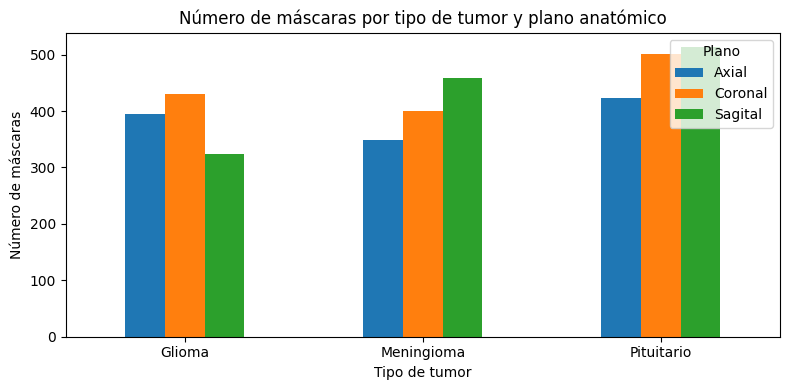

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
pivot_counts.plot(kind='bar', ax=ax)
ax.set_title('Número de máscaras por tipo de tumor y plano anatómico')
ax.set_xlabel('Tipo de tumor')
ax.set_ylabel('Número de máscaras')
ax.legend(title='Plano')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Caracterización morfológica de las máscaras reales

Se calculan el área relativa, el centroide, las dimensiones de la caja delimitadora y el número de componentes conexas.

In [9]:
def morphology_features_from_array(
    binary: np.ndarray,
) -> dict:

    binary = np.asarray(
        binary
    ).astype(bool)

    h, w = binary.shape

    ys, xs = np.where(
        binary
    )

    if len(xs) == 0:
        return {
            'area_fraction': 0.0,
            'centroid_x': np.nan,
            'centroid_y': np.nan,
            'bbox_w': 0.0,
            'bbox_h': 0.0,
            'n_components': 0,
        }

    x0, x1 = (
        xs.min(),
        xs.max(),
    )

    y0, y1 = (
        ys.min(),
        ys.max(),
    )

    structure = ndimage.generate_binary_structure(
        rank=2,
        connectivity=CFG.MASK_CONNECTIVITY,
    )

    _, n_components = ndimage.label(
        binary,
        structure=structure,
    )

    return {
        'area_fraction':
            float(binary.mean()),

        'centroid_x':
            float(
                xs.mean()
                / max(w - 1, 1)
            ),

        'centroid_y':
            float(
                ys.mean()
                / max(h - 1, 1)
            ),

        'bbox_w':
            float(
                (x1 - x0 + 1) / w
            ),

        'bbox_h':
            float(
                (y1 - y0 + 1) / h
            ),

        'n_components':
            int(n_components),
    }


def morphology_features_from_path(
    path_str: str,
) -> dict:

    arr = np.asarray(
        Image.open(
            path_str
        ).convert('L')
    )

    binary = (
        arr > CFG.MASK_THRESHOLD
    )

    return morphology_features_from_array(
        binary
    )


morph_rows = [
    morphology_features_from_path(p)
    for p in masks_df['path']
]

morph_df = pd.DataFrame(
    morph_rows
)

for col in [
    'area_fraction',
    'n_components',
]:
    masks_df[col] = (
        morph_df[col].values
    )

for col in [
    'centroid_x',
    'centroid_y',
    'bbox_w',
    'bbox_h',
]:
    masks_df[col] = (
        morph_df[col].values
    )

morph_cols = [
    'area_fraction',
    'centroid_x',
    'centroid_y',
    'bbox_w',
    'bbox_h',
    'n_components',
]

display(
    masks_df[
        morph_cols
    ].describe()
)


,area_fraction,centroid_x,centroid_y,bbox_w,bbox_h,n_components
count,3792.000000,3792.000000,3792.000000,3792.000000,3792.000000,3792.000000
mean,0.015682,0.496073,0.462691,0.152013,0.148971,1.056171
std,0.012422,0.098772,0.117724,0.063200,0.067332,0.260387
min,0.000088,0.214109,0.123964,0.009766,0.023438,1.000000
25%,0.007113,0.426927,0.381009,0.107422,0.099609,1.000000
50%,0.012331,0.498422,0.465283,0.142578,0.138672,1.000000
75%,0.020200,0.562579,0.553231,0.185547,0.183594,1.000000
max,0.094170,0.795795,0.789720,0.549020,0.572266,4.000000


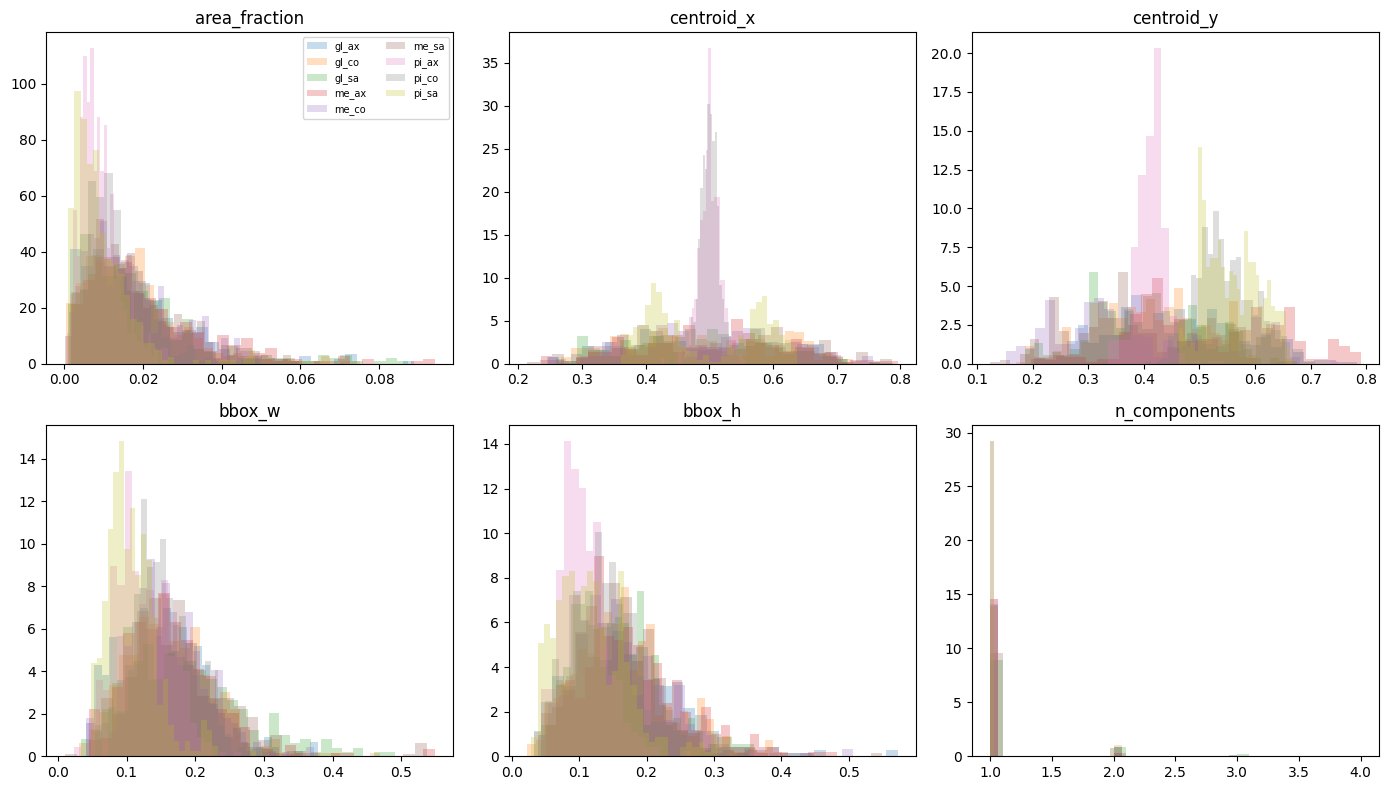

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for ax, col in zip(axes, morph_cols):
    for cond, g in masks_df.groupby('condition'):
        ax.hist(g[col].dropna(), bins=30, alpha=0.25, density=True, label=cond)
    ax.set_title(col)

axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()


## 6. Particiones de entrenamiento y validación

Se utiliza BRISC train para el entrenamiento y se divide BRISC test en validación y test final mediante una partición estratificada y reproducible.

In [11]:
def create_or_load_shared_test_split(
    official_test_df: pd.DataFrame,
    split_csv: Path,
    validation_fraction: float,
    random_state: int,
):
    split_csv.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    expected_names = set(
        official_test_df['basename']
    )

    if split_csv.exists():
        split_df = pd.read_csv(
            split_csv
        )

        required = {
            'basename',
            'tumor_code',
            'plane_code',
            'condition',
            'split',
        }

        missing_columns = (
            required
            - set(split_df.columns)
        )

        if missing_columns:
            raise RuntimeError(
                'El CSV de partición existente no '
                f'contiene: {sorted(missing_columns)}'
            )

        found_names = set(
            split_df['basename']
        )

        if found_names != expected_names:
            raise RuntimeError(
                'El CSV de partición existente no '
                'coincide exactamente con BRISC test. '
                'Revíselo antes de continuar.'
            )

        if not set(
            split_df['split'].unique()
        ).issubset(
            {'validation', 'test_final'}
        ):
            raise RuntimeError(
                'El CSV contiene etiquetas de split '
                'no reconocidas.'
            )

        print(
            'Se reutiliza la partición existente:'
        )
        print(split_csv)

        return split_df

    val_part, final_test_part = train_test_split(
        official_test_df.copy(),
        test_size=(1.0 - validation_fraction),
        random_state=random_state,
        stratify=official_test_df['condition'],
        shuffle=True,
    )

    val_part = val_part.copy()
    final_test_part = final_test_part.copy()

    val_part['split'] = 'validation'
    final_test_part['split'] = 'test_final'

    keep_cols = [
        'basename',
        'index',
        'tumor_code',
        'tumor',
        'plane_code',
        'plane',
        'condition',
        'split',
    ]

    split_df = pd.concat(
        [
            val_part[keep_cols],
            final_test_part[keep_cols],
        ],
        ignore_index=True,
    ).sort_values(
        ['split', 'condition', 'basename']
    ).reset_index(
        drop=True
    )

    split_df['random_state'] = random_state
    split_df['validation_fraction'] = validation_fraction

    split_df.to_csv(
        split_csv,
        index=False,
    )

    print(
        'Partición creada y guardada en:'
    )
    print(split_csv)

    return split_df


shared_test_split_df = create_or_load_shared_test_split(
    test_df,
    COMMON_SPLIT_CSV,
    CFG.VALIDATION_FRACTION,
    CFG.TEST_SPLIT_RANDOM_STATE,
)

validation_names = set(
    shared_test_split_df.loc[
        shared_test_split_df['split'] == 'validation',
        'basename',
    ]
)

final_test_names = set(
    shared_test_split_df.loc[
        shared_test_split_df['split'] == 'test_final',
        'basename',
    ]
)

train_df = masks_df.reset_index(
    drop=True
).copy()

val_df = test_df.loc[
    test_df['basename'].isin(
        validation_names
    )
].reset_index(
    drop=True
).copy()

final_test_df = test_df.loc[
    test_df['basename'].isin(
        final_test_names
    )
].reset_index(
    drop=True
).copy()

print('Entrenamiento:', len(train_df))
print('Validación:', len(val_df))
print('Test final reservado:', len(final_test_df))

split_summary = pd.concat(
    [
        train_df.groupby('condition').size().rename('train'),
        val_df.groupby('condition').size().rename('validation'),
        final_test_df.groupby('condition').size().rename('test_final'),
    ],
    axis=1,
).fillna(0).astype(int)

display(split_summary)

train_df.to_csv(
    TABLE_DIR / 'split_train.csv',
    index=False,
)
val_df.to_csv(
    TABLE_DIR / 'split_validation.csv',
    index=False,
)
final_test_df.to_csv(
    TABLE_DIR / 'split_test_final_reservado.csv',
    index=False,
)


Se reutiliza la partición existente:
K:\Tesis\Github\results\OE2\particiones\brisc_test_validation_test_50_50.csv
Entrenamiento: 3792
Validación: 420
Test final reservado: 420


,train,validation,test_final
condition,,,
gl_ax,394,42,42
gl_co,430,40,40
gl_sa,323,44,44
me_ax,348,62,62
me_co,400,40,41
me_sa,458,42,41
pi_ax,424,62,62
pi_co,502,45,45
pi_sa,513,43,43


## 7. Región efectiva y preparación de los datos

Se define $R_i$ como el complemento de las componentes de intensidad $\leq 15$ conectadas al borde. La región se emplea en la ponderación de la pérdida, sin modificar las máscaras binarias.

In [12]:
TUMOR_TO_ID = {'gl': 0, 'me': 1, 'pi': 2}
PLANE_TO_ID = {'ax': 0, 'co': 1, 'sa': 2}
ID_TO_TUMOR = {v: k for k, v in TUMOR_TO_ID.items()}
ID_TO_PLANE = {v: k for k, v in PLANE_TO_ID.items()}
VALID_EXTENSIONS = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}


def build_image_index(image_dir: Path):
    if not image_dir.exists():
        raise FileNotFoundError(
            f'No existe la carpeta de imágenes: {image_dir}'
        )

    return {
        p.stem: p
        for p in sorted(image_dir.iterdir())
        if p.is_file()
        and p.suffix.lower() in VALID_EXTENSIONS
    }


train_image_index = build_image_index(
    TRAIN_IMAGE_DIR
)

test_image_index = build_image_index(
    TEST_IMAGE_DIR
)


def attach_image_paths(
    df: pd.DataFrame,
    image_index: dict,
    split_name: str,
):
    df = df.copy()

    missing_mask = ~df['basename'].isin(
        image_index
    )

    if missing_mask.any():
        missing = df.loc[
            missing_mask,
            'basename',
        ].tolist()[:10]

        raise RuntimeError(
            f'Faltan imágenes para {split_name}. '
            f'Ejemplos: {missing}'
        )

    df['image_path'] = df[
        'basename'
    ].map(
        lambda name: str(
            image_index[name]
        )
    )

    return df


train_df = attach_image_paths(
    train_df,
    train_image_index,
    'train',
)

val_df = attach_image_paths(
    val_df,
    test_image_index,
    'validation',
)

final_test_df = attach_image_paths(
    final_test_df,
    test_image_index,
    'test_final',
)


### 7.1 Construcción y almacenamiento de la región efectiva

Se calcula y almacena la región válida para los conjuntos de entrenamiento y validación.

In [13]:
def compute_valid_region_oe1(
    image_path: str | Path,
    threshold: int,
    connectivity: int = 2,
):
    image = Image.open(
        image_path
    ).convert('L')

    array = np.asarray(
        image,
        dtype=np.uint8,
    )

    low_intensity = (
        array <= threshold
    )

    border_seed = np.zeros_like(
        low_intensity,
        dtype=bool,
    )

    border_seed[0, :] = low_intensity[0, :]
    border_seed[-1, :] = low_intensity[-1, :]
    border_seed[:, 0] |= low_intensity[:, 0]
    border_seed[:, -1] |= low_intensity[:, -1]

    structure = ndimage.generate_binary_structure(
        rank=2,
        connectivity=connectivity,
    )

    external_background = ndimage.binary_propagation(
        border_seed,
        structure=structure,
        mask=low_intensity,
    )

    valid_region = ~external_background

    return valid_region.astype(
        np.uint8
    )


def ensure_valid_region_cache(
    df: pd.DataFrame,
    cache_dir: Path,
):
    cache_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    output_paths = []
    created = 0
    reused = 0

    for row in df.itertuples(
        index=False
    ):
        output_path = (
            cache_dir
            / f'{row.basename}.png'
        )

        if not output_path.exists():
            region = compute_valid_region_oe1(
                row.image_path,
                threshold=CFG.INTENSITY_THRESHOLD,
                connectivity=CFG.ROI_CONNECTIVITY,
            )

            Image.fromarray(
                region * 255,
                mode='L',
            ).save(
                output_path
            )

            created += 1
        else:
            reused += 1

        output_paths.append(
            str(output_path)
        )

    result = df.copy()
    result['valid_region_path'] = output_paths

    print(
        f'{cache_dir.name}: '
        f'{created} regiones creadas, '
        f'{reused} reutilizadas.'
    )

    return result


# Se precomputa una vez para todo BRISC train y todo BRISC test.
train_df = ensure_valid_region_cache(
    train_df,
    ROI_CACHE_TRAIN_DIR,
)

all_test_with_images = attach_image_paths(
    test_df,
    test_image_index,
    'BRISC test completo',
)

all_test_with_regions = ensure_valid_region_cache(
    all_test_with_images,
    ROI_CACHE_TEST_DIR,
)

test_region_lookup = (
    all_test_with_regions
    .set_index('basename')[
        'valid_region_path'
    ]
    .to_dict()
)

val_df['valid_region_path'] = val_df[
    'basename'
].map(
    test_region_lookup
)

final_test_df['valid_region_path'] = final_test_df[
    'basename'
].map(
    test_region_lookup
)


def load_cached_valid_region(
    path_str: str,
    image_size: int,
):
    roi_image = Image.open(
        path_str
    ).convert('L')

    if roi_image.size != (
        image_size,
        image_size,
    ):
        roi_image = roi_image.resize(
            (image_size, image_size),
            resample=Image.Resampling.NEAREST,
        )

    return (
        np.asarray(roi_image) > 0
    ).astype(np.float32)


train: 0 regiones creadas, 3792 reutilizadas.
test: 0 regiones creadas, 840 reutilizadas.


### 7.2 Conjuntos de datos y cargadores

Se preparan los lotes de máscaras binarias y regiones válidas para el entrenamiento y la validación.

In [14]:
class BRISCMaskDataset(Dataset):
    def __init__(
        self,
        df: pd.DataFrame,
        image_size: int,
    ):
        self.df = (
            df.reset_index(
                drop=True
            ).copy()
        )
        self.image_size = image_size

    def __len__(self):
        return len(self.df)

    def __getitem__(
        self,
        idx: int,
    ):
        row = self.df.iloc[idx]

        img = Image.open(
            row['path']
        ).convert('L')

        img = img.resize(
            (
                self.image_size,
                self.image_size,
            ),
            resample=Image.Resampling.NEAREST,
        )

        arr = (
            np.asarray(img)
            > CFG.MASK_THRESHOLD
        ).astype(np.float32)

        y = torch.from_numpy(
            arr
        ).unsqueeze(0)

        roi = load_cached_valid_region(
            row['valid_region_path'],
            self.image_size,
        )

        valid_mask = torch.from_numpy(
            roi
        ).unsqueeze(0)

        tumor_id = torch.tensor(
            TUMOR_TO_ID[
                row['tumor_code']
            ],
            dtype=torch.long,
        )

        plane_id = torch.tensor(
            PLANE_TO_ID[
                row['plane_code']
            ],
            dtype=torch.long,
        )

        return {
            'mask': y,
            'valid_mask': valid_mask,
            'tumor_id': tumor_id,
            'plane_id': plane_id,
            'basename': row['basename'],
        }


train_ds = BRISCMaskDataset(
    train_df,
    CFG.IMAGE_SIZE,
)

val_ds = BRISCMaskDataset(
    val_df,
    CFG.IMAGE_SIZE,
)

train_loader = DataLoader(
    train_ds,
    batch_size=CFG.BATCH_SIZE,
    shuffle=True,
    num_workers=CFG.NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=True,
)

val_loader = DataLoader(
    val_ds,
    batch_size=CFG.BATCH_SIZE,
    shuffle=False,
    num_workers=CFG.NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
)

batch = next(iter(train_loader))

print('Forma de batch:', batch['mask'].shape)
print(
    'Rango de máscara:',
    batch['mask'].min().item(),
    batch['mask'].max().item(),
)
print(
    'Valores únicos:',
    torch.unique(batch['mask']).tolist(),
)
print('Forma de valid_mask:', batch['valid_mask'].shape)
print(
    'Fracción media de R_i:',
    batch['valid_mask'].float().mean().item(),
)
print('Tumor IDs:', batch['tumor_id'][:8].tolist())
print('Plano IDs:', batch['plane_id'][:8].tolist())


Forma de batch: torch.Size([6, 1, 256, 256])
Rango de máscara: 0.0 1.0
Valores únicos: [0.0, 1.0]
Forma de valid_mask: torch.Size([6, 1, 256, 256])
Fracción media de R_i: 0.5660298466682434
Tumor IDs: [2, 2, 0, 2, 2, 2]
Plano IDs: [0, 0, 1, 0, 2, 1]


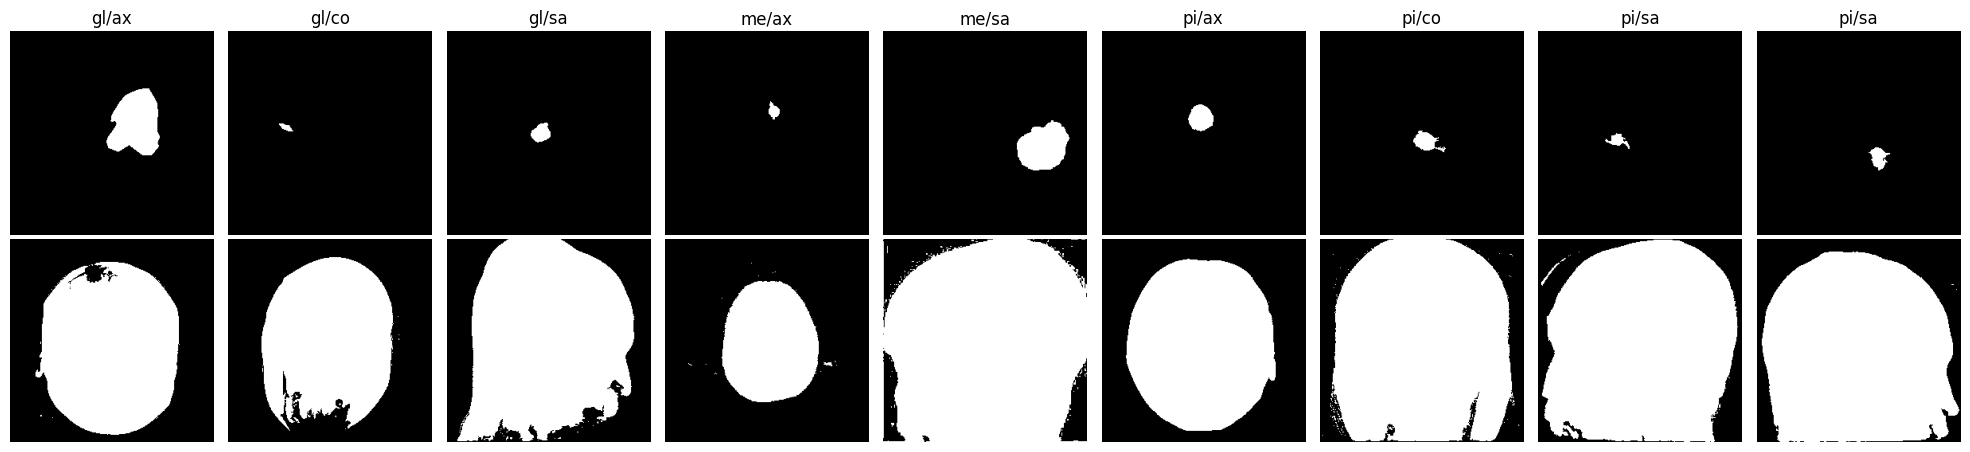

In [15]:
def show_dataset_examples(
    dataset,
    n=9,
):
    n = min(
        n,
        len(dataset)
    )

    idxs = np.linspace(
        0,
        len(dataset) - 1,
        n,
        dtype=int,
    )

    fig, axes = plt.subplots(
        2,
        n,
        figsize=(2.2 * n, 4.6),
    )

    for col, idx in enumerate(idxs):
        item = dataset[idx]

        mask = (
            item['mask']
            .squeeze()
            .numpy()
        )

        roi = (
            item['valid_mask']
            .squeeze()
            .numpy()
        )

        tumor = ID_TO_TUMOR[
            int(item['tumor_id'])
        ]

        plane = ID_TO_PLANE[
            int(item['plane_id'])
        ]

        axes[0, col].imshow(
            mask,
            cmap='gray',
            vmin=0,
            vmax=1,
        )

        axes[0, col].set_title(
            f'{tumor}/{plane}'
        )

        axes[1, col].imshow(
            roi,
            cmap='gray',
            vmin=0,
            vmax=1,
        )

        axes[0, col].axis('off')
        axes[1, col].axis('off')

    axes[0, 0].set_ylabel(
        'Máscara'
    )

    axes[1, 0].set_ylabel(
        'Región $R_i$'
    )

    plt.tight_layout()
    plt.show()


show_dataset_examples(
    train_ds,
    n=9,
)


## 8. Proceso de difusión Bernoulli

Se implementa el calendario de ruido y las transiciones del proceso directo mediante perturbaciones Bernoulli y la operación XOR.

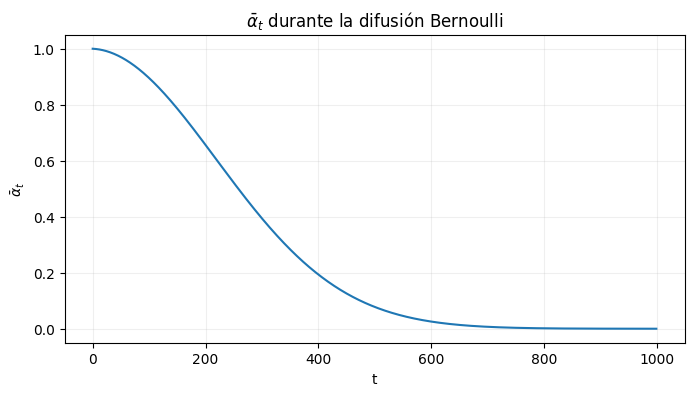

P(flip) en el último timestep: 0.4999798208511731


In [16]:
def linear_beta_schedule(
    timesteps: int,
    beta_start: float,
    beta_end: float,
):
    # Escalado habitual para conservar aproximadamente el mismo calendario
    # si el perfil de desarrollo usa menos de 1000 pasos.
    scale = 1000.0 / timesteps

    return torch.linspace(
        scale * beta_start,
        scale * beta_end,
        timesteps,
        dtype=torch.float64,
    ).clamp(
        min=1e-8,
        max=0.999
    )


betas = linear_beta_schedule(
    CFG.TIMESTEPS,
    CFG.BETA_START,
    CFG.BETA_END,
)

alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(
    alphas,
    dim=0
)

alphas_cumprod_prev = torch.cat(
    [
        torch.ones(1, dtype=torch.float64),
        alphas_cumprod[:-1],
    ]
)

DIFF = {
    'betas': betas.to(DEVICE, dtype=torch.float32),
    'alphas': alphas.to(DEVICE, dtype=torch.float32),
    'alphas_cumprod': alphas_cumprod.to(
        DEVICE,
        dtype=torch.float32
    ),
    'alphas_cumprod_prev': alphas_cumprod_prev.to(
        DEVICE,
        dtype=torch.float32
    ),
}

plt.figure(figsize=(8, 4))
plt.plot(alphas_cumprod.cpu().numpy())
plt.title(r'$\bar{\alpha}_t$ durante la difusión Bernoulli')
plt.xlabel('t')
plt.ylabel(r'$\bar{\alpha}_t$')
plt.grid(alpha=0.2)
plt.show()

print(
    'P(flip) en el último timestep:',
    float((1.0 - alphas_cumprod[-1]) / 2.0)
)


In [17]:
def extract(a: torch.Tensor, t: torch.Tensor, x_shape):
    """Extrae a[t] y lo adapta para broadcasting sobre [B,C,H,W]."""
    b = t.shape[0]
    out = a.gather(-1, t)

    return out.reshape(
        b,
        *((1,) * (len(x_shape) - 1))
    )


def bernoulli_flip_probability(
    t: torch.Tensor,
    x_shape,
):
    alpha_bar_t = extract(
        DIFF['alphas_cumprod'],
        t,
        x_shape,
    )

    return (
        1.0 - alpha_bar_t
    ) / 2.0


def q_sample(
    y0: torch.Tensor,
    t: torch.Tensor,
    noise: torch.Tensor | None = None,
    return_noise: bool = False,
):
    """Muestrea y_t mediante XOR con ruido Bernoulli."""
    flip_prob = bernoulli_flip_probability(
        t,
        y0.shape,
    ).expand_as(y0)

    if noise is None:
        noise = torch.bernoulli(
            flip_prob
        )
    else:
        # noise puede proporcionarse como uniforme U(0,1) reproducible.
        if noise.dtype.is_floating_point:
            noise = (
                noise < flip_prob
            ).float()
        else:
            noise = noise.float()

    yt = torch.remainder(
        y0 + noise,
        2.0,
    )

    if return_noise:
        return yt, noise

    return yt


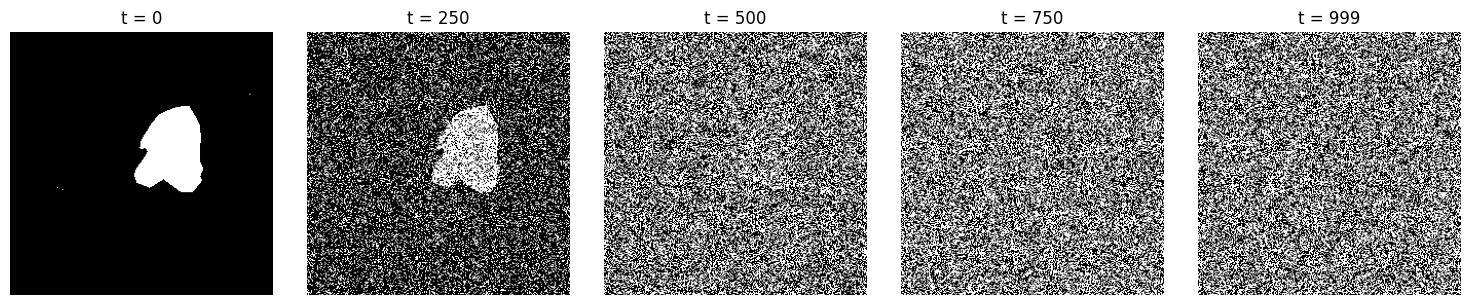

In [18]:
# Visualización del proceso directo sobre una máscara real
x0 = train_ds[0]['mask'].unsqueeze(0).to(DEVICE)
steps_to_show = [0, CFG.TIMESTEPS // 4, CFG.TIMESTEPS // 2, 3 * CFG.TIMESTEPS // 4, CFG.TIMESTEPS - 1]

fig, axes = plt.subplots(1, len(steps_to_show), figsize=(15, 3))
for ax, step in zip(axes, steps_to_show):
    t = torch.tensor([step], device=DEVICE, dtype=torch.long)
    xt = q_sample(x0, t)
    ax.imshow(xt[0, 0].detach().cpu(), cmap='gray')
    ax.set_title(f't = {step}')
    ax.axis('off')
plt.tight_layout()
plt.show()


## 9. Arquitectura U-Net condicionada

Se define la red neuronal que estima el ruido Bernoulli a partir de la máscara perturbada, el instante de difusión y las condiciones categóricas.

In [19]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, time: torch.Tensor):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / max(half_dim - 1, 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time.float()[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=1)
        return embeddings


class ResidualBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, emb_dim: int, groups: int = 8, dropout: float = 0.0):
        super().__init__()
        self.norm1 = nn.GroupNorm(min(groups, in_ch), in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)

        self.emb_proj = nn.Sequential(
            nn.SiLU(),
            nn.Linear(emb_dim, out_ch),
        )

        self.norm2 = nn.GroupNorm(min(groups, out_ch), out_ch)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)

        self.residual = nn.Identity() if in_ch == out_ch else nn.Conv2d(in_ch, out_ch, 1)

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb_proj(emb)[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.residual(x)


class SelfAttention2d(nn.Module):
    def __init__(self, channels: int, heads: int = 4):
        super().__init__()
        self.norm = nn.GroupNorm(8, channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)

    def forward(self, x):
        b, c, h, w = x.shape
        y = self.norm(x).reshape(b, c, h * w).transpose(1, 2)  # [B, HW, C]
        y, _ = self.attn(y, y, y, need_weights=False)
        y = y.transpose(1, 2).reshape(b, c, h, w)
        return x + y


class Downsample(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 4, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, 3, padding=1)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        return self.conv(x)


class ConditionalUNet(nn.Module):
    """
    U-Net para estimar logits de P(epsilon=1 | y_t, t, tumor, plano).
    """
    def __init__(self, in_channels=1, base_channels=64, emb_dim=256):
        super().__init__()
        b = base_channels
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(emb_dim),
            nn.Linear(emb_dim, emb_dim),
            nn.SiLU(),
            nn.Linear(emb_dim, emb_dim),
        )
        self.tumor_emb = nn.Embedding(3, emb_dim)
        self.plane_emb = nn.Embedding(3, emb_dim)

        self.in_conv = nn.Conv2d(in_channels, b, 3, padding=1)

        self.down1 = ResidualBlock(b, b, emb_dim)
        self.ds1 = Downsample(b)

        self.down2 = ResidualBlock(b, b * 2, emb_dim)
        self.ds2 = Downsample(b * 2)

        self.down3 = ResidualBlock(b * 2, b * 4, emb_dim)
        self.ds3 = Downsample(b * 4)

        self.down4 = ResidualBlock(b * 4, b * 8, emb_dim)
        self.ds4 = Downsample(b * 8)

        self.mid1 = ResidualBlock(b * 8, b * 8, emb_dim)
        self.mid_attn = SelfAttention2d(b * 8, heads=4)
        self.mid2 = ResidualBlock(b * 8, b * 8, emb_dim)

        self.us4 = Upsample(b * 8, b * 8)
        self.up4 = ResidualBlock(b * 16, b * 8, emb_dim)

        self.us3 = Upsample(b * 8, b * 4)
        self.up3 = ResidualBlock(b * 8, b * 4, emb_dim)

        self.us2 = Upsample(b * 4, b * 2)
        self.up2 = ResidualBlock(b * 4, b * 2, emb_dim)

        self.us1 = Upsample(b * 2, b)
        self.up1 = ResidualBlock(b * 2, b, emb_dim)

        self.out_norm = nn.GroupNorm(8, b)
        self.out_conv = nn.Conv2d(b, in_channels, 3, padding=1)

    def condition_embedding(self, t, tumor_id, plane_id):
        t_emb = self.time_mlp(t)
        c_emb = self.tumor_emb(tumor_id) + self.plane_emb(plane_id)
        return t_emb + c_emb

    def forward(self, x, t, tumor_id, plane_id):
        emb = self.condition_embedding(t, tumor_id, plane_id)

        x = self.in_conv(x)

        h1 = self.down1(x, emb)
        x = self.ds1(h1)

        h2 = self.down2(x, emb)
        x = self.ds2(h2)

        h3 = self.down3(x, emb)
        x = self.ds3(h3)

        h4 = self.down4(x, emb)
        x = self.ds4(h4)

        x = self.mid1(x, emb)
        x = self.mid_attn(x)
        x = self.mid2(x, emb)

        x = self.us4(x)
        x = self.up4(torch.cat([x, h4], dim=1), emb)

        x = self.us3(x)
        x = self.up3(torch.cat([x, h3], dim=1), emb)

        x = self.us2(x)
        x = self.up2(torch.cat([x, h2], dim=1), emb)

        x = self.us1(x)
        x = self.up1(torch.cat([x, h1], dim=1), emb)

        return self.out_conv(F.silu(self.out_norm(x)))


In [20]:
model = ConditionalUNet(
    in_channels=1,
    base_channels=CFG.BASE_CHANNELS,
    emb_dim=CFG.TIME_EMB_DIM,
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
print(f'Parámetros: {n_params:,} ({n_params/1e6:.2f} M)')

# Prueba de forma antes de entrenar
with torch.no_grad():
    b = min(2, CFG.BATCH_SIZE)
    x_test = torch.randn(b, 1, CFG.IMAGE_SIZE, CFG.IMAGE_SIZE, device=DEVICE)
    t_test = torch.randint(0, CFG.TIMESTEPS, (b,), device=DEVICE)
    tumor_test = torch.randint(0, 3, (b,), device=DEVICE)
    plane_test = torch.randint(0, 3, (b,), device=DEVICE)
    y_test = model(x_test, t_test, tumor_test, plane_test)

print('Entrada:', tuple(x_test.shape))
print('Salida :', tuple(y_test.shape))
assert y_test.shape == x_test.shape

del x_test, y_test, t_test, tumor_test, plane_test
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Parámetros: 35,867,777 (35.87 M)
Entrada: (2, 1, 256, 256)
Salida : (2, 1, 256, 256)


## 10. Función objetivo ponderada

Se combina el término variacional de la difusión Bernoulli con una pérdida auxiliar de entropía cruzada, utilizando pesos espaciales definidos por $R_i$.

In [21]:
def bernoulli_posterior_prob(
    yt: torch.Tensor,
    y0_prob: torch.Tensor,
    t: torch.Tensor,
):
    alpha_t = extract(
        DIFF['alphas'],
        t,
        yt.shape,
    )

    alpha_bar_prev = extract(
        DIFF['alphas_cumprod_prev'],
        t,
        yt.shape,
    )

    transition_to_zero = (
        alpha_t * (1.0 - yt)
        + (1.0 - alpha_t) / 2.0
    )

    transition_to_one = (
        alpha_t * yt
        + (1.0 - alpha_t) / 2.0
    )

    prior_zero = (
        alpha_bar_prev
        * (1.0 - y0_prob)
        + (1.0 - alpha_bar_prev) / 2.0
    )

    prior_one = (
        alpha_bar_prev * y0_prob
        + (1.0 - alpha_bar_prev) / 2.0
    )

    theta_zero = (
        transition_to_zero
        * prior_zero
    )

    theta_one = (
        transition_to_one
        * prior_one
    )

    posterior = theta_one / (
        theta_zero
        + theta_one
    ).clamp(
        min=CFG.PROB_EPS
    )

    return posterior.clamp(
        CFG.PROB_EPS,
        1.0 - CFG.PROB_EPS,
    )


def bernoulli_kl(
    q_prob: torch.Tensor,
    p_prob: torch.Tensor,
):
    q = q_prob.clamp(
        CFG.PROB_EPS,
        1.0 - CFG.PROB_EPS,
    )

    p = p_prob.clamp(
        CFG.PROB_EPS,
        1.0 - CFG.PROB_EPS,
    )

    return (
        q * (
            torch.log(q)
            - torch.log(p)
        )
        + (1.0 - q)
        * (
            torch.log(1.0 - q)
            - torch.log(1.0 - p)
        )
    )


def weighted_mean_per_sample(
    values: torch.Tensor,
    valid_mask: torch.Tensor,
):
    weights = (
        valid_mask
        + CFG.ROI_OUTSIDE_WEIGHT
        * (1.0 - valid_mask)
    ).to(
        dtype=values.dtype
    )

    numerator = (
        values * weights
    ).flatten(1).sum(1)

    denominator = (
        weights
        .flatten(1)
        .sum(1)
        .clamp(min=1e-8)
    )

    return (
        numerator
        / denominator
    )


def berdiff_components(
    model,
    y0,
    tumor_id,
    plane_id,
    valid_mask,
    t=None,
):
    b = y0.shape[0]

    if t is None:
        t = torch.randint(
            0,
            CFG.TIMESTEPS,
            (b,),
            device=y0.device,
            dtype=torch.long,
        )

    yt, epsilon = q_sample(
        y0,
        t,
        return_noise=True,
    )

    epsilon_logits = model(
        yt,
        t,
        tumor_id,
        plane_id,
    )

    epsilon_prob = torch.sigmoid(
        epsilon_logits
    )

    pred_y0_prob = torch.abs(
        yt - epsilon_prob
    ).clamp(
        0.0,
        1.0,
    )

    true_posterior = (
        bernoulli_posterior_prob(
            yt,
            y0,
            t,
        )
    )

    pred_posterior = (
        bernoulli_posterior_prob(
            yt,
            pred_y0_prob,
            t,
        )
    )

    kl_map = bernoulli_kl(
        true_posterior,
        pred_posterior,
    )

    kl_per_sample = (
        weighted_mean_per_sample(
            kl_map,
            valid_mask,
        )
    )

    decoder_map = (
        F.binary_cross_entropy(
            pred_y0_prob.clamp(
                CFG.PROB_EPS,
                1.0 - CFG.PROB_EPS,
            ),
            y0,
            reduction='none',
        )
    )

    decoder_nll = (
        weighted_mean_per_sample(
            decoder_map,
            valid_mask,
        )
    )

    vb_per_sample = torch.where(
        t == 0,
        decoder_nll,
        kl_per_sample,
    )

    bce_map = (
        F.binary_cross_entropy_with_logits(
            epsilon_logits,
            epsilon,
            reduction='none',
        )
    )

    bce_per_sample = (
        weighted_mean_per_sample(
            bce_map,
            valid_mask,
        )
    )

    total_per_sample = (
        vb_per_sample
        + CFG.LAMBDA_BCE
        * bce_per_sample
    )

    return {
        'loss': total_per_sample.mean(),
        'total_per_sample': total_per_sample,
        'vb_per_sample': vb_per_sample,
        'bce_per_sample': bce_per_sample,
        'epsilon_logits': epsilon_logits,
        'epsilon_prob': epsilon_prob,
        'epsilon': epsilon,
        'yt': yt,
        'pred_y0_prob': pred_y0_prob,
        't': t,
    }


def diffusion_loss(
    model,
    y0,
    tumor_id,
    plane_id,
    valid_mask,
):
    return berdiff_components(
        model,
        y0,
        tumor_id,
        plane_id,
        valid_mask,
    )['loss']


## 11. Media móvil exponencial y utilidades

Se implementan la actualización EMA, el control numérico y las funciones auxiliares del entrenamiento.

In [22]:
class EMA:
    def __init__(self, model: nn.Module, decay: float = 0.9999):
        self.decay = decay
        self.ema_model = deepcopy(model).eval()
        self.num_updates = 0
        for p in self.ema_model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model: nn.Module):
        self.num_updates += 1

        ema_params = dict(self.ema_model.named_parameters())
        model_params = dict(model.named_parameters())
        for name, param in model_params.items():
            ema_params[name].mul_(self.decay).add_(param.data, alpha=1.0 - self.decay)

        ema_buffers = dict(self.ema_model.named_buffers())
        model_buffers = dict(model.named_buffers())
        for name, buf in model_buffers.items():
            ema_buffers[name].copy_(buf)


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CFG.LR,
    weight_decay=CFG.WEIGHT_DECAY,
)

ema = EMA(model, decay=CFG.EMA_DECAY)

USE_AMP = bool(CFG.USE_AMP and DEVICE.type == 'cuda')

try:
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


def autocast_context():
    if not USE_AMP:
        return nullcontext()
    try:
        return torch.amp.autocast(device_type='cuda', dtype=torch.float16)
    except Exception:
        return torch.cuda.amp.autocast(dtype=torch.float16)


print('Learning rate:', CFG.LR)
print('AMP activo:', USE_AMP)
print('EMA decay:', CFG.EMA_DECAY)


Learning rate: 0.0001
AMP activo: False
EMA decay: 0.9999


## 12. Muestreo inverso Bernoulli

Se construyen máscaras sintéticas a partir de ruido Bernoulli mediante las probabilidades de transición estimadas por el modelo.

In [23]:
@torch.no_grad()
def predicted_y0_probability(
    model,
    yt,
    t,
    tumor_id,
    plane_id,
):
    epsilon_logits = model(
        yt,
        t,
        tumor_id,
        plane_id,
    )

    epsilon_prob = torch.sigmoid(
        epsilon_logits
    )

    pred_y0_prob = torch.abs(
        yt - epsilon_prob
    ).clamp(
        0.0,
        1.0,
    )

    return pred_y0_prob, epsilon_prob


def skipped_posterior_prob(
    yt,
    y0_prob,
    alpha_effective,
    alpha_bar_previous,
):
    transition_to_zero = (
        alpha_effective * (1.0 - yt)
        + (1.0 - alpha_effective) / 2.0
    )

    transition_to_one = (
        alpha_effective * yt
        + (1.0 - alpha_effective) / 2.0
    )

    prior_zero = (
        alpha_bar_previous * (1.0 - y0_prob)
        + (1.0 - alpha_bar_previous) / 2.0
    )

    prior_one = (
        alpha_bar_previous * y0_prob
        + (1.0 - alpha_bar_previous) / 2.0
    )

    theta_zero = transition_to_zero * prior_zero
    theta_one = transition_to_one * prior_one

    posterior = theta_one / (
        theta_zero + theta_one
    ).clamp(
        min=CFG.PROB_EPS
    )

    return posterior.clamp(
        CFG.PROB_EPS,
        1.0 - CFG.PROB_EPS,
    )


def make_sampling_timesteps(
    total_steps: int,
    sampling_steps: int,
):
    if sampling_steps >= total_steps:
        return np.arange(
            total_steps,
            dtype=int,
        )

    selected = np.linspace(
        0,
        total_steps - 1,
        sampling_steps,
        dtype=int,
    )

    selected = np.unique(selected)

    if selected[-1] != total_steps - 1:
        selected = np.append(
            selected,
            total_steps - 1,
        )

    return selected


@torch.no_grad()
def sample_bernoulli(
    model,
    tumor_id,
    plane_id,
    image_size: int,
    sampling_steps: int,
    initial_noise: torch.Tensor | None = None,
    return_probability: bool = False,
):
    model.eval()
    device = next(
        model.parameters()
    ).device

    tumor_id = torch.as_tensor(
        tumor_id,
        dtype=torch.long,
        device=device,
    ).flatten()

    plane_id = torch.as_tensor(
        plane_id,
        dtype=torch.long,
        device=device,
    ).flatten()

    if tumor_id.shape != plane_id.shape:
        raise ValueError(
            'tumor_id y plane_id deben tener el mismo tamaño.'
        )

    b = tumor_id.shape[0]

    shape = (
        b,
        1,
        image_size,
        image_size,
    )

    if initial_noise is None:
        yt = torch.bernoulli(
            torch.full(
                shape,
                0.5,
                device=device,
            )
        )
    else:
        if tuple(initial_noise.shape) != shape:
            raise ValueError(
                f'initial_noise debe tener forma {shape}.'
            )

        yt = initial_noise.to(
            device=device,
            dtype=torch.float32,
        ).clone()

    selected = make_sampling_timesteps(
        CFG.TIMESTEPS,
        sampling_steps,
    )

    alpha_bars = DIFF[
        'alphas_cumprod'
    ]

    final_probability = None

    for k in range(
        len(selected) - 1,
        -1,
        -1,
    ):
        current_t = int(
            selected[k]
        )

        t_tensor = torch.full(
            (b,),
            current_t,
            device=device,
            dtype=torch.long,
        )

        pred_y0_prob, _ = predicted_y0_probability(
            model,
            yt,
            t_tensor,
            tumor_id,
            plane_id,
        )

        if not torch.isfinite(
            pred_y0_prob
        ).all():
            raise RuntimeError(
                f'Probabilidad no finita durante muestreo en t={current_t}.'
            )

        if k == 0:
            final_probability = pred_y0_prob.clamp(
                0.0,
                1.0,
            )

            yt = (
                final_probability
                >= CFG.THRESHOLD
            ).float()

            break

        previous_t = int(
            selected[k - 1]
        )

        alpha_bar_current = alpha_bars[
            current_t
        ]

        alpha_bar_previous = alpha_bars[
            previous_t
        ]

        alpha_effective = (
            alpha_bar_current
            / alpha_bar_previous
        ).clamp(
            CFG.PROB_EPS,
            1.0,
        )

        posterior_prob = skipped_posterior_prob(
            yt,
            pred_y0_prob,
            alpha_effective,
            alpha_bar_previous,
        )

        yt = torch.bernoulli(
            posterior_prob
        )

    if return_probability:
        return yt, final_probability

    return yt


def diffusion_output_to_probability(
    x: torch.Tensor,
):
    # En Bernoulli la salida ya representa máscara binaria o probabilidad.
    return x.clamp(0.0, 1.0)


def diffusion_output_to_binary(
    x: torch.Tensor,
    threshold: float = 0.5,
):
    return (
        x >= threshold
    ).to(torch.uint8)


## 13. Diagnóstico de reconstrucción

Se calculan las medidas de reconstrucción sobre las máscaras de validación y se fija el ruido para el monitoreo del entrenamiento.

In [24]:
def reconstruct_y0_from_noise_probability(
    yt: torch.Tensor,
    epsilon_prob: torch.Tensor,
):
    return torch.abs(
        yt - epsilon_prob
    ).clamp(
        0.0,
        1.0,
    )


def y0_mask_metrics(
    y0_true: torch.Tensor,
    y0_prob: torch.Tensor,
    valid_mask: torch.Tensor,
    threshold: float = 0.5,
):
    true_bin = (
        y0_true >= 0.5
    )

    pred_bin = (
        y0_prob >= threshold
    )

    roi = (
        valid_mask >= 0.5
    )

    dims = (1, 2, 3)
    eps = 1e-8

    true_roi = (
        true_bin & roi
    )

    pred_roi = (
        pred_bin & roi
    )

    intersection = (
        true_roi & pred_roi
    ).sum(
        dim=dims
    ).float()

    true_area = (
        true_roi
        .sum(dim=dims)
        .float()
    )

    pred_area = (
        pred_roi
        .sum(dim=dims)
        .float()
    )

    union = (
        (true_roi | pred_roi)
        .sum(dim=dims)
        .float()
    )

    valid_area = (
        roi.sum(
            dim=dims
        )
        .float()
        .clamp(min=1.0)
    )

    dice = (
        2.0 * intersection
        + eps
    ) / (
        true_area
        + pred_area
        + eps
    )

    iou = (
        intersection
        + eps
    ) / (
        union
        + eps
    )

    fg_real = (
        true_area
        / valid_area
    )

    fg_pred = (
        pred_area
        / valid_area
    )

    empty_pred = (
        pred_area == 0
    ).float()

    sq_error = (
        y0_prob - y0_true
    ).pow(2)

    true_fg = (
        true_bin & roi
    ).float()

    true_bg = (
        (~true_bin) & roi
    ).float()

    fg_mse = (
        (sq_error * true_fg)
        .sum(dim=dims)
        / true_fg.sum(
            dim=dims
        ).clamp(min=1.0)
    )

    bg_mse = (
        (sq_error * true_bg)
        .sum(dim=dims)
        / true_bg.sum(
            dim=dims
        ).clamp(min=1.0)
    )

    return {
        'dice': dice,
        'iou': iou,
        'fg_real': fg_real,
        'fg_pred': fg_pred,
        'empty_pred': empty_pred,
        'fg_mse': fg_mse,
        'bg_mse': bg_mse,
    }


def make_validation_generator(
    seed: int,
):
    if DEVICE.type == 'cuda':
        generator = torch.Generator(
            device=DEVICE
        )
    else:
        generator = torch.Generator()

    generator.manual_seed(seed)

    return generator


def make_fixed_monitor_noise(
    n: int,
    image_size: int,
    seed: int,
):
    generator = torch.Generator()
    generator.manual_seed(seed)

    return torch.bernoulli(
        torch.full(
            (
                n,
                1,
                image_size,
                image_size,
            ),
            0.5,
        ),
        generator=generator,
    )


FIXED_MONITOR_TUMOR_IDS = []
FIXED_MONITOR_PLANE_IDS = []
FIXED_MONITOR_LABELS = []

for tumor_code in [
    'gl',
    'me',
    'pi',
]:
    for plane_code in [
        'ax',
        'co',
        'sa',
    ]:
        FIXED_MONITOR_TUMOR_IDS.append(
            TUMOR_TO_ID[
                tumor_code
            ]
        )

        FIXED_MONITOR_PLANE_IDS.append(
            PLANE_TO_ID[
                plane_code
            ]
        )

        FIXED_MONITOR_LABELS.append(
            f'{tumor_code}/{plane_code}'
        )


FIXED_MONITOR_NOISE = (
    make_fixed_monitor_noise(
        n=9,
        image_size=CFG.IMAGE_SIZE,
        seed=CFG.MONITOR_SEED,
    )
)

torch.save(
    FIXED_MONITOR_NOISE,
    DIAGNOSTIC_DIR
    / 'fixed_monitor_noise.pt'
)

print(
    'Ruido Bernoulli fijo de monitoreo:',
    tuple(
        FIXED_MONITOR_NOISE.shape
    )
)


Ruido Bernoulli fijo de monitoreo: (9, 1, 256, 256)


## 14. Entrenamiento y validación

Se implementan las rutinas de optimización, validación, seguimiento de métricas y conservación de checkpoints.

In [25]:
def save_checkpoint(
    path: Path,
    epoch: int,
    model,
    ema,
    optimizer,
    scaler,
    history,
    best_val,
    best_dice,
):
    ckpt = {
        'epoch': epoch,
        'model_state': model.state_dict(),
        'ema_state': ema.ema_model.state_dict(),
        'ema_updates': ema.num_updates,
        'optimizer_state': optimizer.state_dict(),
        'scaler_state': scaler.state_dict(),
        'history': history,
        'best_val': best_val,
        'best_dice': best_dice,
        'config': asdict(CFG),
        'tumor_to_id': TUMOR_TO_ID,
        'plane_to_id': PLANE_TO_ID,
        'method': 'bernoulli',
        'profile': CFG.PROFILE,
    }

    torch.save(
        ckpt,
        path,
    )


@torch.no_grad()
def save_condition_grids(
    model_for_sampling,
    epoch: int,
    prefix: str,
):
    binary, probability = sample_bernoulli(
        model_for_sampling,
        tumor_id=FIXED_MONITOR_TUMOR_IDS,
        plane_id=FIXED_MONITOR_PLANE_IDS,
        image_size=CFG.IMAGE_SIZE,
        sampling_steps=CFG.MONITOR_SAMPLING_STEPS,
        initial_noise=FIXED_MONITOR_NOISE,
        return_probability=True,
    )

    binary_np = (
        binary
        .cpu()
        .numpy()
    )

    prob_np = (
        probability
        .cpu()
        .numpy()
    )

    fig, axes = plt.subplots(
        3,
        3,
        figsize=(9, 9),
    )

    for ax, prob, label in zip(
        axes.ravel(),
        prob_np,
        FIXED_MONITOR_LABELS,
    ):
        ax.imshow(
            prob[0],
            cmap='gray',
            vmin=0,
            vmax=1,
        )
        ax.set_title(label)
        ax.axis('off')

    fig.suptitle(
        f'Época {epoch} — probabilidad continua — {prefix}'
    )

    plt.tight_layout()

    fig.savefig(
        SAMPLE_DIR
        / f'{prefix}_prob_epoch_{epoch:03d}.png',
        dpi=140,
        bbox_inches='tight',
    )

    plt.close(fig)

    fig, axes = plt.subplots(
        3,
        3,
        figsize=(9, 9),
    )

    for ax, mask, label in zip(
        axes.ravel(),
        binary_np,
        FIXED_MONITOR_LABELS,
    ):
        ax.imshow(
            mask[0],
            cmap='gray',
            vmin=0,
            vmax=1,
        )
        ax.set_title(label)
        ax.axis('off')

    fig.suptitle(
        f'Época {epoch} — máscara binaria — {prefix}'
    )

    plt.tight_layout()

    fig.savefig(
        SAMPLE_DIR
        / f'{prefix}_binary_epoch_{epoch:03d}.png',
        dpi=140,
        bbox_inches='tight',
    )

    plt.close(fig)


@torch.no_grad()
def save_model_vs_ema_grid(
    model,
    ema_model,
    epoch: int,
):
    samples_model = sample_bernoulli(
        model,
        tumor_id=FIXED_MONITOR_TUMOR_IDS,
        plane_id=FIXED_MONITOR_PLANE_IDS,
        image_size=CFG.IMAGE_SIZE,
        sampling_steps=CFG.MONITOR_SAMPLING_STEPS,
        initial_noise=FIXED_MONITOR_NOISE,
    )

    samples_ema = sample_bernoulli(
        ema_model,
        tumor_id=FIXED_MONITOR_TUMOR_IDS,
        plane_id=FIXED_MONITOR_PLANE_IDS,
        image_size=CFG.IMAGE_SIZE,
        sampling_steps=CFG.MONITOR_SAMPLING_STEPS,
        initial_noise=FIXED_MONITOR_NOISE,
    )

    model_np = (
        samples_model
        .cpu()
        .numpy()
    )

    ema_np = (
        samples_ema
        .cpu()
        .numpy()
    )

    fig, axes = plt.subplots(
        3,
        6,
        figsize=(15, 8),
    )

    index = 0

    for r, tumor_code in enumerate(
        ['gl', 'me', 'pi']
    ):
        for p, plane_code in enumerate(
            ['ax', 'co', 'sa']
        ):
            ax_model = axes[
                r,
                2 * p,
            ]

            ax_ema = axes[
                r,
                2 * p + 1,
            ]

            ax_model.imshow(
                model_np[index, 0],
                cmap='gray',
                vmin=0,
                vmax=1,
            )

            ax_ema.imshow(
                ema_np[index, 0],
                cmap='gray',
                vmin=0,
                vmax=1,
            )

            ax_model.set_title(
                f'{tumor_code}/{plane_code}\nMODEL',
                fontsize=8,
            )

            ax_ema.set_title(
                f'{tumor_code}/{plane_code}\nEMA',
                fontsize=8,
            )

            ax_model.axis('off')
            ax_ema.axis('off')

            index += 1

    fig.suptitle(
        f'Época {epoch} — mismo ruido inicial: MODEL vs EMA'
    )

    plt.tight_layout()

    fig.savefig(
        EMA_COMPARE_DIR
        / f'model_vs_ema_epoch_{epoch:03d}.png',
        dpi=140,
        bbox_inches='tight',
    )

    plt.close(fig)


@torch.no_grad()
def save_y0_reconstruction_grid(
    model_for_val,
    loader,
    epoch: int,
    filename: Path,
    seed: int,
):
    model_for_val.eval()

    batch = next(iter(loader))

    n_show = min(
        CFG.DIAGNOSTIC_N,
        batch['mask'].shape[0],
    )

    y0 = batch['mask'][
        :n_show
    ].to(DEVICE)

    tumor_id = batch['tumor_id'][
        :n_show
    ].to(DEVICE)

    plane_id = batch['plane_id'][
        :n_show
    ].to(DEVICE)

    fractions = [
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
    ]

    t_values = [
        min(
            CFG.TIMESTEPS - 1,
            max(
                0,
                int(
                    round(
                        frac
                        * (CFG.TIMESTEPS - 1)
                    )
                ),
            ),
        )
        for frac in fractions
    ]

    generator = make_validation_generator(
        seed
    )

    reconstructed = []

    for t_value in t_values:
        t = torch.full(
            (n_show,),
            t_value,
            device=DEVICE,
            dtype=torch.long,
        )

        flip_prob = bernoulli_flip_probability(
            t,
            y0.shape,
        ).expand_as(y0)

        uniform = torch.rand(
            y0.shape,
            device=DEVICE,
            generator=generator,
        )

        epsilon = (
            uniform < flip_prob
        ).float()

        yt = torch.remainder(
            y0 + epsilon,
            2.0,
        )

        epsilon_logits = model_for_val(
            yt,
            t,
            tumor_id,
            plane_id,
        )

        epsilon_prob = torch.sigmoid(
            epsilon_logits
        )

        y0_prob = reconstruct_y0_from_noise_probability(
            yt,
            epsilon_prob,
        )

        reconstructed.append(
            y0_prob
            .cpu()
            .numpy()
        )

    original_np = (
        y0
        .cpu()
        .numpy()
    )

    fig, axes = plt.subplots(
        n_show,
        1 + len(t_values),
        figsize=(
            3 * (1 + len(t_values)),
            3 * n_show,
        ),
    )

    axes = np.asarray(axes)

    if n_show == 1:
        axes = axes[
            None,
            :,
        ]

    for r in range(n_show):
        axes[r, 0].imshow(
            original_np[r, 0],
            cmap='gray',
            vmin=0,
            vmax=1,
        )

        axes[r, 0].set_title(
            'y0 real'
        )

        axes[r, 0].axis('off')

        for c, t_value in enumerate(
            t_values,
            start=1,
        ):
            axes[r, c].imshow(
                reconstructed[
                    c - 1
                ][r, 0],
                cmap='gray',
                vmin=0,
                vmax=1,
            )

            axes[r, c].set_title(
                f'y0 estimado\nt={t_value}'
            )

            axes[r, c].axis('off')

    fig.suptitle(
        f'Época {epoch} — reconstrucción de y0 con EMA'
    )

    plt.tight_layout()

    fig.savefig(
        filename,
        dpi=140,
        bbox_inches='tight',
    )

    plt.close(fig)


### 14.2 Rutina de entrenamiento por época

Se aplica la actualización de parámetros utilizando la función objetivo Bernoulli ponderada.

In [26]:
def run_epoch_train(
    model,
    loader,
    optimizer,
    scaler,
    ema,
):
    model.train()

    running_total = 0.0
    running_vb = 0.0
    running_bce = 0.0

    n = 0

    grad_norm_sum = 0.0
    grad_norm_max = 0.0
    n_batches = 0

    for batch_idx, batch in enumerate(
        loader
    ):
        y0 = batch['mask'].to(
            DEVICE,
            non_blocking=True,
        )

        tumor_id = batch['tumor_id'].to(
            DEVICE,
            non_blocking=True,
        )

        plane_id = batch['plane_id'].to(
            DEVICE,
            non_blocking=True,
        )

        valid_mask = batch['valid_mask'].to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with autocast_context():
            result = berdiff_components(
                model,
                y0,
                tumor_id,
                plane_id,
                valid_mask,
            )

            loss = result['loss']

        if not torch.isfinite(loss):
            raise RuntimeError(
                f'Loss no finita detectada en '
                f'batch {batch_idx}: {loss.item()}'
            )

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        grad_norm = (
            torch.nn.utils
            .clip_grad_norm_(
                model.parameters(),
                CFG.GRAD_CLIP,
                error_if_nonfinite=True,
            )
        )

        grad_norm_value = float(
            grad_norm
            .detach()
            .cpu()
            .item()
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        ema.update(model)

        bs = y0.size(0)

        running_total += (
            float(
                result[
                    'total_per_sample'
                ].mean().item()
            )
            * bs
        )

        running_vb += (
            float(
                result[
                    'vb_per_sample'
                ].mean().item()
            )
            * bs
        )

        running_bce += (
            float(
                result[
                    'bce_per_sample'
                ].mean().item()
            )
            * bs
        )

        n += bs

        grad_norm_sum += (
            grad_norm_value
        )

        grad_norm_max = max(
            grad_norm_max,
            grad_norm_value,
        )

        n_batches += 1

    return {
        'loss': (
            running_total
            / max(n, 1)
        ),
        'vb': (
            running_vb
            / max(n, 1)
        ),
        'bce': (
            running_bce
            / max(n, 1)
        ),
        'grad_norm_mean': (
            grad_norm_sum
            / max(n_batches, 1)
        ),
        'grad_norm_max': (
            grad_norm_max
        ),
        'amp_scale': float(
            scaler.get_scale()
        ),
    }


### 14.3 Evaluación de validación

Se calculan la pérdida, los componentes de reconstrucción y las métricas del modelo sobre observaciones de validación.

In [27]:
@torch.no_grad()
def run_epoch_val(
    model_for_val,
    loader,
    seed: int,
    n_timestep_bins: int,
):
    model_for_val.eval()

    generator = make_validation_generator(
        seed
    )

    totals = {
        'total_loss': 0.0,
        'vb_loss': 0.0,
        'bce_loss': 0.0,
        'dice': 0.0,
        'iou': 0.0,
        'fg_real': 0.0,
        'fg_pred': 0.0,
        'empty_pred': 0.0,
        'fg_mse': 0.0,
        'bg_mse': 0.0,
        'flip_real': 0.0,
        'flip_pred': 0.0,
    }

    n = 0

    bin_total_sums = np.zeros(
        n_timestep_bins,
        dtype=np.float64,
    )

    bin_vb_sums = np.zeros(
        n_timestep_bins,
        dtype=np.float64,
    )

    bin_bce_sums = np.zeros(
        n_timestep_bins,
        dtype=np.float64,
    )

    bin_counts = np.zeros(
        n_timestep_bins,
        dtype=np.int64,
    )

    for batch_idx, batch in enumerate(
        loader
    ):
        y0 = batch['mask'].to(
            DEVICE,
            non_blocking=True,
        )

        tumor_id = batch['tumor_id'].to(
            DEVICE,
            non_blocking=True,
        )

        plane_id = batch['plane_id'].to(
            DEVICE,
            non_blocking=True,
        )

        valid_mask = batch['valid_mask'].to(
            DEVICE,
            non_blocking=True,
        )

        b = y0.shape[0]

        t = torch.randint(
            0,
            CFG.TIMESTEPS,
            (b,),
            device=DEVICE,
            dtype=torch.long,
            generator=generator,
        )

        flip_prob = bernoulli_flip_probability(
            t,
            y0.shape,
        ).expand_as(y0)

        uniform = torch.rand(
            y0.shape,
            device=DEVICE,
            generator=generator,
        )

        epsilon = (
            uniform < flip_prob
        ).float()

        yt = torch.remainder(
            y0 + epsilon,
            2.0,
        )

        epsilon_logits = model_for_val(
            yt,
            t,
            tumor_id,
            plane_id,
        )

        if not torch.isfinite(
            epsilon_logits
        ).all():
            raise RuntimeError(
                f'Predicción no finita en validación, '
                f'batch {batch_idx}.'
            )

        epsilon_prob = torch.sigmoid(
            epsilon_logits
        )

        pred_y0_prob = reconstruct_y0_from_noise_probability(
            yt,
            epsilon_prob,
        )

        true_posterior = bernoulli_posterior_prob(
            yt,
            y0,
            t,
        )

        pred_posterior = bernoulli_posterior_prob(
            yt,
            pred_y0_prob,
            t,
        )

        vb_per_sample = (
            weighted_mean_per_sample(
                bernoulli_kl(
                    true_posterior,
                    pred_posterior,
                ),
                valid_mask,
            )
        )

        decoder_nll = (
            weighted_mean_per_sample(
                F.binary_cross_entropy(
                    pred_y0_prob.clamp(
                        CFG.PROB_EPS,
                        1.0 - CFG.PROB_EPS,
                    ),
                    y0,
                    reduction='none',
                ),
                valid_mask,
            )
        )

        vb_per_sample = torch.where(
            t == 0,
            decoder_nll,
            vb_per_sample,
        )

        bce_per_sample = (
            weighted_mean_per_sample(
                F.binary_cross_entropy_with_logits(
                    epsilon_logits,
                    epsilon,
                    reduction='none',
                ),
                valid_mask,
            )
        )

        total_per_sample = (
            vb_per_sample
            + CFG.LAMBDA_BCE
            * bce_per_sample
        )

        mask_metrics = y0_mask_metrics(
            y0,
            pred_y0_prob,
            valid_mask,
            threshold=CFG.THRESHOLD,
        )

        bs = y0.size(0)

        totals['total_loss'] += float(
            total_per_sample.sum().item()
        )

        totals['vb_loss'] += float(
            vb_per_sample.sum().item()
        )

        totals['bce_loss'] += float(
            bce_per_sample.sum().item()
        )

        for key in [
            'dice',
            'iou',
            'fg_real',
            'fg_pred',
            'empty_pred',
            'fg_mse',
            'bg_mse',
        ]:
            totals[key] += float(
                mask_metrics[
                    key
                ].sum().item()
            )

        roi_den = (
            valid_mask
            .flatten(1)
            .sum(1)
            .clamp(min=1.0)
        )

        flip_real_roi = (
            (epsilon * valid_mask)
            .flatten(1)
            .sum(1)
            / roi_den
        )

        flip_pred_roi = (
            (epsilon_prob * valid_mask)
            .flatten(1)
            .sum(1)
            / roi_den
        )

        totals['flip_real'] += float(
            flip_real_roi.sum().item()
        )

        totals['flip_pred'] += float(
            flip_pred_roi.sum().item()
        )

        n += bs

        bin_index = torch.clamp(
            (
                t
                * n_timestep_bins
                // CFG.TIMESTEPS
            ),
            max=(
                n_timestep_bins - 1
            ),
        )

        for bin_id in range(
            n_timestep_bins
        ):
            selector = (
                bin_index == bin_id
            )

            count = int(
                selector.sum().item()
            )

            if count == 0:
                continue

            bin_total_sums[
                bin_id
            ] += float(
                total_per_sample[
                    selector
                ].sum().item()
            )

            bin_vb_sums[
                bin_id
            ] += float(
                vb_per_sample[
                    selector
                ].sum().item()
            )

            bin_bce_sums[
                bin_id
            ] += float(
                bce_per_sample[
                    selector
                ].sum().item()
            )

            bin_counts[
                bin_id
            ] += count

    metrics = {
        key: (
            value
            / max(n, 1)
        )
        for key, value
        in totals.items()
    }

    bin_rows = []

    for bin_id in range(
        n_timestep_bins
    ):
        t_start = int(
            bin_id
            * CFG.TIMESTEPS
            / n_timestep_bins
        )

        t_end = int(
            (bin_id + 1)
            * CFG.TIMESTEPS
            / n_timestep_bins
        ) - 1

        count = int(
            bin_counts[
                bin_id
            ]
        )

        bin_rows.append({
            'bin': bin_id,
            't_start': t_start,
            't_end': t_end,
            'n': count,
            'total_loss': (
                float(
                    bin_total_sums[
                        bin_id
                    ] / count
                )
                if count > 0
                else np.nan
            ),
            'vb_loss': (
                float(
                    bin_vb_sums[
                        bin_id
                    ] / count
                )
                if count > 0
                else np.nan
            ),
            'bce_loss': (
                float(
                    bin_bce_sums[
                        bin_id
                    ] / count
                )
                if count > 0
                else np.nan
            ),
        })

    return (
        metrics,
        pd.DataFrame(
            bin_rows
        ),
    )


### 14.1 Diagnóstico inicial

Se registran las métricas de validación antes del entrenamiento.

In [28]:
if RUN_TRAINING:
    initial_metrics, initial_t_bins = run_epoch_val(
        model,
        val_loader,
        seed=CFG.VAL_SEED,
        n_timestep_bins=CFG.VAL_TIMESTEP_BINS,
    )

    pd.DataFrame(
        [initial_metrics]
    ).to_csv(
        TABLE_DIR
        / 'diagnostico_inicial.csv',
        index=False,
    )

    initial_t_bins.to_csv(
        TABLE_DIR
        / 'diagnostico_inicial_por_t.csv',
        index=False,
    )

    print(
        'Diagnóstico inicial:'
    )

    for key, value in initial_metrics.items():
        print(
            f'  {key}: {value:.6f}'
        )

    display(initial_t_bins)
else:
    print('Diagnóstico inicial omitido: entrenamiento desactivado.')


Diagnóstico inicial omitido: entrenamiento desactivado.


In [29]:
if RUN_TRAINING:
    # Entrenamiento con reanudación desde el último checkpoint periódico.

    history = []
    timestep_history = []

    best_val = float('inf')
    best_dice = -float('inf')
    patience_counter = 0

    start_epoch = 1

    # Buscar el último checkpoint periódico disponible.
    checkpoint_files = list(
        CHECKPOINT_DIR.glob(
            'epoch_*.pt'
        )
    )

    if checkpoint_files:
        latest_checkpoint = max(
            checkpoint_files,
            key=lambda path: int(
                path.stem.split('_')[-1]
            ),
        )

        try:
            checkpoint = torch.load(
                latest_checkpoint,
                map_location=DEVICE,
                weights_only=False,
            )
        except TypeError:
            checkpoint = torch.load(
                latest_checkpoint,
                map_location=DEVICE,
            )

        model.load_state_dict(
            checkpoint['model_state']
        )

        ema.ema_model.load_state_dict(
            checkpoint['ema_state']
        )

        ema.num_updates = checkpoint[
            'ema_updates'
        ]

        optimizer.load_state_dict(
            checkpoint['optimizer_state']
        )

        scaler.load_state_dict(
            checkpoint['scaler_state']
        )

        history = checkpoint[
            'history'
        ]

        best_val = checkpoint[
            'best_val'
        ]

        best_dice = checkpoint[
            'best_dice'
        ]

        last_epoch = checkpoint[
            'epoch'
        ]

        start_epoch = (
            last_epoch + 1
        )

        timestep_history_path = (
            TABLE_DIR
            / 'val_timestep_history.csv'
        )

        if timestep_history_path.exists():
            previous_timestep_df = pd.read_csv(
                timestep_history_path
            )

            previous_timestep_df = (
                previous_timestep_df[
                    previous_timestep_df[
                        'epoch'
                    ] <= last_epoch
                ]
            )

            timestep_history = (
                previous_timestep_df
                .to_dict(
                    orient='records'
                )
            )

        print(
            f'Checkpoint encontrado: '
            f'{latest_checkpoint.name}'
        )

        print(
            f'Entrenamiento continuará '
            f'desde la época '
            f'{start_epoch}.'
        )

    else:
        print(
            'No se encontraron checkpoints. '
            'El entrenamiento comenzará '
            'desde la época 1.'
        )


    start_time = time.time()

    for epoch in range(
        start_epoch,
        CFG.EPOCHS + 1,
    ):
        epoch_start = time.time()

        train_metrics = run_epoch_train(
            model,
            train_loader,
            optimizer,
            scaler,
            ema,
        )

        # MODEL y EMA reciben exactamente la misma secuencia de t y ruido.
        val_model_metrics, val_model_t = run_epoch_val(
            model,
            val_loader,
            seed=CFG.VAL_SEED,
            n_timestep_bins=CFG.VAL_TIMESTEP_BINS,
        )

        val_ema_metrics, val_ema_t = run_epoch_val(
            ema.ema_model,
            val_loader,
            seed=CFG.VAL_SEED,
            n_timestep_bins=CFG.VAL_TIMESTEP_BINS,
        )

        train_loss = train_metrics['loss']
        val_loss = val_ema_metrics['total_loss']
        current_dice = val_ema_metrics['dice']

        elapsed = (
            time.time()
            - epoch_start
        )

        history_row = {
            'epoch': epoch,
            'train_loss': train_loss,
            'train_vb_loss': train_metrics['vb'],
            'train_bce_loss': train_metrics['bce'],

            'val_loss': val_loss,
            'val_model_total_loss': val_model_metrics['total_loss'],
            'val_ema_total_loss': val_ema_metrics['total_loss'],
            'val_ema_vb_loss': val_ema_metrics['vb_loss'],
            'val_ema_bce_loss': val_ema_metrics['bce_loss'],

            'val_model_dice': val_model_metrics['dice'],
            'val_ema_dice': val_ema_metrics['dice'],

            'val_model_iou': val_model_metrics['iou'],
            'val_ema_iou': val_ema_metrics['iou'],

            'val_ema_fg_real': val_ema_metrics['fg_real'],
            'val_ema_fg_pred': val_ema_metrics['fg_pred'],
            'val_ema_empty_pred': val_ema_metrics['empty_pred'],
            'val_ema_fg_mse': val_ema_metrics['fg_mse'],
            'val_ema_bg_mse': val_ema_metrics['bg_mse'],
            'val_ema_flip_real': val_ema_metrics['flip_real'],
            'val_ema_flip_pred': val_ema_metrics['flip_pred'],

            'grad_norm_mean': train_metrics['grad_norm_mean'],
            'grad_norm_max': train_metrics['grad_norm_max'],
            'amp_scale': train_metrics['amp_scale'],
            'seconds': elapsed,
        }

        history.append(
            history_row
        )

        for model_name, df_t in [
            ('model', val_model_t),
            ('ema', val_ema_t),
        ]:
            tmp = df_t.copy()

            tmp.insert(
                0,
                'epoch',
                epoch,
            )

            tmp.insert(
                1,
                'model',
                model_name,
            )

            timestep_history.extend(
                tmp.to_dict(
                    orient='records'
                )
            )

        print(
            f'Época {epoch:03d}/{CFG.EPOCHS} | '
            f'train={train_loss:.6f} | '
            f'valEMA={val_loss:.6f} | '
            f'VB={val_ema_metrics["vb_loss"]:.6f} | '
            f'BCE={val_ema_metrics["bce_loss"]:.6f} | '
            f'DiceEMA={current_dice:.4f} | '
            f'IoUEMA={val_ema_metrics["iou"]:.4f} | '
            f'FG={val_ema_metrics["fg_pred"]:.4f}/'
            f'{val_ema_metrics["fg_real"]:.4f} | '
            f'vacías={val_ema_metrics["empty_pred"]:.3f} | '
            f'grad={train_metrics["grad_norm_mean"]:.3f} | '
            f'{elapsed/60:.1f} min'
        )

        pd.DataFrame(
            history
        ).to_csv(
            TABLE_DIR
            / 'history.csv',
            index=False,
        )

        pd.DataFrame(
            timestep_history
        ).to_csv(
            TABLE_DIR
            / 'val_timestep_history.csv',
            index=False,
        )

        if val_loss < best_val:
            best_val = val_loss
            patience_counter = 0

            save_checkpoint(
                CHECKPOINT_DIR
                / 'best.pt',
                epoch,
                model,
                ema,
                optimizer,
                scaler,
                history,
                best_val,
                best_dice,
            )

            print(
                '  -> nuevo mejor checkpoint por val total loss'
            )
        else:
            patience_counter += 1

        if current_dice > best_dice:
            best_dice = current_dice

            save_checkpoint(
                CHECKPOINT_DIR
                / 'best_dice.pt',
                epoch,
                model,
                ema,
                optimizer,
                scaler,
                history,
                best_val,
                best_dice,
            )

            print(
                '  -> nuevo mejor checkpoint por Dice de y0'
            )

        if (
            epoch
            % CFG.SAVE_EVERY
            == 0
        ):
            save_checkpoint(
                CHECKPOINT_DIR
                / f'epoch_{epoch:03d}.pt',
                epoch,
                model,
                ema,
                optimizer,
                scaler,
                history,
                best_val,
                best_dice,
            )

        if (
            epoch
            % CFG.SAMPLE_EVERY
            == 0
            or epoch == 1
        ):
            save_condition_grids(
                ema.ema_model,
                epoch,
                prefix='ema',
            )

            save_y0_reconstruction_grid(
                ema.ema_model,
                val_loader,
                epoch,
                RECON_DIR
                / f'y0_recon_epoch_{epoch:03d}.png',
                seed=CFG.VAL_SEED,
            )

        if (
            epoch
            % CFG.COMPARE_EMA_EVERY
            == 0
            or epoch == 1
        ):
            save_model_vs_ema_grid(
                model,
                ema.ema_model,
                epoch,
            )

        if (
            patience_counter
            >= CFG.EARLY_STOP_PATIENCE
        ):
            print(
                f'Early stopping: '
                f'{CFG.EARLY_STOP_PATIENCE} épocas '
                f'sin mejorar validación.'
            )

            break


    if start_epoch > CFG.EPOCHS:
        print(
            f'El último checkpoint ya corresponde '
            f'a la época {start_epoch - 1}. '
            f'No hay épocas pendientes.'
        )

    print(
        f'Tiempo total: '
        f'{(time.time() - start_time)/3600:.2f} h'
    )
else:
    print('Entrenamiento omitido; se utilizará el checkpoint seleccionado.')


Entrenamiento omitido; se utilizará el checkpoint seleccionado.


## 15. Seguimiento del entrenamiento

Se generan curvas de pérdida, reconstrucción y diagnósticos de validación a partir de los historiales registrados.

,epoch,train_loss,train_vb_loss,train_bce_loss,val_loss,val_model_total_loss,val_ema_total_loss,val_ema_vb_loss,val_ema_bce_loss,val_model_dice,...,val_ema_fg_pred,val_ema_empty_pred,val_ema_fg_mse,val_ema_bg_mse,val_ema_flip_real,val_ema_flip_pred,grad_norm_mean,grad_norm_max,amp_scale,seconds
145,146,0.043228,0.000006,0.043222,0.051586,0.052082,0.051586,0.000005,0.051580,0.559185,...,0.019464,0.311905,0.341399,0.002328,0.368425,0.368496,0.047499,0.283588,1.0,212.926239
146,147,0.046763,0.000006,0.046758,0.051592,0.051999,0.051592,0.000005,0.051587,0.558211,...,0.019455,0.311905,0.341519,0.002328,0.368425,0.368491,0.051812,0.283460,1.0,213.660406
147,148,0.046273,0.000006,0.046267,0.051581,0.052349,0.051581,0.000005,0.051576,0.562932,...,0.019463,0.311905,0.341347,0.002336,0.368425,0.368492,0.051455,0.364535,1.0,213.506371
148,149,0.047287,0.000006,0.047281,0.051573,0.052576,0.051573,0.000005,0.051568,0.569729,...,0.019466,0.311905,0.341216,0.002338,0.368425,0.368489,0.049567,0.216873,1.0,213.062271
149,150,0.044866,0.000006,0.044860,0.051575,0.052189,0.051575,0.000005,0.051570,0.565377,...,0.019485,0.311905,0.341108,0.002340,0.368425,0.368490,0.049736,0.248615,1.0,213.181297


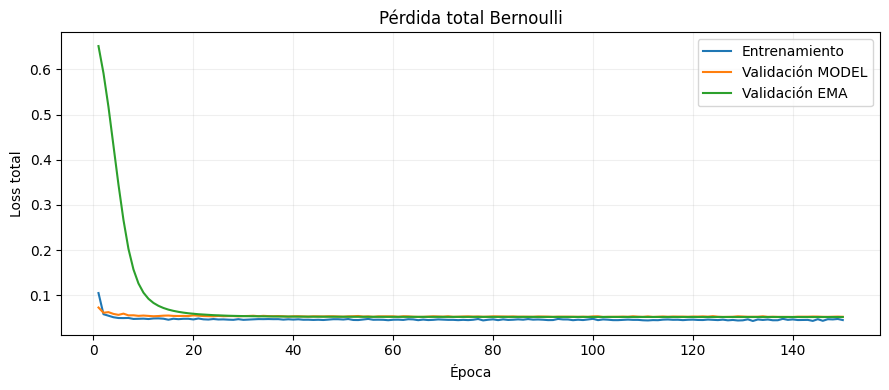

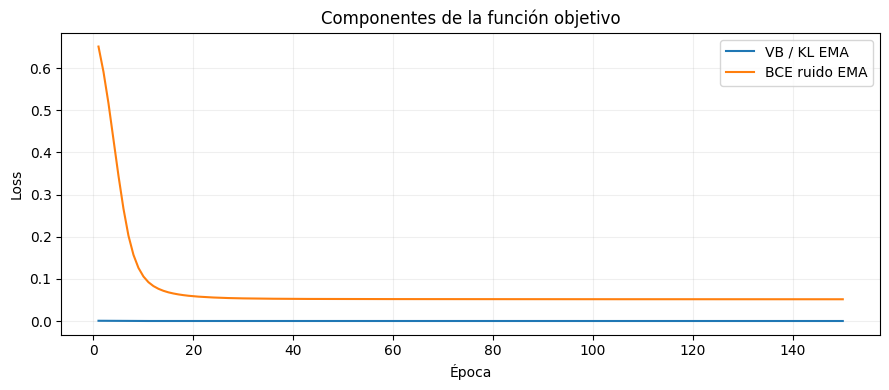

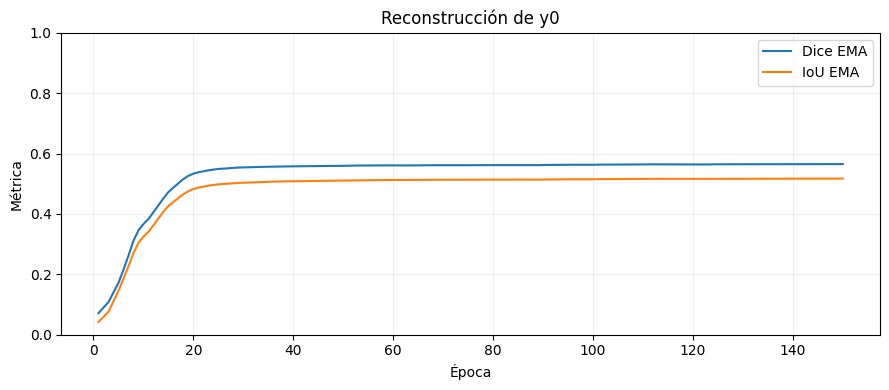

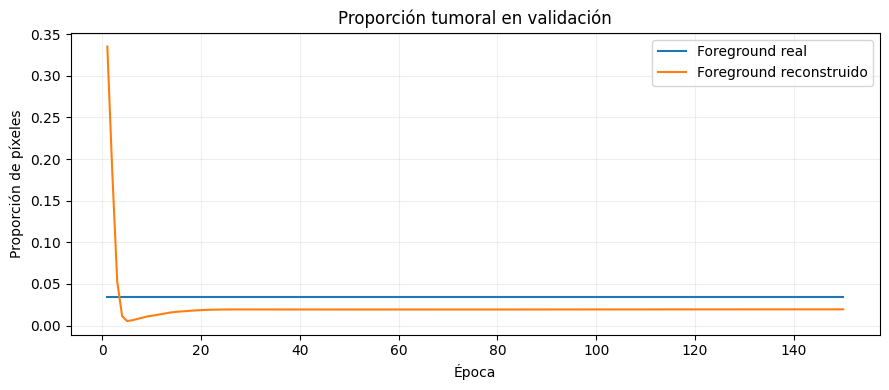

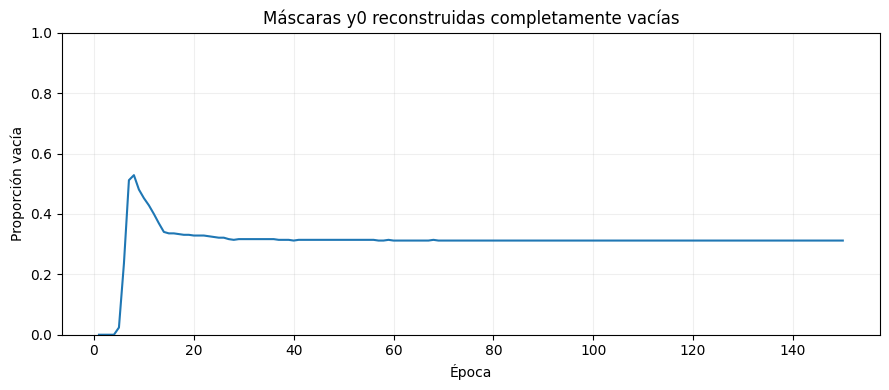

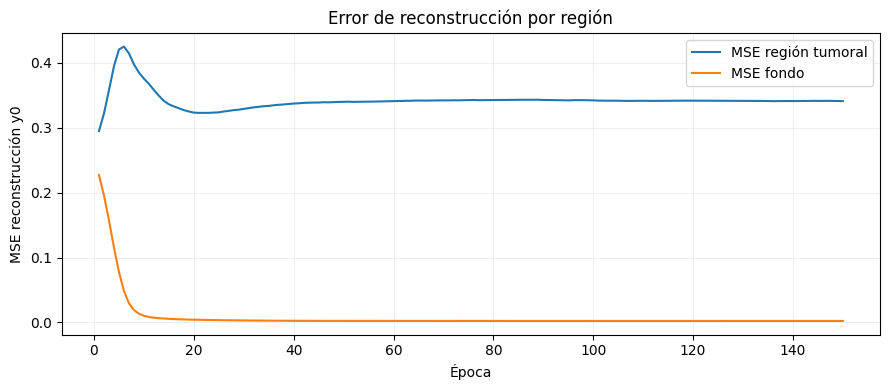

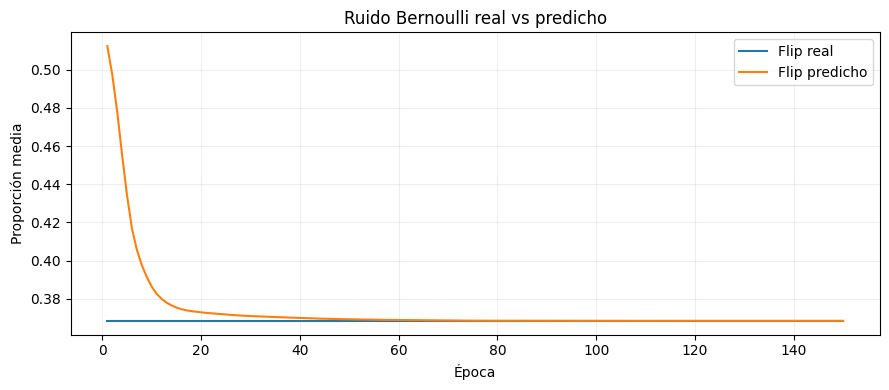

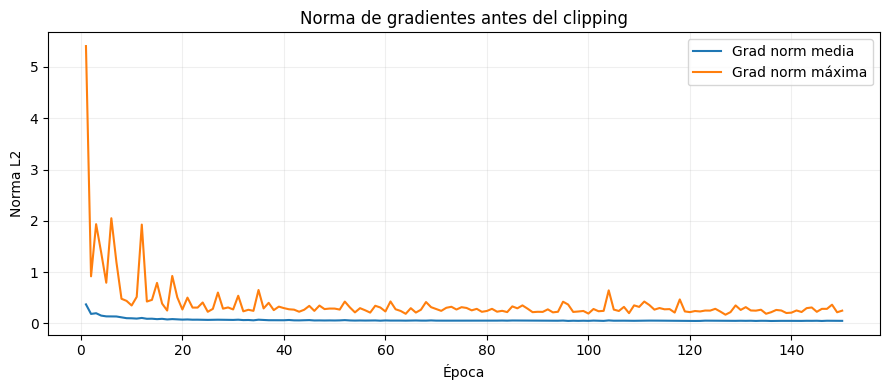

,epoch,model,bin,t_start,t_end,n,total_loss,vb_loss,bce_loss
2990,150,ema,0,0,99,41,0.000241,1.439924e-05,0.000227
2991,150,ema,1,100,199,33,0.001522,1.533824e-05,0.001507
2992,150,ema,2,200,299,45,0.004732,1.146205e-05,0.004721
2993,150,ema,3,300,399,50,0.008660,7.078623e-06,0.008653
2994,150,ema,4,400,499,39,0.017330,3.102216e-06,0.017327
2995,150,ema,5,500,599,43,0.041563,1.266191e-06,0.041561
2996,150,ema,6,600,699,44,0.086514,3.210512e-07,0.086513
2997,150,ema,7,700,799,39,0.094751,2.119676e-08,0.094751
2998,150,ema,8,800,899,44,0.137700,4.258815e-09,0.137700
2999,150,ema,9,900,999,42,0.117425,-1.896767e-10,0.117425


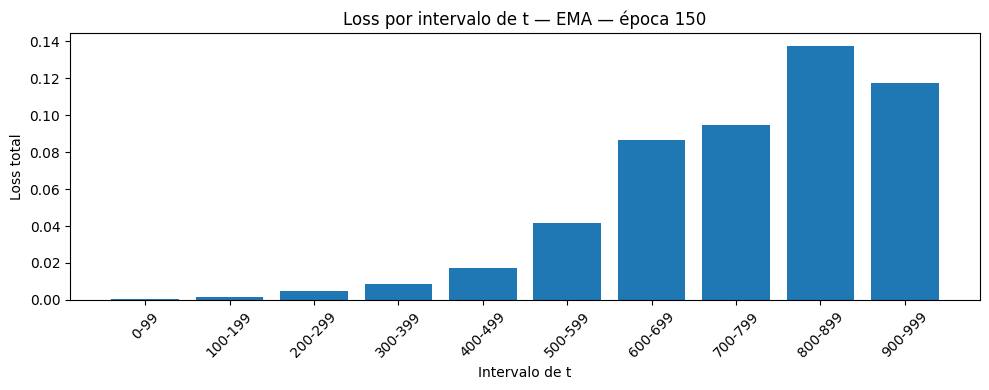

In [30]:
TRAINING_PLOTS_DIR = (
    DIAGNOSTIC_DIR
    / 'curvas_entrenamiento'
)

TRAINING_PLOTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

history_path = TABLE_DIR / 'history.csv'
timestep_history_path = TABLE_DIR / 'val_timestep_history.csv'

if history_path.exists():
    hist_df = pd.read_csv(
        history_path
    )

    display(
        hist_df.tail()
    )

    plt.figure(figsize=(9, 4))

    plt.plot(
        hist_df['epoch'],
        hist_df['train_loss'],
        label='Entrenamiento',
    )

    plt.plot(
        hist_df['epoch'],
        hist_df['val_model_total_loss'],
        label='Validación MODEL',
    )

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_total_loss'],
        label='Validación EMA',
    )

    plt.xlabel('Época')
    plt.ylabel('Loss total')
    plt.title(
        'Pérdida total Bernoulli'
    )
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        TRAINING_PLOTS_DIR
        / 'perdida_total_bernoulli.png',
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()

    plt.figure(figsize=(9, 4))

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_vb_loss'],
        label='VB / KL EMA',
    )

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_bce_loss'],
        label='BCE ruido EMA',
    )

    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.title(
        'Componentes de la función objetivo'
    )
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        TRAINING_PLOTS_DIR
        / 'componentes_funcion_objetivo.png',
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()

    plt.figure(figsize=(9, 4))

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_dice'],
        label='Dice EMA',
    )

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_iou'],
        label='IoU EMA',
    )

    plt.xlabel('Época')
    plt.ylabel('Métrica')
    plt.ylim(0, 1)
    plt.title(
        'Reconstrucción de y0'
    )
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        TRAINING_PLOTS_DIR
        / 'reconstruccion_y0_dice_iou.png',
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()

    plt.figure(figsize=(9, 4))

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_fg_real'],
        label='Foreground real',
    )

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_fg_pred'],
        label='Foreground reconstruido',
    )

    plt.xlabel('Época')
    plt.ylabel('Proporción de píxeles')
    plt.title(
        'Proporción tumoral en validación'
    )
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        TRAINING_PLOTS_DIR
        / 'proporcion_tumoral_validacion.png',
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()

    plt.figure(figsize=(9, 4))

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_empty_pred'],
    )

    plt.xlabel('Época')
    plt.ylabel('Proporción vacía')
    plt.ylim(0, 1)
    plt.title(
        'Máscaras y0 reconstruidas completamente vacías'
    )
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        TRAINING_PLOTS_DIR
        / 'mascaras_reconstruidas_vacias.png',
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()

    plt.figure(figsize=(9, 4))

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_fg_mse'],
        label='MSE región tumoral',
    )

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_bg_mse'],
        label='MSE fondo',
    )

    plt.xlabel('Época')
    plt.ylabel('MSE reconstrucción y0')
    plt.title(
        'Error de reconstrucción por región'
    )
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        TRAINING_PLOTS_DIR
        / 'error_reconstruccion_por_region.png',
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()

    plt.figure(figsize=(9, 4))

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_flip_real'],
        label='Flip real',
    )

    plt.plot(
        hist_df['epoch'],
        hist_df['val_ema_flip_pred'],
        label='Flip predicho',
    )

    plt.xlabel('Época')
    plt.ylabel('Proporción media')
    plt.title(
        'Ruido Bernoulli real vs predicho'
    )
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        TRAINING_PLOTS_DIR
        / 'ruido_bernoulli_real_vs_predicho.png',
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()

    plt.figure(figsize=(9, 4))

    plt.plot(
        hist_df['epoch'],
        hist_df['grad_norm_mean'],
        label='Grad norm media',
    )

    plt.plot(
        hist_df['epoch'],
        hist_df['grad_norm_max'],
        label='Grad norm máxima',
    )

    plt.xlabel('Época')
    plt.ylabel('Norma L2')
    plt.title(
        'Norma de gradientes antes del clipping'
    )
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        TRAINING_PLOTS_DIR
        / 'norma_gradientes.png',
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()

else:
    print(
        'Aún no existe history.csv. '
        'Primero ejecute el entrenamiento.'
    )


if timestep_history_path.exists():
    t_hist = pd.read_csv(
        timestep_history_path
    )

    last_epoch = int(
        t_hist['epoch'].max()
    )

    last_ema = t_hist.loc[
        (
            t_hist['epoch']
            == last_epoch
        )
        & (
            t_hist['model']
            == 'ema'
        )
    ].copy()

    display(last_ema)

    labels_t = [
        f'{int(a)}-{int(b)}'
        for a, b in zip(
            last_ema['t_start'],
            last_ema['t_end'],
        )
    ]

    plt.figure(figsize=(10, 4))

    plt.bar(
        labels_t,
        last_ema['total_loss'],
    )

    plt.xlabel('Intervalo de t')
    plt.ylabel('Loss total')
    plt.title(
        f'Loss por intervalo de t — EMA — época {last_epoch}'
    )
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        TRAINING_PLOTS_DIR
        / (
            f'loss_por_intervalo_t_'
            f'ema_epoca_{last_epoch:03d}.png'
        ),
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()


## 16. Carga del modelo seleccionado

Se recuperan los parámetros EMA del checkpoint con menor pérdida total de validación.

In [31]:
# Selección del checkpoint para generación final.
# 'best.pt'      -> mejor loss total de validación con EMA.
# 'best_dice.pt' -> mejor Dice de reconstrucción y0 con EMA.
CHECKPOINT_NAME = 'best.pt'

BEST_CKPT = (
    CHECKPOINT_DIR
    / CHECKPOINT_NAME
)

if not BEST_CKPT.exists():
    raise FileNotFoundError(
        f'No se encontró {BEST_CKPT}. '
        'Entrene el modelo o indique otro checkpoint.'
    )

checkpoint = torch.load(
    BEST_CKPT,
    map_location=DEVICE,
    weights_only=False,
)

best_model = ConditionalUNet(
    in_channels=1,
    base_channels=checkpoint[
        'config'
    ]['BASE_CHANNELS'],
    emb_dim=checkpoint[
        'config'
    ]['TIME_EMB_DIM'],
).to(DEVICE)

best_model.load_state_dict(
    checkpoint[
        'ema_state'
    ]
)

best_model.eval()

print(
    'Checkpoint cargado:',
    BEST_CKPT,
)
print(
    'Época:',
    checkpoint['epoch'],
)
print(
    'Mejor val total loss:',
    checkpoint.get('best_val'),
)
print(
    'Mejor Dice registrado:',
    checkpoint.get('best_dice'),
)


Checkpoint cargado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\checkpoints\best.pt
Época: 149
Mejor val total loss: 0.05157291388050431
Mejor Dice registrado: 0.5651336425826663


## 17. Generación por condición

Se presentan realizaciones correspondientes a las nueve combinaciones de tipo de tumor y plano anatómico.

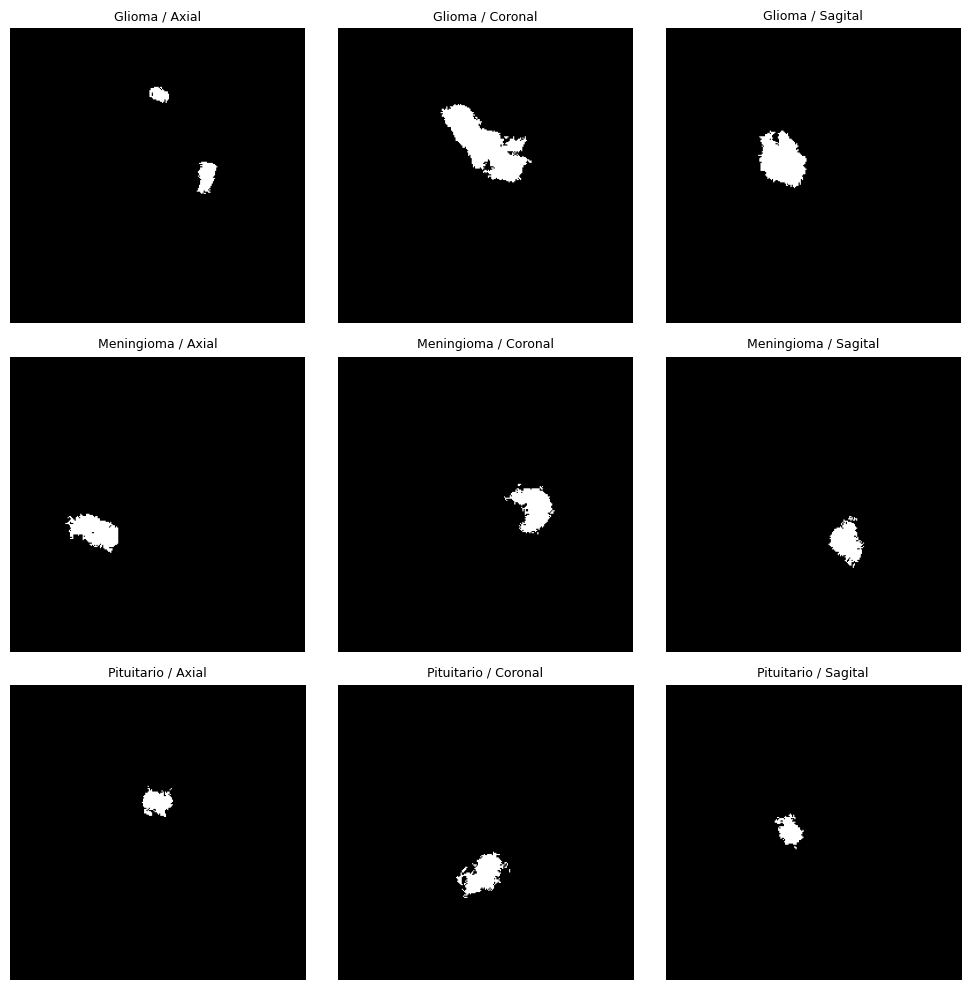

In [32]:
tumor_ids = []
plane_ids = []
labels = []

for tumor_code in ['gl', 'me', 'pi']:
    for plane_code in ['ax', 'co', 'sa']:
        tumor_ids.append(
            TUMOR_TO_ID[tumor_code]
        )
        plane_ids.append(
            PLANE_TO_ID[plane_code]
        )
        labels.append(
            f'{TUMOR_MAP[tumor_code]} / '
            f'{PLANE_MAP[plane_code]}'
        )


samples = sample_bernoulli(
    best_model,
    tumor_id=tumor_ids,
    plane_id=plane_ids,
    image_size=CFG.IMAGE_SIZE,
    sampling_steps=CFG.SAMPLING_STEPS,
)

binary = (
    samples
    .cpu()
    .numpy()
    .astype(np.uint8)
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(10, 10),
)

for ax, mask, label in zip(
    axes.ravel(),
    binary,
    labels,
):
    ax.imshow(
        mask[0],
        cmap='gray',
        vmin=0,
        vmax=1,
    )

    ax.set_title(
        label,
        fontsize=9,
    )

    ax.axis('off')

plt.tight_layout()
plt.show()


## 18. Sensibilidad al número de pasos

Se comparan máscaras generadas con distintas cantidades de pasos de muestreo.

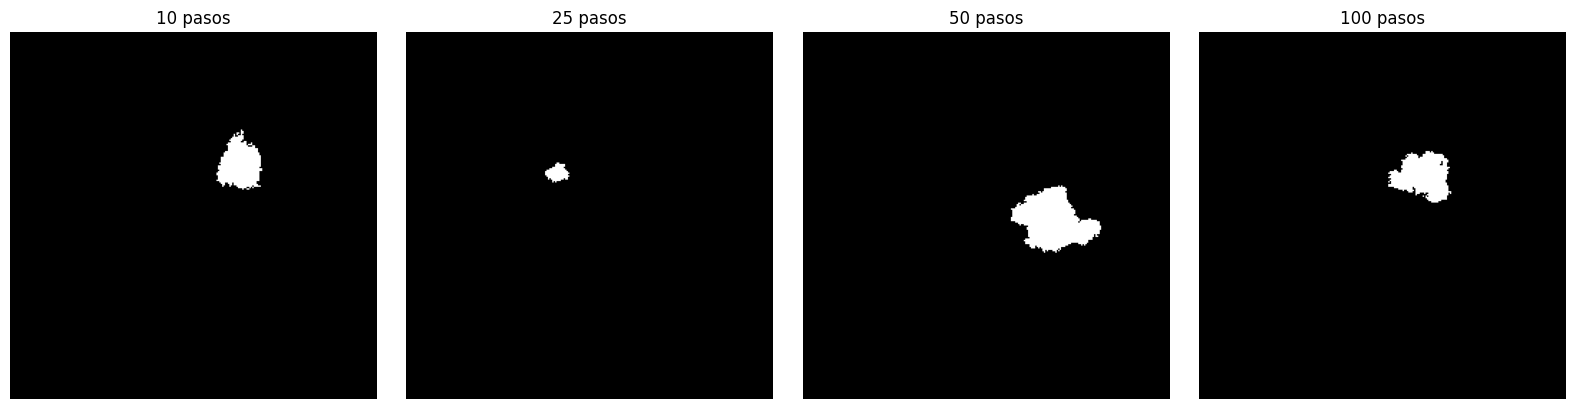

In [33]:
TEST_TUMOR = 'gl'
TEST_PLANE = 'ax'

SAMPLING_VALUES = [
    10,
    25,
    50,
    100,
]

sampling_generator = torch.Generator()
sampling_generator.manual_seed(
    CFG.MONITOR_SEED + 101
)

fixed_one_noise = torch.bernoulli(
    torch.full(
        (
            1,
            1,
            CFG.IMAGE_SIZE,
            CFG.IMAGE_SIZE,
        ),
        0.5,
    ),
    generator=sampling_generator,
)

fig, axes = plt.subplots(
    1,
    len(SAMPLING_VALUES),
    figsize=(
        4 * len(SAMPLING_VALUES),
        4,
    ),
)

for ax, n_steps in zip(
    axes,
    SAMPLING_VALUES,
):
    sample = sample_bernoulli(
        best_model,
        tumor_id=[
            TUMOR_TO_ID[
                TEST_TUMOR
            ]
        ],
        plane_id=[
            PLANE_TO_ID[
                TEST_PLANE
            ]
        ],
        image_size=CFG.IMAGE_SIZE,
        sampling_steps=min(
            n_steps,
            CFG.TIMESTEPS,
        ),
        initial_noise=fixed_one_noise,
    )

    mask = (
        sample[
            0,
            0,
        ]
        .cpu()
        .numpy()
    )

    ax.imshow(
        mask,
        cmap='gray',
        vmin=0,
        vmax=1,
    )

    ax.set_title(
        f'{n_steps} pasos'
    )

    ax.axis('off')

plt.tight_layout()
plt.show()


## 19. Control de plausibilidad morfológica

Se obtienen límites de aceptación por condición a partir de las máscaras reales de entrenamiento.

In [34]:
QC_CONTINUOUS = [
    'area_fraction',
    'centroid_x',
    'centroid_y',
    'bbox_w',
    'bbox_h',
]


def build_qc_ranges(
    df: pd.DataFrame,
    q_low: float,
    q_high: float,
):
    rows = []

    for cond, g in df.groupby(
        'condition'
    ):
        row = {
            'condition': cond,
            'n_train': len(g),
        }

        for col in QC_CONTINUOUS:
            row[f'{col}_low'] = float(
                g[col].quantile(q_low)
            )
            row[f'{col}_high'] = float(
                g[col].quantile(q_high)
            )

        row['n_components_max'] = int(
            g['n_components'].max()
        )

        rows.append(row)

    return (
        pd.DataFrame(rows)
        .set_index('condition')
        .sort_index()
    )


qc_ranges = build_qc_ranges(
    train_df,
    CFG.QC_Q_LOW,
    CFG.QC_Q_HIGH,
)

qc_ranges.to_csv(
    TABLE_DIR / 'qc_ranges_train.csv'
)

display(
    qc_ranges.round(5)
)

print('\nMáximo de componentes por condición:')
display(
    qc_ranges[
        ['n_components_max']
    ]
)


,n_train,area_fraction_low,area_fraction_high,centroid_x_low,centroid_x_high,centroid_y_low,centroid_y_high,bbox_w_low,bbox_w_high,bbox_h_low,bbox_h_high,n_components_max
condition,,,,,,,,,,,,
gl_ax,394,0.00158,0.07288,0.24934,0.71435,0.21912,0.73547,0.04492,0.37500,0.04492,0.46100,3
gl_co,430,0.00107,0.06711,0.27524,0.71449,0.19222,0.63453,0.03991,0.37797,0.03572,0.38420,3
gl_sa,323,0.00115,0.08403,0.27000,0.70235,0.19116,0.64313,0.04221,0.45197,0.03830,0.34908,4
me_ax,348,0.00195,0.09088,0.24167,0.76901,0.21781,0.78141,0.04883,0.45330,0.05273,0.44719,3
me_co,400,0.00143,0.04749,0.24627,0.75543,0.16506,0.67166,0.04492,0.31472,0.04879,0.43583,2
me_sa,458,0.00145,0.05628,0.23783,0.78265,0.15893,0.65340,0.05440,0.53125,0.04548,0.41490,4
pi_ax,424,0.00137,0.02493,0.45393,0.54666,0.34148,0.51483,0.04710,0.23994,0.03756,0.21853,3
pi_co,502,0.00193,0.04836,0.45798,0.54008,0.44324,0.68190,0.05958,0.29998,0.04492,0.31542,3
pi_sa,513,0.00133,0.04739,0.36787,0.63183,0.46905,0.65687,0.04992,0.22414,0.03516,0.30055,2



Máximo de componentes por condición:


,n_components_max
condition,
gl_ax,3
gl_co,3
gl_sa,4
me_ax,3
me_co,2
me_sa,4
pi_ax,3
pi_co,3
pi_sa,2


In [35]:
def remove_tiny_components(
    binary: np.ndarray,
    min_pixels: int = 8,
) -> np.ndarray:

    """Elimina componentes extremadamente pequeñas sin forzar una sola lesión."""

    binary = binary.astype(
        bool
    )

    structure = ndimage.generate_binary_structure(
        rank=2,
        connectivity=CFG.MASK_CONNECTIVITY,
    )

    labeled, n = ndimage.label(
        binary,
        structure=structure,
    )

    if n == 0:
        return binary.astype(
            np.uint8
        )

    counts = np.bincount(
        labeled.ravel()
    )

    keep_labels = np.where(
        counts >= min_pixels
    )[0]

    keep_labels = keep_labels[
        keep_labels != 0
    ]

    cleaned = np.isin(
        labeled,
        keep_labels,
    )

    return cleaned.astype(
        np.uint8
    )


def gaussian_postprocess_binary(
    binary: np.ndarray,
    sigma: float,
    threshold: float = 0.5,
):
    smooth = gaussian_filter(
        binary.astype(np.float32),
        sigma=float(sigma),
        mode='nearest',
    )

    post = (
        smooth >= threshold
    ).astype(np.uint8)

    return smooth, post


def check_plausibility(
    binary: np.ndarray,
    condition: str,
    qc_ranges: pd.DataFrame,
):
    feat = morphology_features_from_array(
        binary
    )

    reasons = []

    if feat['area_fraction'] <= 0:
        reasons.append('máscara vacía')
        return False, feat, reasons

    limits = qc_ranges.loc[
        condition
    ]

    for col in QC_CONTINUOUS:
        value = feat[col]
        lo = limits[f'{col}_low']
        hi = limits[f'{col}_high']

        if not np.isfinite(value):
            reasons.append(
                f'{col} no finito'
            )
        elif value < lo:
            reasons.append(
                f'{col} < {lo:.4f}'
            )
        elif value > hi:
            reasons.append(
                f'{col} > {hi:.4f}'
            )

    max_components = int(
        limits['n_components_max']
    )

    if feat['n_components'] > max_components:
        reasons.append(
            'n_components '
            f'> max_train({max_components})'
        )

    return (
        len(reasons) == 0,
        feat,
        reasons,
    )


### 19.1 Aplicación del control a validación

Se cuantifica la proporción de máscaras reales de validación que cumple los criterios morfológicos.

In [36]:
val_morph_rows = [
    morphology_features_from_path(p)
    for p in val_df['path']
]

val_morph_df = pd.DataFrame(
    val_morph_rows
)

for col in [
    'area_fraction',
    'centroid_x',
    'centroid_y',
    'bbox_w',
    'bbox_h',
    'n_components',
]:
    val_df[col] = val_morph_df[
        col
    ].values

val_qc_pass = []
val_qc_reasons = []

for row in val_df.itertuples(
    index=False
):
    binary = (
        np.asarray(
            Image.open(
                row.path
            ).convert('L')
        ) > CFG.MASK_THRESHOLD
    ).astype(np.uint8)

    passed, _, reasons = check_plausibility(
        binary,
        row.condition,
        qc_ranges,
    )

    val_qc_pass.append(
        passed
    )
    val_qc_reasons.append(
        ' | '.join(reasons)
    )

val_df['qc_pass_real'] = val_qc_pass
val_df['qc_reasons_real'] = val_qc_reasons

n_val = len(val_df)
n_fail = int(
    (~val_df['qc_pass_real']).sum()
)

print(
    f'Validación real: {n_val} máscaras'
)
print(
    f'Fuera del QC: {n_fail} '
    f'({100 * n_fail / max(n_val, 1):.2f}%)'
)

qc_validation_summary = (
    val_df
    .groupby('condition')
    .agg(
        n=('basename', 'size'),
        accepted=('qc_pass_real', 'sum'),
    )
    .reset_index()
)

qc_validation_summary['rejected'] = (
    qc_validation_summary['n']
    - qc_validation_summary['accepted']
)

qc_validation_summary['rejected_pct'] = (
    100
    * qc_validation_summary['rejected']
    / qc_validation_summary['n']
)

display(
    qc_validation_summary.round(2)
)

val_df.to_csv(
    TABLE_DIR / 'qc_validacion_real.csv',
    index=False,
)

qc_validation_summary.to_csv(
    TABLE_DIR / 'qc_validacion_real_resumen.csv',
    index=False,
)


Validación real: 420 máscaras
Fuera del QC: 37 (8.81%)


,condition,n,accepted,rejected,rejected_pct
0,gl_ax,42,41,1,2.38
1,gl_co,40,37,3,7.50
2,gl_sa,44,37,7,15.91
3,me_ax,62,53,9,14.52
4,me_co,40,33,7,17.50
5,me_sa,42,40,2,4.76
6,pi_ax,62,59,3,4.84
7,pi_co,45,41,4,8.89
8,pi_sa,43,42,1,2.33


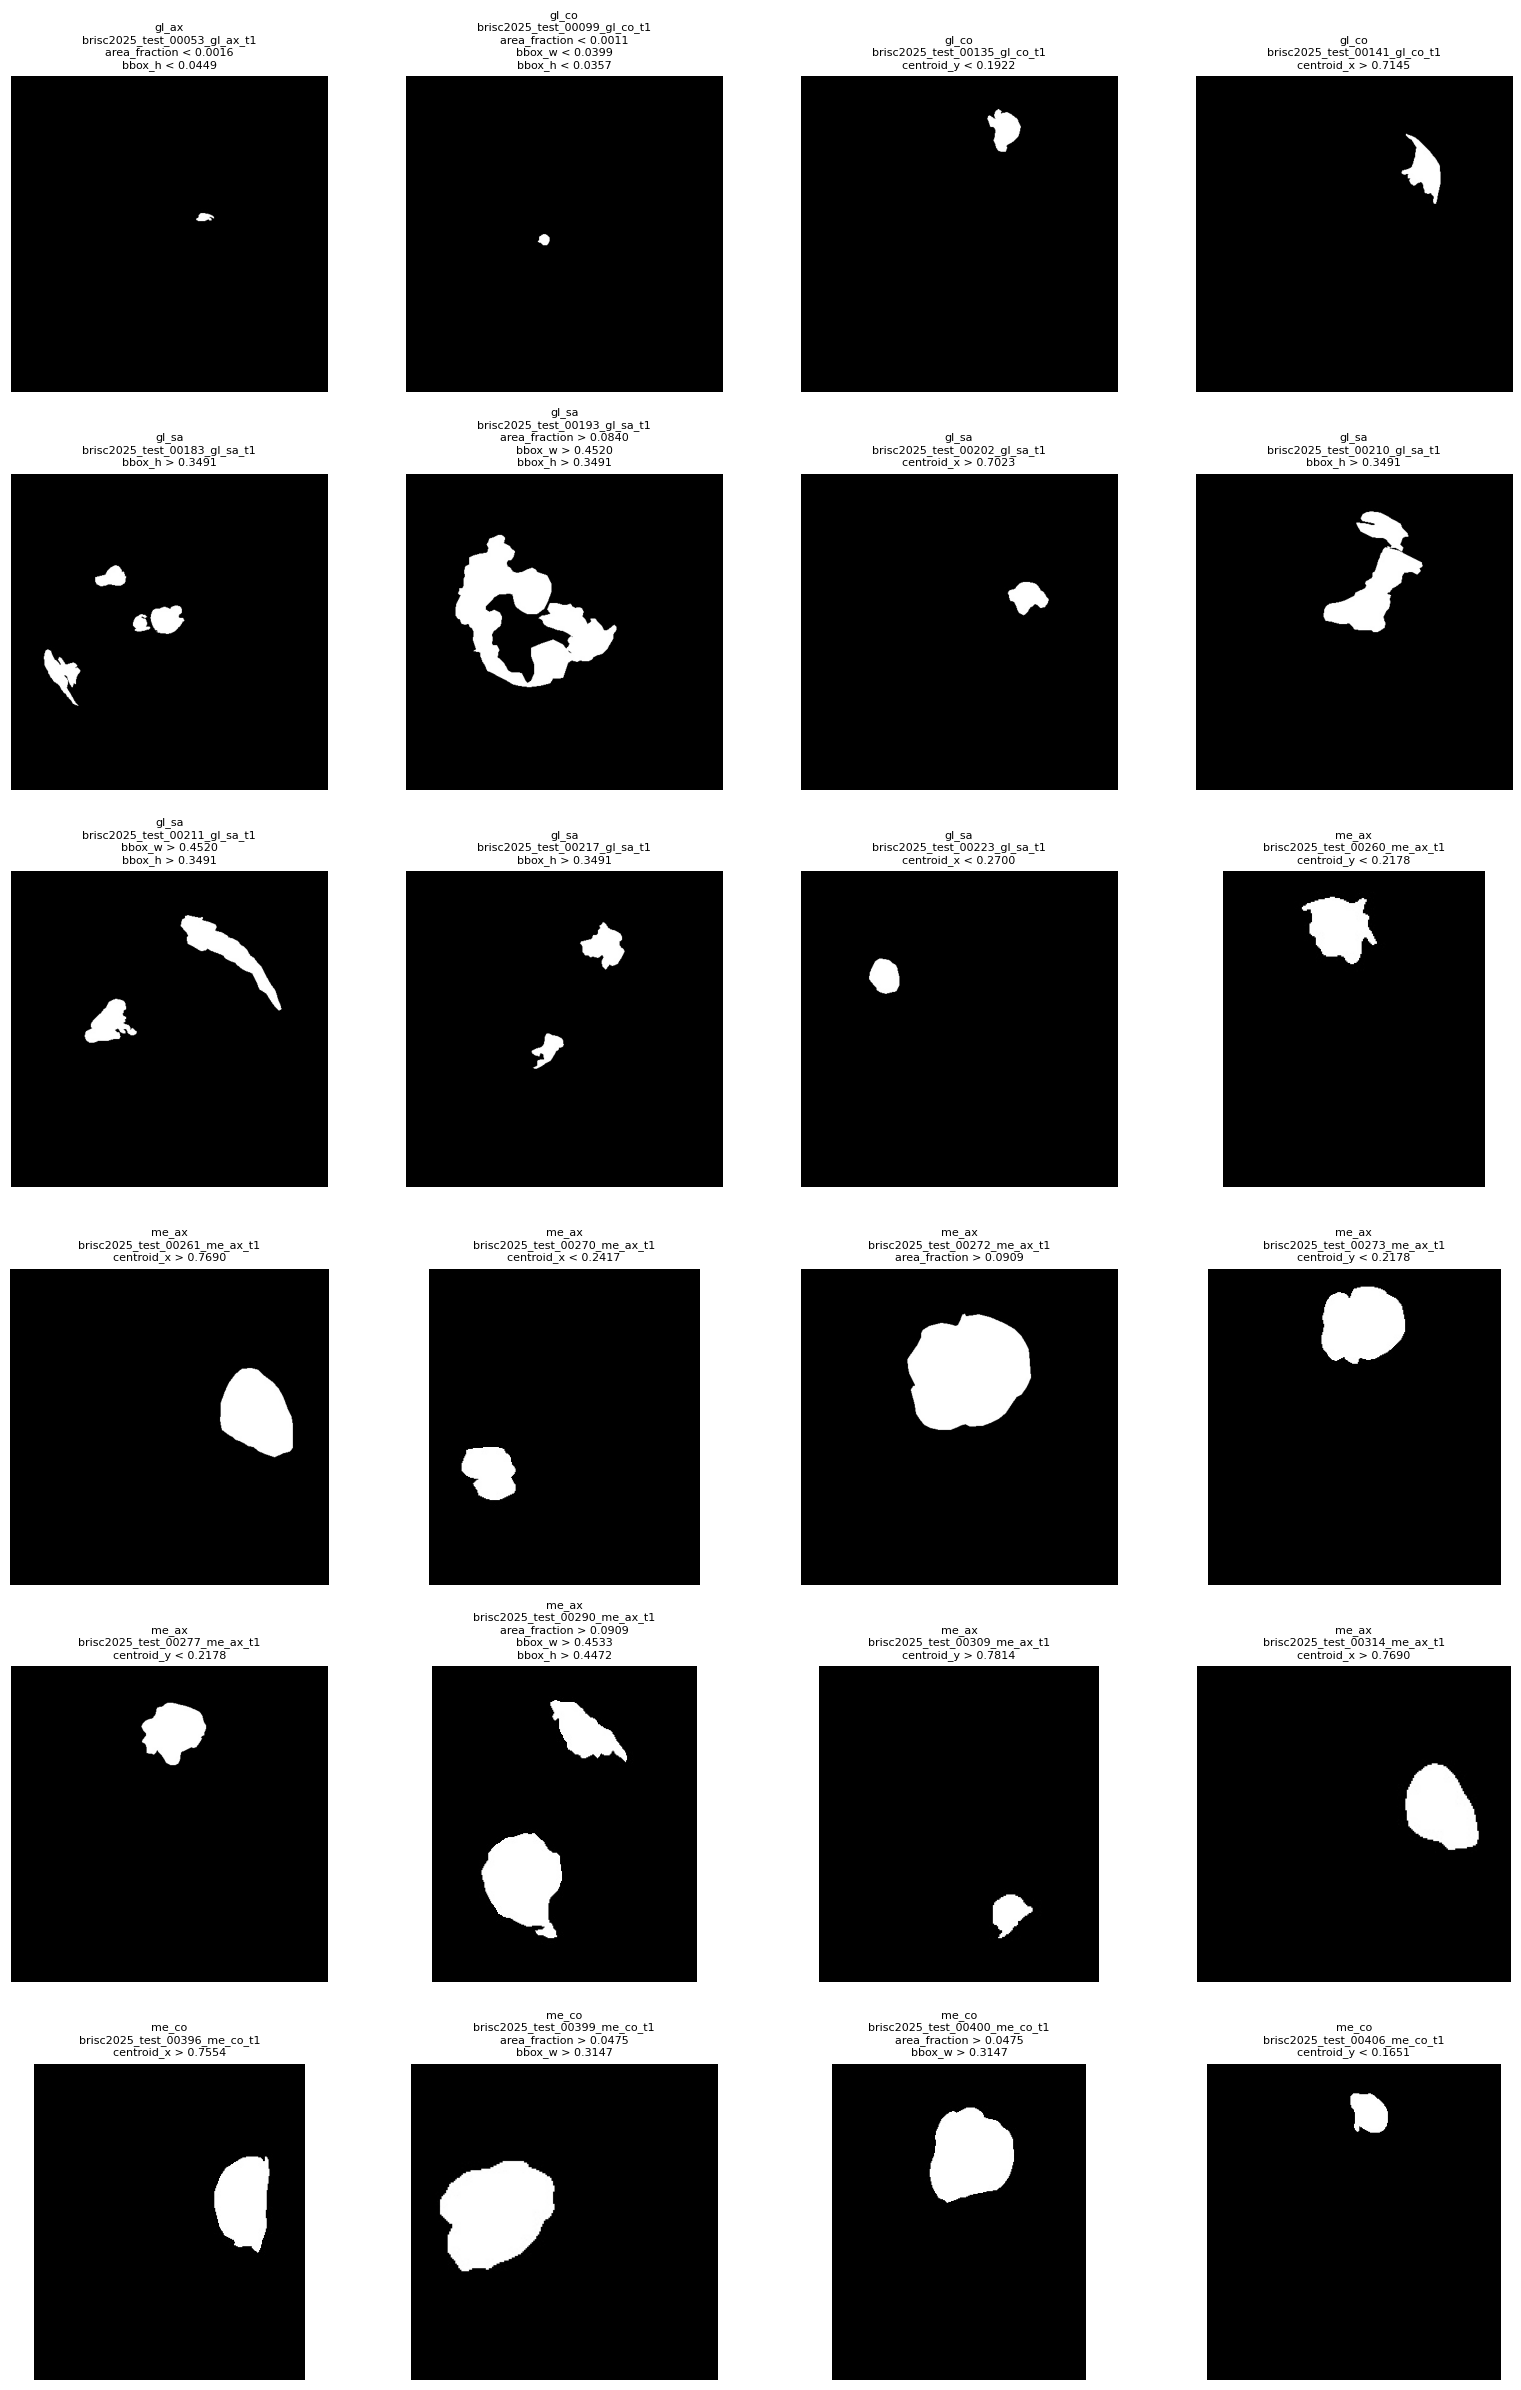

In [37]:
def show_real_qc_failures(
    df: pd.DataFrame,
    max_show: int = 24,
    n_cols: int = 4,
):
    failed = (
        df.loc[
            ~df['qc_pass_real']
        ]
        .head(max_show)
        .reset_index(drop=True)
    )

    if failed.empty:
        print(
            'Ninguna máscara real de validación '
            'quedó fuera del QC.'
        )
        return

    n_rows = int(
        np.ceil(
            len(failed) / n_cols
        )
    )

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(4 * n_cols, 4 * n_rows),
    )

    axes = np.atleast_1d(
        axes
    ).ravel()

    for ax, row in zip(
        axes,
        failed.itertuples(index=False),
    ):
        mask = np.asarray(
            Image.open(row.path).convert('L')
        )

        ax.imshow(
            mask,
            cmap='gray',
            vmin=0,
            vmax=255,
        )

        reasons = row.qc_reasons_real.replace(
            ' | ',
            '\n',
        )

        ax.set_title(
            f'{row.condition}\n'
            f'{row.basename}\n'
            f'{reasons}',
            fontsize=8,
        )
        ax.axis('off')

    for ax in axes[
        len(failed):
    ]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()


show_real_qc_failures(
    val_df
)


## 20. Generación preliminar

Se producen máscaras preliminares destinadas a los diagnósticos morfológicos y al análisis del suavizado.

In [38]:
@torch.no_grad()
def generate_synthetic_masks(
    model,
    n_per_condition: int,
    output_dir: Path,
    batch_size: int = 4,
    sampling_steps: int | None = None,
):
    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    sampling_steps = (
        CFG.SAMPLING_STEPS
        if sampling_steps is None
        else sampling_steps
    )

    records = []
    global_index = 0

    for tumor_code in ['gl', 'me', 'pi']:
        for plane_code in ['ax', 'co', 'sa']:
            condition = (
                f'{tumor_code}_'
                f'{plane_code}'
            )

            cond_dir = (
                output_dir
                / condition
            )

            cond_dir.mkdir(
                parents=True,
                exist_ok=True,
            )

            remaining = n_per_condition

            while remaining > 0:
                current_bs = min(
                    batch_size,
                    remaining,
                )

                tumor_ids = [
                    TUMOR_TO_ID[tumor_code]
                ] * current_bs

                plane_ids = [
                    PLANE_TO_ID[plane_code]
                ] * current_bs

                samples = sample_bernoulli(
                    model,
                    tumor_id=tumor_ids,
                    plane_id=plane_ids,
                    image_size=CFG.IMAGE_SIZE,
                    sampling_steps=sampling_steps,
                )

                samples_np = (
                    samples
                    .cpu()
                    .numpy()
                    .astype(np.uint8)
                )

                for jj in range(current_bs):
                    raw_binary = samples_np[
                        jj,
                        0,
                    ]

                    cleaned = remove_tiny_components(
                        raw_binary,
                        CFG.MIN_COMPONENT_PIXELS,
                    )

                    feat = morphology_features_from_array(
                        cleaned
                    )

                    filename = (
                        f'oe2_synth_'
                        f'{global_index:06d}_'
                        f'{tumor_code}_'
                        f'{plane_code}.png'
                    )

                    out_path = (
                        cond_dir
                        / filename
                    )

                    Image.fromarray(
                        cleaned * 255,
                        mode='L',
                    ).save(
                        out_path
                    )

                    records.append({
                        'filename': filename,
                        'path': str(out_path),
                        'synthetic_index': global_index,
                        'tumor_code': tumor_code,
                        'tumor': TUMOR_MAP[tumor_code],
                        'plane_code': plane_code,
                        'plane': PLANE_MAP[plane_code],
                        'condition': condition,
                        'method': 'bernoulli',
                        'profile': CFG.PROFILE,
                        'sampling_steps': sampling_steps,
                        'threshold': CFG.THRESHOLD,
                        'min_component_pixels': CFG.MIN_COMPONENT_PIXELS,
                        **feat,
                    })

                    global_index += 1

                remaining -= current_bs

            print(
                f'{condition}: '
                f'{n_per_condition} generadas'
            )

    manifest = pd.DataFrame(
        records
    )

    manifest.to_csv(
        output_dir
        / 'manifest_synthetic.csv',
        index=False,
    )

    return manifest


In [39]:
# Muestra preliminar para diagnóstico y selección de sigma.
# Cambiar N_PER_CONDITION si se desea otro tamaño.
N_PER_CONDITION = 100

expected_total = 9 * N_PER_CONDITION
manifest_path = SYNTH_DIR / 'manifest_synthetic.csv'

if manifest_path.exists():
    synthetic_manifest = pd.read_csv(
        manifest_path
    )

    if len(synthetic_manifest) == expected_total:
        print(
            'Ya existen las máscaras sintéticas preliminares. '
            'Se cargará el manifest guardado.'
        )
    else:
        print(
            'El manifest preliminar existe pero está incompleto '
            'o no coincide con el tamaño esperado. '
            'Se regenerará.'
        )

        synthetic_manifest = generate_synthetic_masks(
            best_model,
            n_per_condition=N_PER_CONDITION,
            output_dir=SYNTH_DIR,
            batch_size=max(
                1,
                min(CFG.BATCH_SIZE, 4),
            ),
        )
else:
    synthetic_manifest = generate_synthetic_masks(
        best_model,
        n_per_condition=N_PER_CONDITION,
        output_dir=SYNTH_DIR,
        batch_size=max(
            1,
            min(CFG.BATCH_SIZE, 4),
        ),
    )

# Reconstrucción de rutas de las máscaras al trasladar resultados al repositorio.
synthetic_manifest = synthetic_manifest.copy()
synthetic_manifest['path'] = [
    str(SYNTH_DIR / str(condicion) / str(nombre))
    for condicion, nombre in zip(
        synthetic_manifest['condition'], synthetic_manifest['filename']
    )
]
missing_prelim = [
    archivo for archivo in synthetic_manifest['path']
    if not Path(archivo).is_file()
]
if missing_prelim:
    raise FileNotFoundError(
        f'No se encontraron {len(missing_prelim)} máscaras preliminares; '
        f'primer archivo faltante: {missing_prelim[0]}'
    )

display(
    synthetic_manifest.head()
)

print(
    '\nTotal preliminar generado/cargado:',
    len(synthetic_manifest),
)


Ya existen las máscaras sintéticas preliminares. Se cargará el manifest guardado.


,filename,path,synthetic_index,tumor_code,tumor,plane_code,plane,condition,method,profile,sampling_steps,threshold,min_component_pixels,area_fraction,centroid_x,centroid_y,bbox_w,bbox_h,n_components
0,oe2_synth_000000_gl_ax.png,K:\Tesis\Github\results\OE2\difusion_bernoulli...,0,gl,Glioma,ax,Axial,gl_ax,bernoulli,final,100,0.5,8,0.009323,0.623298,0.617182,0.152344,0.136719,1
1,oe2_synth_000001_gl_ax.png,K:\Tesis\Github\results\OE2\difusion_bernoulli...,1,gl,Glioma,ax,Axial,gl_ax,bernoulli,final,100,0.5,8,0.006760,0.659585,0.571124,0.113281,0.101562,1
2,oe2_synth_000002_gl_ax.png,K:\Tesis\Github\results\OE2\difusion_bernoulli...,2,gl,Glioma,ax,Axial,gl_ax,bernoulli,final,100,0.5,8,0.006897,0.375048,0.396937,0.105469,0.101562,1
3,oe2_synth_000003_gl_ax.png,K:\Tesis\Github\results\OE2\difusion_bernoulli...,3,gl,Glioma,ax,Axial,gl_ax,bernoulli,final,100,0.5,8,0.012436,0.684427,0.316131,0.136719,0.156250,1
4,oe2_synth_000004_gl_ax.png,K:\Tesis\Github\results\OE2\difusion_bernoulli...,4,gl,Glioma,ax,Axial,gl_ax,bernoulli,final,100,0.5,8,0.014038,0.629514,0.473487,0.121094,0.164062,1



Total preliminar generado/cargado: 900


## 21. Comparación morfológica preliminar

Se comparan las características geométricas de las máscaras reales y las máscaras preliminares.

In [40]:
if 'synthetic_manifest' not in globals():
    manifest_path = SYNTH_DIR / 'manifest_synthetic.csv'
    if not manifest_path.exists():
        raise FileNotFoundError('Primero genere máscaras sintéticas.')
    synthetic_manifest = pd.read_csv(manifest_path)

# Los manifiestos históricos pueden contener rutas de ejecución anteriores.
synthetic_manifest = synthetic_manifest.copy()
synthetic_manifest['path'] = [
    str(SYNTH_DIR / str(condicion) / str(nombre))
    for condicion, nombre in zip(
        synthetic_manifest['condition'], synthetic_manifest['filename']
    )
]
real_for_compare = train_df.copy()
real_for_compare['source'] = 'Real'
synthetic_for_compare = synthetic_manifest.copy()
synthetic_for_compare['source'] = 'Sintético'

compare_cols = ['condition', 'source'] + QC_CONTINUOUS + ['n_components']
combined = pd.concat([
    real_for_compare[compare_cols],
    synthetic_for_compare[compare_cols],
], ignore_index=True)

display(
    combined.groupby(['source', 'condition'])[QC_CONTINUOUS + ['n_components']]
    .median()
    .round(4)
)


area_fraction  centroid_x  centroid_y  bbox_w  bbox_h  \
source    condition                                                          
Real      gl_ax             0.0146      0.4766      0.4562  0.1514  0.1641   
          gl_co             0.0161      0.4824      0.4122  0.1562  0.1602   
          gl_sa             0.0154      0.4845      0.4070  0.1738  0.1504   
          me_ax             0.0169      0.5100      0.4970  0.1572  0.1660   
          me_co             0.0147      0.5002      0.3689  0.1533  0.1465   
          me_sa             0.0157      0.5068      0.3784  0.1660  0.1523   
          pi_ax             0.0081      0.5001      0.4156  0.1172  0.1016   
          pi_co             0.0122      0.5005      0.5409  0.1504  0.1375   
          pi_sa             0.0074      0.4645      0.5577  0.1035  0.1113   
Sintético gl_ax             0.0138      0.4999      0.4157  0.1641  0.1738   
          gl_co             0.0143      0.5119      0.4167  0.1641  0.1641   
          gl_sa             0.0151      0.4730      0.4298  0.1758  0.1680   
          me_ax             0.0178      0.4969      0.4906  0.1836  0.1758   
          me_co             0.0140      0.5069      0.3375  0.1699  0.1562   
          me_sa             0.0156      0.5431      0.3885  0.1836  0.1602   
          pi_ax             0.0094      0.4996      0.4077  0.1445  0.1250   
          pi_co             0.0135      0.4974      0.5392  0.1602  0.1641   
          pi_sa             0.0083      0.4604      0.5509  0.1191  0.1211   

                     n_components  
source    condition                
Real      gl_ax               1.0  
          gl_co               1.0  
          gl_sa               1.0  
          me_ax               1.0  
          me_co               1.0  
          me_sa               1.0  
          pi_ax               1.0  
          pi_co               1.0  
          pi_sa               1.0  
Sintético gl_ax               1.0  
          gl_co               1.0  
          gl_sa               1.0  
          me_ax               1.0  
          me_co               1.0  
          me_sa               1.0  
          pi_ax               1.0  
          pi_co               1.0  
          pi_sa               1.0

In [41]:
preliminary_by_condition = (
    synthetic_manifest
    .groupby('condition')
    .agg(
        n=('filename', 'size'),
        area_fraction_median=('area_fraction', 'median'),
        n_components_median=('n_components', 'median'),
        n_components_max=('n_components', 'max'),
    )
)

display(
    preliminary_by_condition.round(4)
)


,n,area_fraction_median,n_components_median,n_components_max
condition,,,,
gl_ax,100,0.0138,1.0,3
gl_co,100,0.0143,1.0,3
gl_sa,100,0.0151,1.0,3
me_ax,100,0.0178,1.0,3
me_co,100,0.0140,1.0,3
me_sa,100,0.0156,1.0,4
pi_ax,100,0.0094,1.0,3
pi_co,100,0.0135,1.0,4
pi_sa,100,0.0083,1.0,4


## 22. Visualización de máscaras generadas

Se muestran ejemplos seleccionados de las nueve condiciones de generación.

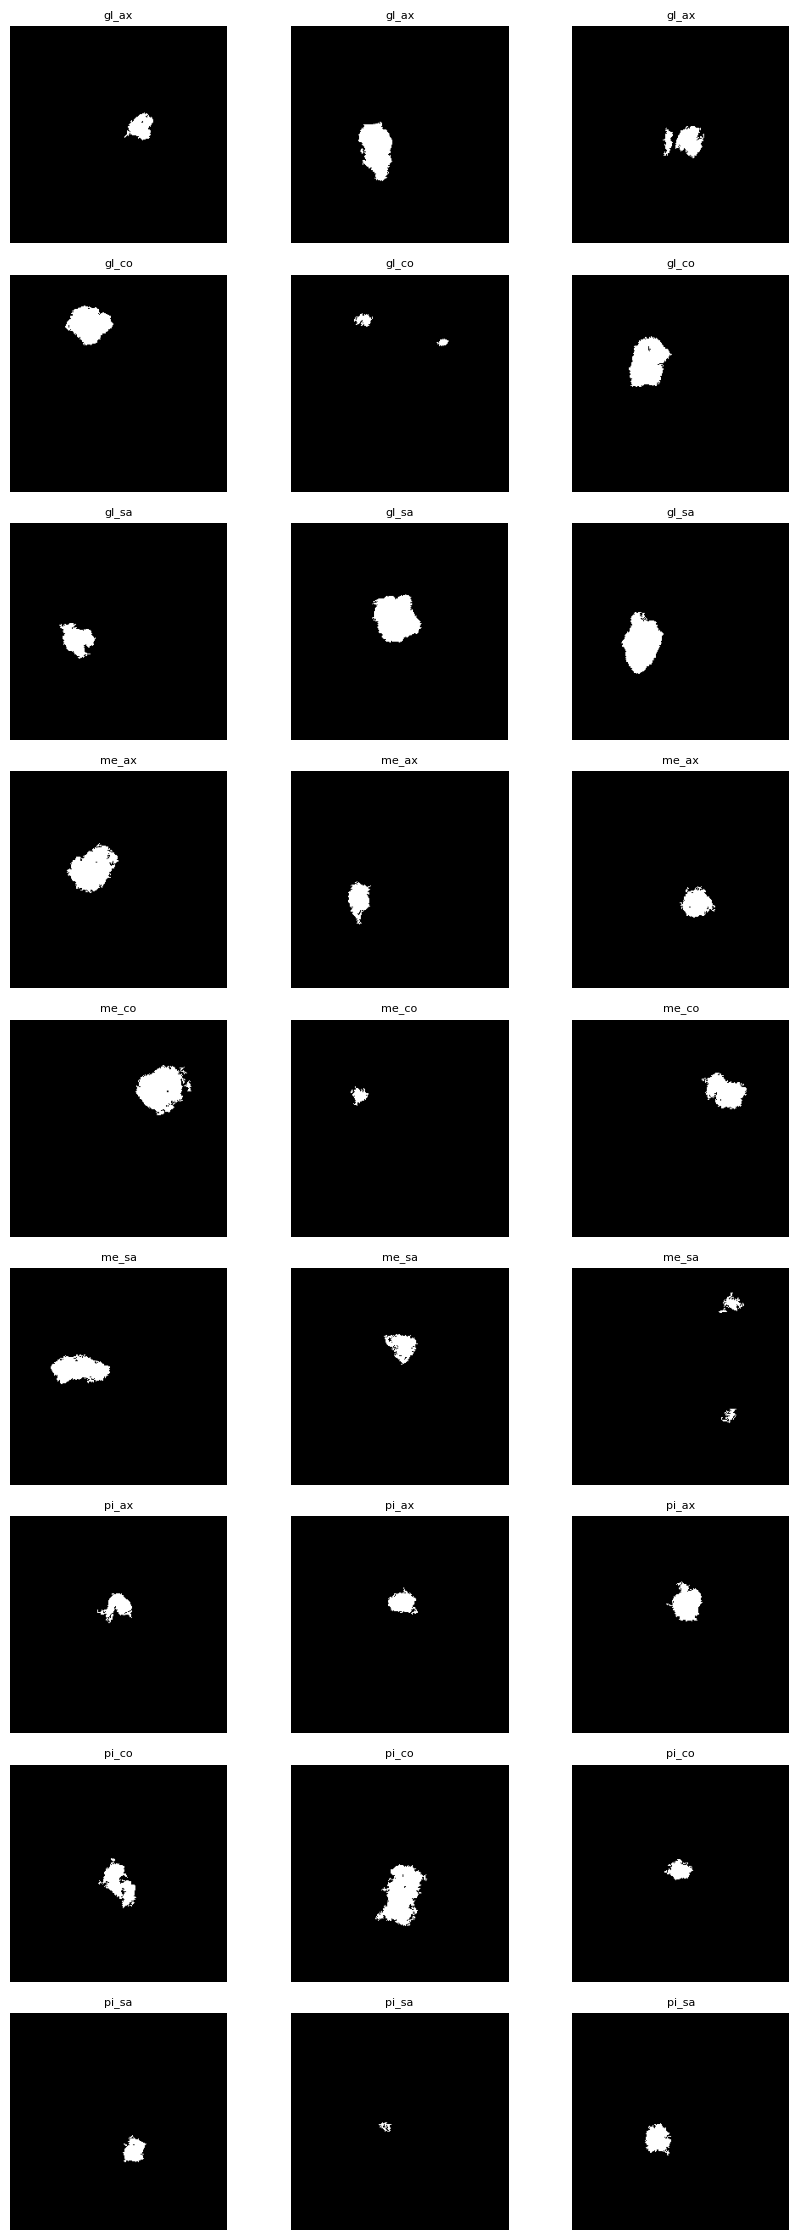

In [42]:
def show_synthetic_examples(
    manifest: pd.DataFrame,
    n_per_condition: int = 3,
    seed: int = 42,
):
    rng = np.random.default_rng(
        seed
    )

    conditions = [
        f'{t}_{p}'
        for t in ['gl', 'me', 'pi']
        for p in ['ax', 'co', 'sa']
    ]

    fig, axes = plt.subplots(
        len(conditions),
        n_per_condition,
        figsize=(
            3 * n_per_condition,
            2.5 * len(conditions),
        ),
    )

    axes = np.asarray(axes)

    if n_per_condition == 1:
        axes = axes[:, None]

    for r, cond in enumerate(
        conditions
    ):
        g = manifest.loc[
            manifest['condition'] == cond
        ]

        if len(g) == 0:
            for c in range(
                n_per_condition
            ):
                axes[r, c].axis('off')
            continue

        chosen = g.iloc[
            rng.choice(
                len(g),
                size=min(
                    n_per_condition,
                    len(g),
                ),
                replace=False,
            )
        ]

        for c in range(
            n_per_condition
        ):
            ax = axes[r, c]

            if c >= len(chosen):
                ax.axis('off')
                continue

            row = chosen.iloc[c]

            arr = np.asarray(
                Image.open(
                    row['path']
                ).convert('L')
            )

            ax.imshow(
                arr,
                cmap='gray',
                vmin=0,
                vmax=255,
            )

            ax.set_title(
                f'{cond}',
                fontsize=8,
            )

            ax.axis('off')

    plt.tight_layout()
    plt.show()


show_synthetic_examples(
    synthetic_manifest,
    n_per_condition=3,
)


## 23. Postprocesamiento y selección morfológica

Se aplican la eliminación de componentes pequeñas, el suavizado gaussiano, la binarización y los criterios de aceptación por condición.

In [43]:
POSTPROCESS_SIGMAS = [
    None,
    0.75,
    1.00,
    1.25,
    2.00,
]


def sigma_folder_name(sigma):
    if sigma is None:
        return 'sin_suavizado'

    return (
        f'suavizado'
        f'{int(round(sigma * 100)):03d}'
    )


@torch.no_grad()
def generate_final_datasets_by_sigma(
    model,
    target_per_condition: int,
    output_root: Path,
    sigmas=None,
    batch_size: int = 4,
    sampling_steps: int | None = None,
    max_attempt_factor: int | None = None,
    overwrite: bool = False,
):
    if sigmas is None:
        sigmas = POSTPROCESS_SIGMAS

    sampling_steps = (
        CFG.SAMPLING_STEPS
        if sampling_steps is None
        else sampling_steps
    )

    max_attempt_factor = (
        CFG.MAX_ATTEMPT_FACTOR
        if max_attempt_factor is None
        else int(max_attempt_factor)
    )

    output_root.mkdir(
        parents=True,
        exist_ok=True,
    )

    states = {}

    for sigma in sigmas:
        folder_name = sigma_folder_name(
            sigma
        )

        sigma_root = (
            output_root
            / folder_name
        )

        if (
            sigma_root.exists()
            and any(sigma_root.iterdir())
        ):
            if not overwrite:
                raise FileExistsError(
                    f'Ya existen resultados en '
                    f'{sigma_root}. '
                    f'Use overwrite=True para '
                    f'reemplazarlos.'
                )

            shutil.rmtree(
                sigma_root
            )

        accepted_root = (
            sigma_root
            / 'aceptadas'
        )

        rejected_root = (
            sigma_root
            / 'rechazadas'
        )

        accepted_root.mkdir(
            parents=True,
            exist_ok=True,
        )

        rejected_root.mkdir(
            parents=True,
            exist_ok=True,
        )

        states[folder_name] = {
            'sigma': sigma,
            'root': sigma_root,
            'accepted_root': accepted_root,
            'rejected_root': rejected_root,
            'accepted_records': [],
            'rejected_records': [],
            'attempt_records': [],
            'summary_rows': [],
            'global_accepted': 0,
            'global_rejected': 0,
        }

    global_attempt = 0

    for tumor_code in [
        'gl',
        'me',
        'pi',
    ]:
        for plane_code in [
            'ax',
            'co',
            'sa',
        ]:
            condition = (
                f'{tumor_code}_'
                f'{plane_code}'
            )

            accepted = {
                sigma_folder_name(sigma): 0
                for sigma in sigmas
            }

            rejected = {
                sigma_folder_name(sigma): 0
                for sigma in sigmas
            }

            processed = {
                sigma_folder_name(sigma): 0
                for sigma in sigmas
            }

            for sigma in sigmas:
                folder_name = (
                    sigma_folder_name(
                        sigma
                    )
                )

                (
                    states[folder_name]
                    ['accepted_root']
                    / condition
                ).mkdir(
                    parents=True,
                    exist_ok=True,
                )

                (
                    states[folder_name]
                    ['rejected_root']
                    / condition
                ).mkdir(
                    parents=True,
                    exist_ok=True,
                )

            attempts = 0

            max_attempts = (
                target_per_condition
                * max_attempt_factor
            )

            while (
                not all(
                    accepted[
                        sigma_folder_name(
                            sigma
                        )
                    ]
                    >= target_per_condition
                    for sigma in sigmas
                )
                and attempts
                < max_attempts
            ):
                current_bs = min(
                    batch_size,
                    max_attempts
                    - attempts,
                )

                tumor_ids = [
                    TUMOR_TO_ID[
                        tumor_code
                    ]
                ] * current_bs

                plane_ids = [
                    PLANE_TO_ID[
                        plane_code
                    ]
                ] * current_bs

                samples = (
                    sample_bernoulli(
                        model,
                        tumor_id=tumor_ids,
                        plane_id=plane_ids,
                        image_size=(
                            CFG.IMAGE_SIZE
                        ),
                        sampling_steps=(
                            sampling_steps
                        ),
                    )
                )

                samples_np = (
                    samples
                    .cpu()
                    .numpy()
                    .astype(
                        np.uint8
                    )
                )

                for jj in range(
                    current_bs
                ):
                    if all(
                        accepted[
                            sigma_folder_name(
                                sigma
                            )
                        ]
                        >= target_per_condition
                        for sigma in sigmas
                    ):
                        break

                    if (
                        attempts
                        >= max_attempts
                    ):
                        break

                    attempts += 1
                    global_attempt += 1

                    raw_binary = (
                        samples_np[
                            jj,
                            0,
                        ]
                    )

                    cleaned = (
                        remove_tiny_components(
                            raw_binary,
                            CFG.MIN_COMPONENT_PIXELS,
                        )
                    )

                    filename = (
                        f'oe2_attempt_'
                        f'{global_attempt:06d}_'
                        f'{tumor_code}_'
                        f'{plane_code}.png'
                    )

                    for sigma in sigmas:
                        folder_name = (
                            sigma_folder_name(
                                sigma
                            )
                        )

                        if (
                            accepted[
                                folder_name
                            ]
                            >= target_per_condition
                        ):
                            continue

                        state = states[
                            folder_name
                        ]

                        if sigma is None:
                            final_binary = (
                                cleaned.copy()
                            )
                        else:
                            (
                                _,
                                final_binary,
                            ) = (
                                gaussian_postprocess_binary(
                                    cleaned,
                                    sigma=float(
                                        sigma
                                    ),
                                    threshold=(
                                        CFG.POSTPROCESS_THRESHOLD
                                    ),
                                )
                            )

                        (
                            qc_pass,
                            feat,
                            reasons,
                        ) = (
                            check_plausibility(
                                final_binary,
                                condition,
                                qc_ranges,
                            )
                        )

                        processed[
                            folder_name
                        ] += 1

                        base_record = {
                            'attempt_global': (
                                global_attempt
                            ),
                            'attempt_condition': (
                                attempts
                            ),
                            'tumor_code': (
                                tumor_code
                            ),
                            'tumor': (
                                TUMOR_MAP[
                                    tumor_code
                                ]
                            ),
                            'plane_code': (
                                plane_code
                            ),
                            'plane': (
                                PLANE_MAP[
                                    plane_code
                                ]
                            ),
                            'condition': (
                                condition
                            ),
                            'method': (
                                'bernoulli'
                            ),
                            'profile': (
                                CFG.PROFILE
                            ),
                            'roi_outside_weight': (
                                CFG.ROI_OUTSIDE_WEIGHT
                            ),
                            'sampling_steps': (
                                sampling_steps
                            ),
                            'bernoulli_threshold': (
                                CFG.THRESHOLD
                            ),
                            'min_component_pixels': (
                                CFG.MIN_COMPONENT_PIXELS
                            ),
                            'postprocess_sigma': (
                                sigma
                            ),
                            'postprocess_label': (
                                folder_name
                            ),
                            'postprocess_threshold': (
                                None
                                if sigma is None
                                else CFG.POSTPROCESS_THRESHOLD
                            ),
                            'raw_area_pixels': (
                                int(
                                    raw_binary.sum()
                                )
                            ),
                            'cleaned_area_pixels': (
                                int(
                                    cleaned.sum()
                                )
                            ),
                            'final_area_pixels': (
                                int(
                                    final_binary.sum()
                                )
                            ),
                            'qc_pass': (
                                bool(
                                    qc_pass
                                )
                            ),
                            'qc_reasons': (
                                ' | '.join(
                                    reasons
                                )
                            ),
                            **feat,
                        }

                        if qc_pass:
                            out_path = (
                                state[
                                    'accepted_root'
                                ]
                                / condition
                                / filename
                            )

                            accepted[
                                folder_name
                            ] += 1

                            state[
                                'global_accepted'
                            ] += 1

                            status = (
                                'accepted'
                            )

                        else:
                            out_path = (
                                state[
                                    'rejected_root'
                                ]
                                / condition
                                / filename
                            )

                            rejected[
                                folder_name
                            ] += 1

                            state[
                                'global_rejected'
                            ] += 1

                            status = (
                                'rejected'
                            )

                        Image.fromarray(
                            final_binary
                            * 255,
                            mode='L',
                        ).save(
                            out_path
                        )

                        record = {
                            'filename': (
                                filename
                            ),
                            'path': (
                                str(
                                    out_path
                                )
                            ),
                            'status': (
                                status
                            ),
                            **base_record,
                        }

                        state[
                            'attempt_records'
                        ].append(
                            record
                        )

                        if qc_pass:
                            state[
                                'accepted_records'
                            ].append(
                                record
                            )
                        else:
                            state[
                                'rejected_records'
                            ].append(
                                record
                            )

            for sigma in sigmas:
                folder_name = (
                    sigma_folder_name(
                        sigma
                    )
                )

                n_processed = (
                    processed[
                        folder_name
                    ]
                )

                acceptance_rate = (
                    accepted[
                        folder_name
                    ]
                    / n_processed
                    if n_processed > 0
                    else np.nan
                )

                states[
                    folder_name
                ][
                    'summary_rows'
                ].append({
                    'condition': (
                        condition
                    ),
                    'sigma': (
                        sigma
                    ),
                    'target': (
                        target_per_condition
                    ),
                    'accepted': (
                        accepted[
                            folder_name
                        ]
                    ),
                    'rejected': (
                        rejected[
                            folder_name
                        ]
                    ),
                    'attempts': (
                        n_processed
                    ),
                    'acceptance_rate': (
                        acceptance_rate
                    ),
                    'max_attempts': (
                        max_attempts
                    ),
                })

                sigma_label = (
                    'None'
                    if sigma is None
                    else f'{sigma:.2f}'
                )

                print(
                    f'{condition} | '
                    f'sigma={sigma_label}: '
                    f'{accepted[folder_name]}/'
                    f'{target_per_condition} '
                    f'aceptadas en '
                    f'{n_processed} intentos '
                    f'('
                    f'{100 * acceptance_rate:.2f}%'
                    f')'
                )

                if (
                    accepted[
                        folder_name
                    ]
                    < target_per_condition
                ):
                    print(
                        '  ADVERTENCIA: '
                        'no se alcanzó '
                        'el objetivo.'
                    )

    results = {}

    for sigma in sigmas:
        folder_name = (
            sigma_folder_name(
                sigma
            )
        )

        state = states[
            folder_name
        ]

        accepted_df = (
            pd.DataFrame(
                state[
                    'accepted_records'
                ]
            )
        )

        rejected_df = (
            pd.DataFrame(
                state[
                    'rejected_records'
                ]
            )
        )

        attempts_df = (
            pd.DataFrame(
                state[
                    'attempt_records'
                ]
            )
        )

        acceptance_summary_df = (
            pd.DataFrame(
                state[
                    'summary_rows'
                ]
            )
        )

        accepted_df.to_csv(
            state['root']
            / 'manifest_accepted.csv',
            index=False,
        )

        rejected_df.to_csv(
            state['root']
            / 'manifest_rejected.csv',
            index=False,
        )

        attempts_df.to_csv(
            state['root']
            / 'manifest_attempts.csv',
            index=False,
        )

        acceptance_summary_df.to_csv(
            state['root']
            / 'resumen_aceptacion.csv',
            index=False,
        )

        results[
            folder_name
        ] = {
            'sigma': sigma,
            'accepted': (
                accepted_df
            ),
            'rejected': (
                rejected_df
            ),
            'attempts': (
                attempts_df
            ),
            'summary': (
                acceptance_summary_df
            ),
        }

    return results


### 23.1 Generación de las máscaras finales

Se generan las máscaras aceptadas para cada configuración de suavizado o se reutilizan los conjuntos completos existentes.

In [44]:
# Producción final y reutilización de resultados completos.
TARGET_PER_CONDITION = 100


def cargar_resultados_finales_existentes(output_root, sigmas, target):
    resultado = {}
    todas_completas = True
    for sigma in sigmas:
        nombre = sigma_folder_name(sigma)
        carpeta = output_root / nombre
        archivos = {
            'accepted': carpeta / 'manifest_accepted.csv',
            'rejected': carpeta / 'manifest_rejected.csv',
            'attempts': carpeta / 'manifest_attempts.csv',
            'summary': carpeta / 'resumen_aceptacion.csv',
        }
        if not all(archivo.is_file() for archivo in archivos.values()):
            todas_completas = False
            break
        accepted = pd.read_csv(archivos['accepted'])
        counts = accepted['condition'].value_counts()
        condiciones = {f'{t}_{p}' for t in ('gl','me','pi') for p in ('ax','co','sa')}
        if set(counts.index) != condiciones or not (counts == target).all():
            todas_completas = False
            break
        # Comprobar el archivo esperado, independientemente del path histórico del manifiesto.
        if not all(
            (carpeta / 'aceptadas' / fila.condition / fila.filename).is_file()
            for fila in accepted.itertuples()
        ):
            todas_completas = False
            break
        resultado[nombre] = {
            'sigma': sigma,
            'accepted': accepted,
            'rejected': pd.read_csv(archivos['rejected']),
            'attempts': pd.read_csv(archivos['attempts']),
            'summary': pd.read_csv(archivos['summary']),
        }
    return resultado if todas_completas else None


final_results = cargar_resultados_finales_existentes(
    FINAL_SYNTH_DIR, POSTPROCESS_SIGMAS, TARGET_PER_CONDITION
)
if final_results is None:
    final_results = generate_final_datasets_by_sigma(
        best_model,
        target_per_condition=TARGET_PER_CONDITION,
        output_root=FINAL_SYNTH_DIR,
        sigmas=POSTPROCESS_SIGMAS,
        batch_size=max(1, min(CFG.BATCH_SIZE, 4)),
        overwrite=False,
    )
else:
    print('Se reutilizan las máscaras finales y sus registros de aceptación.')


Se reutilizan las máscaras finales y sus registros de aceptación.


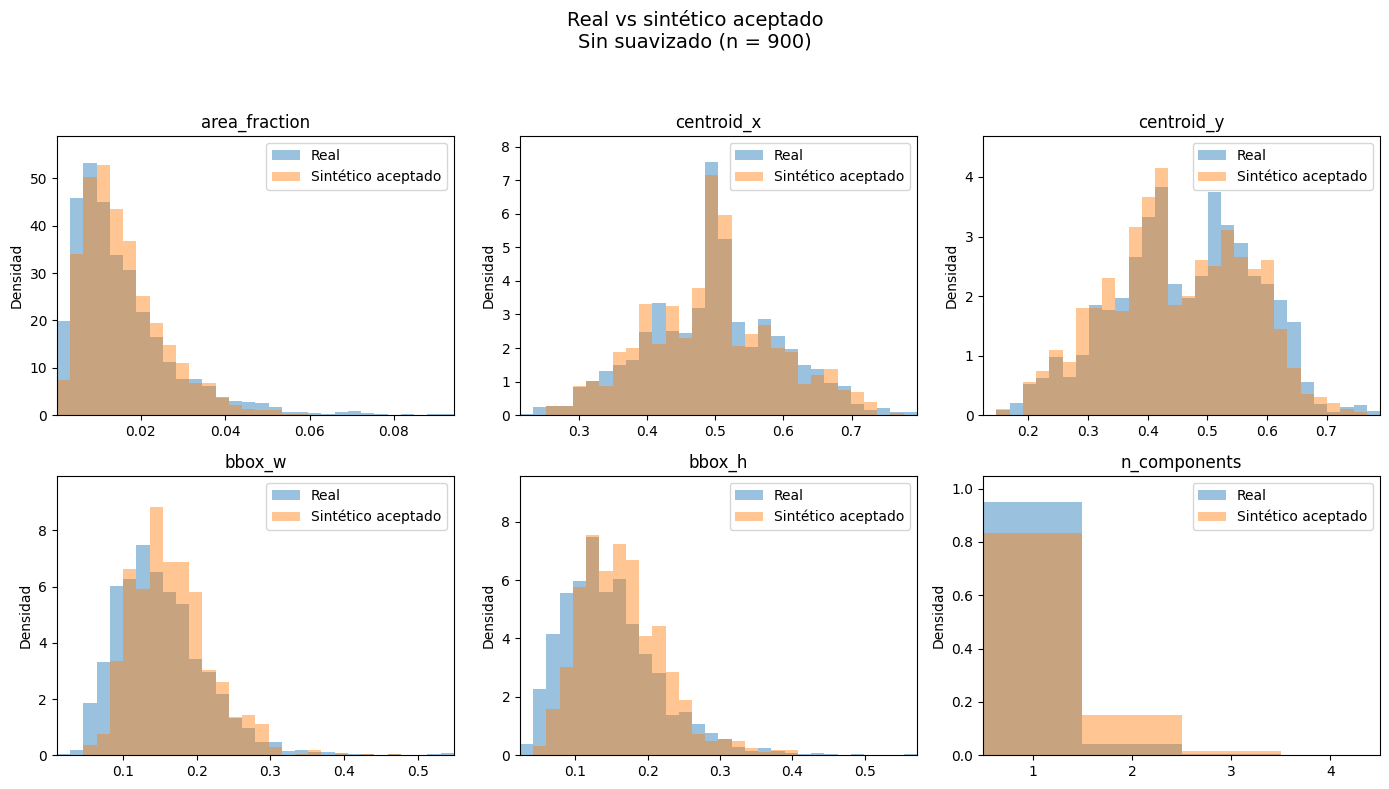

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\morfologia_real_vs_aceptadas_sin_suavizado.png


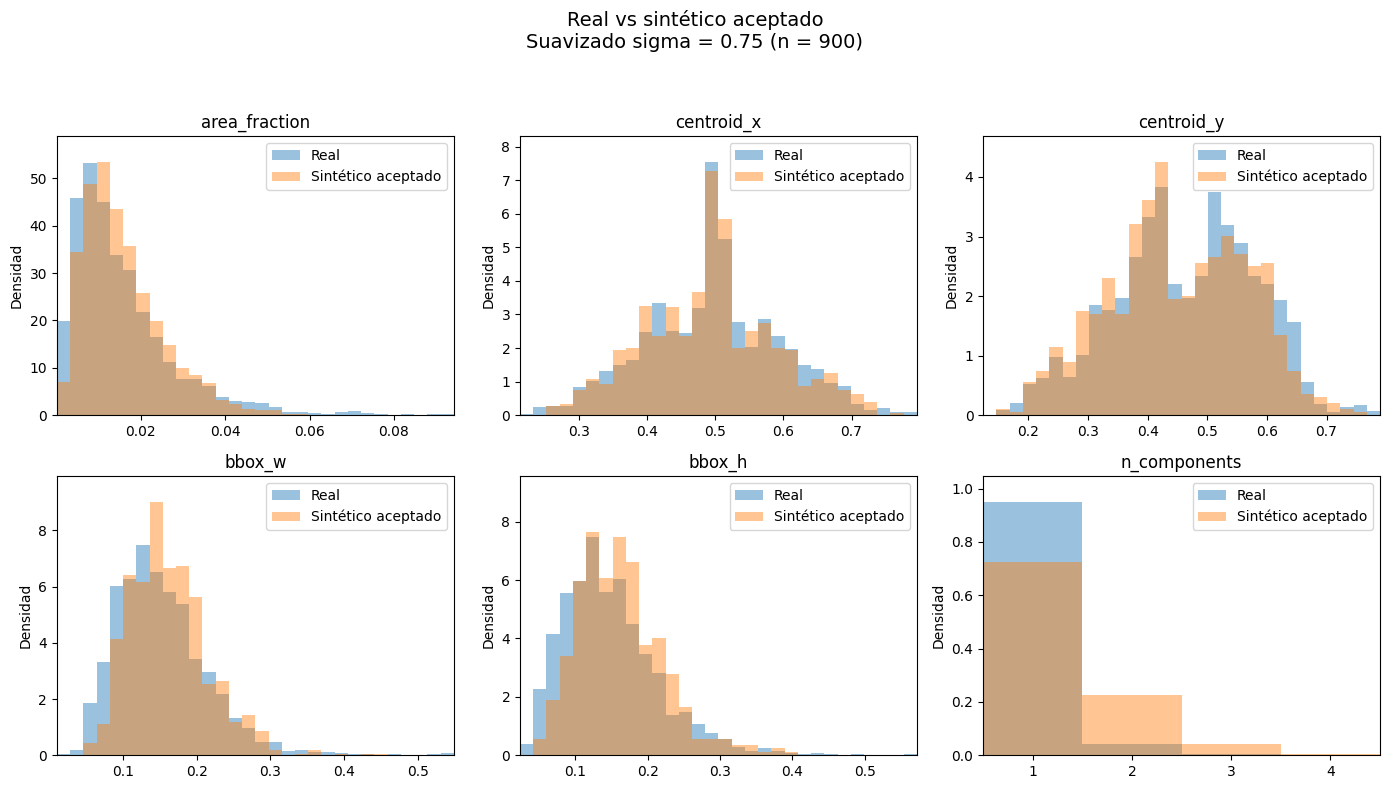

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\morfologia_real_vs_aceptadas_suavizado075.png


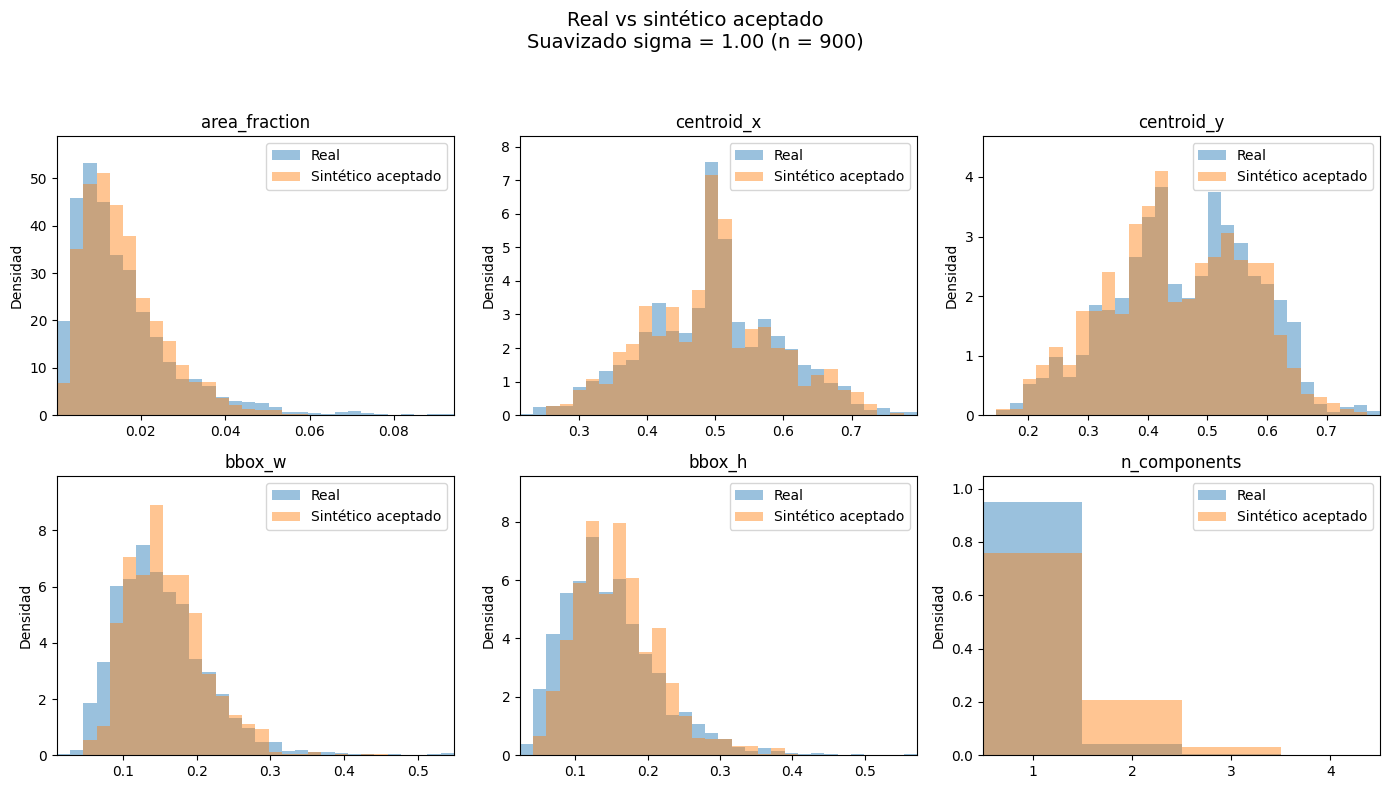

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\morfologia_real_vs_aceptadas_suavizado100.png


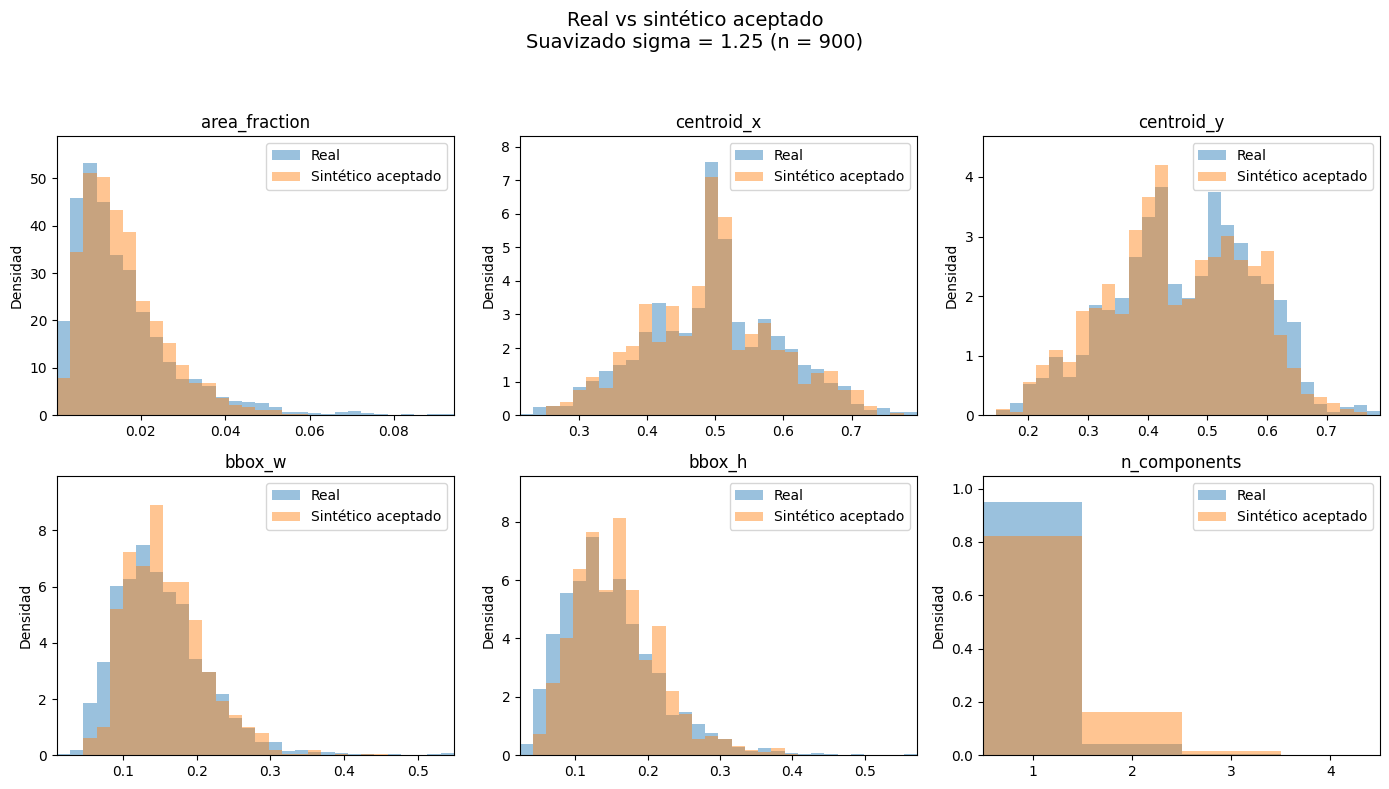

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\morfologia_real_vs_aceptadas_suavizado125.png


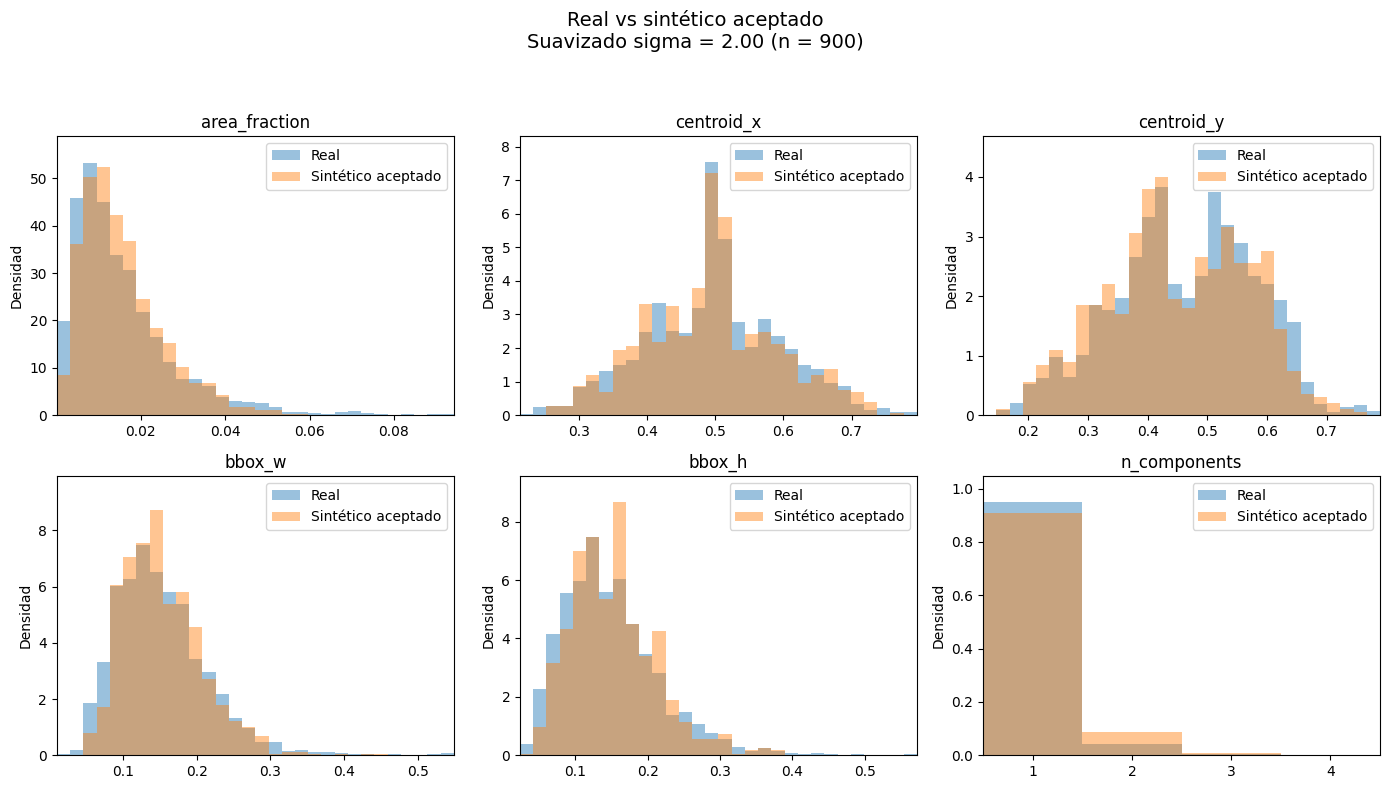

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\morfologia_real_vs_aceptadas_suavizado200.png


In [45]:
# Comparación entre máscaras reales y sintéticas aceptadas.

ACCEPTED_DIAGNOSTIC_DIR = (
    DIAGNOSTIC_DIR
    / 'comparacion_morfologia_aceptadas'
)

ACCEPTED_DIAGNOSTIC_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

metrics_plot = (
    QC_CONTINUOUS
    + ['n_components']
)

compare_cols = (
    ['condition', 'source']
    + QC_CONTINUOUS
    + ['n_components']
)

real_for_compare = train_df.copy()
real_for_compare['source'] = 'Real'

accepted_by_sigma = {}

for sigma in POSTPROCESS_SIGMAS:

    folder_name = sigma_folder_name(
        sigma
    )

    manifest_path = (
        FINAL_SYNTH_DIR
        / folder_name
        / 'manifest_accepted.csv'
    )

    if not manifest_path.exists():
        print(
            f'No encontrado: '
            f'{manifest_path}'
        )
        continue

    accepted_df = pd.read_csv(
        manifest_path
    )

    if accepted_df.empty:
        print(
            f'Sin máscaras aceptadas: '
            f'{folder_name}'
        )
        continue

    accepted_df = accepted_df.copy()
    accepted_df['source'] = 'Sintético aceptado'

    accepted_by_sigma[sigma] = accepted_df

all_synth_accepted = pd.concat(
    accepted_by_sigma.values(),
    ignore_index=True,
)

global_bins = {}
global_xlim = {}
global_ylim = {}

for metric in metrics_plot:

    real_vals = (
        real_for_compare[metric]
        .dropna()
        .to_numpy()
    )

    synth_vals = (
        all_synth_accepted[metric]
        .dropna()
        .to_numpy()
    )

    all_vals = np.concatenate(
        [real_vals, synth_vals]
    )

    if metric == 'n_components':

        min_value = int(all_vals.min())
        max_value = int(all_vals.max())

        bins = np.arange(
            min_value - 0.5,
            max_value + 1.5,
            1,
        )

        xlim = (
            min_value - 0.5,
            max_value + 0.5,
        )

    else:
        min_value = float(all_vals.min())
        max_value = float(all_vals.max())

        if min_value == max_value:
            min_value -= 0.5
            max_value += 0.5

        bins = np.linspace(
            min_value,
            max_value,
            31,
        )

        xlim = (
            min_value,
            max_value,
        )

    global_bins[metric] = bins
    global_xlim[metric] = xlim

    density_max = 0.0

    hist_real, _ = np.histogram(
        real_vals,
        bins=bins,
        density=True,
    )
    density_max = max(
        density_max,
        hist_real.max() if len(hist_real) else 0.0,
    )

    for sigma, accepted_df in accepted_by_sigma.items():

        synth_vals_sigma = (
            accepted_df[metric]
            .dropna()
            .to_numpy()
        )

        hist_synth, _ = np.histogram(
            synth_vals_sigma,
            bins=bins,
            density=True,
        )

        density_max = max(
            density_max,
            hist_synth.max() if len(hist_synth) else 0.0,
        )

    global_ylim[metric] = (
        0,
        density_max * 1.10,
    )

for sigma in POSTPROCESS_SIGMAS:

    if sigma not in accepted_by_sigma:
        continue

    accepted_df = accepted_by_sigma[sigma]

    combined_accepted = pd.concat(
        [
            real_for_compare[
                compare_cols
            ],
            accepted_df[
                compare_cols
            ],
        ],
        ignore_index=True,
    )

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(14, 8),
    )

    axes = axes.ravel()

    for ax, metric in zip(
        axes,
        metrics_plot,
    ):

        real_vals = (
            combined_accepted.loc[
                combined_accepted[
                    'source'
                ] == 'Real',
                metric,
            ]
            .dropna()
        )

        synth_vals = (
            combined_accepted.loc[
                combined_accepted[
                    'source'
                ] == 'Sintético aceptado',
                metric,
            ]
            .dropna()
        )

        bins = global_bins[metric]

        ax.hist(
            real_vals,
            bins=bins,
            density=True,
            alpha=0.45,
            label='Real',
        )

        ax.hist(
            synth_vals,
            bins=bins,
            density=True,
            alpha=0.45,
            label='Sintético aceptado',
        )

        ax.set_title(
            metric
        )
        if metric == 'n_components':
            ax.set_xticks(
                np.arange(
                    int(global_xlim[metric][0] + 0.5),
                    int(global_xlim[metric][1] + 0.5) + 1,
                    1,
                )
            )

        ax.set_xlim(
            global_xlim[metric]
        )

        ax.set_ylim(
            global_ylim[metric]
        )

        ax.set_ylabel(
            'Densidad'
        )

        ax.legend()

    sigma_label = (
        'Sin suavizado'
        if sigma is None
        else f'Suavizado sigma = {sigma:.2f}'
    )

    fig.suptitle(
        (
            f'Real vs sintético aceptado\n'
            f'{sigma_label} '
            f'(n = {len(accepted_df)})'
        ),
        fontsize=14,
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.94]
    )

    output_path = (
        ACCEPTED_DIAGNOSTIC_DIR
        / (
            f'morfologia_real_vs_'
            f'aceptadas_{sigma_folder_name(sigma)}.png'
        )
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()

    print(
        f'Guardado: {output_path}'
    )


### 23.2 Comparación morfológica equilibrada de máscaras aceptadas

Se comparan los atributos morfológicos manteniendo la misma contribución de las nueve condiciones.

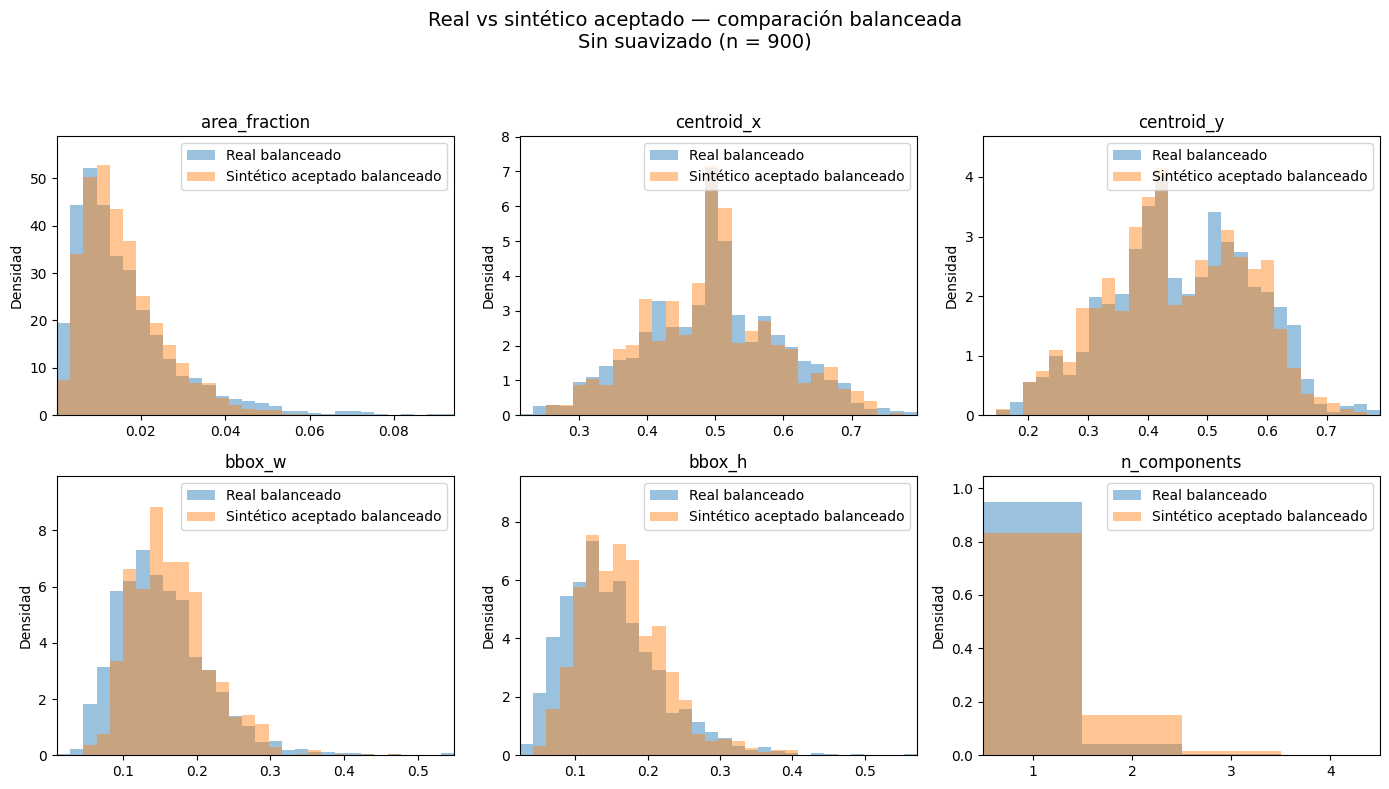

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\comparacion_balanceada\morfologia_balanceada_sin_suavizado.png


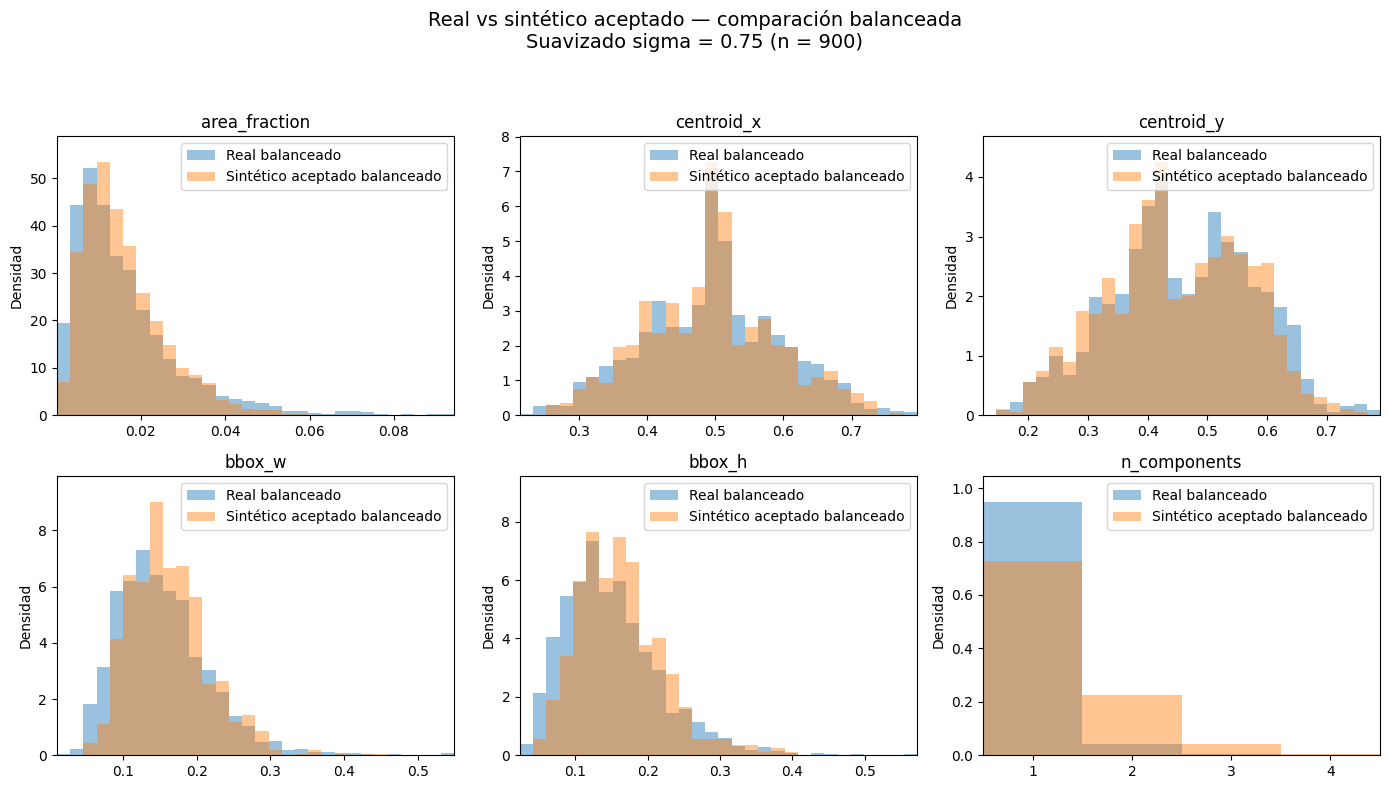

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\comparacion_balanceada\morfologia_balanceada_suavizado075.png


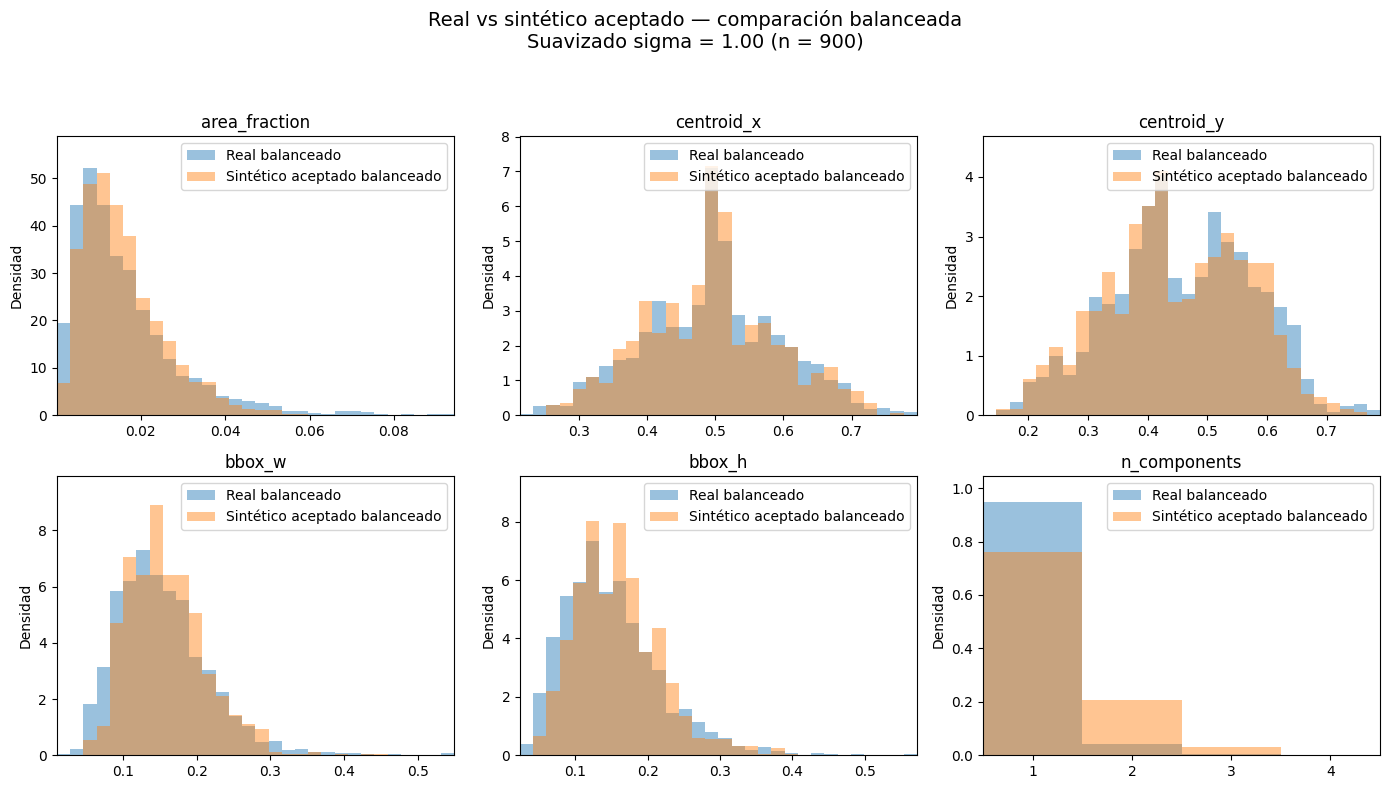

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\comparacion_balanceada\morfologia_balanceada_suavizado100.png


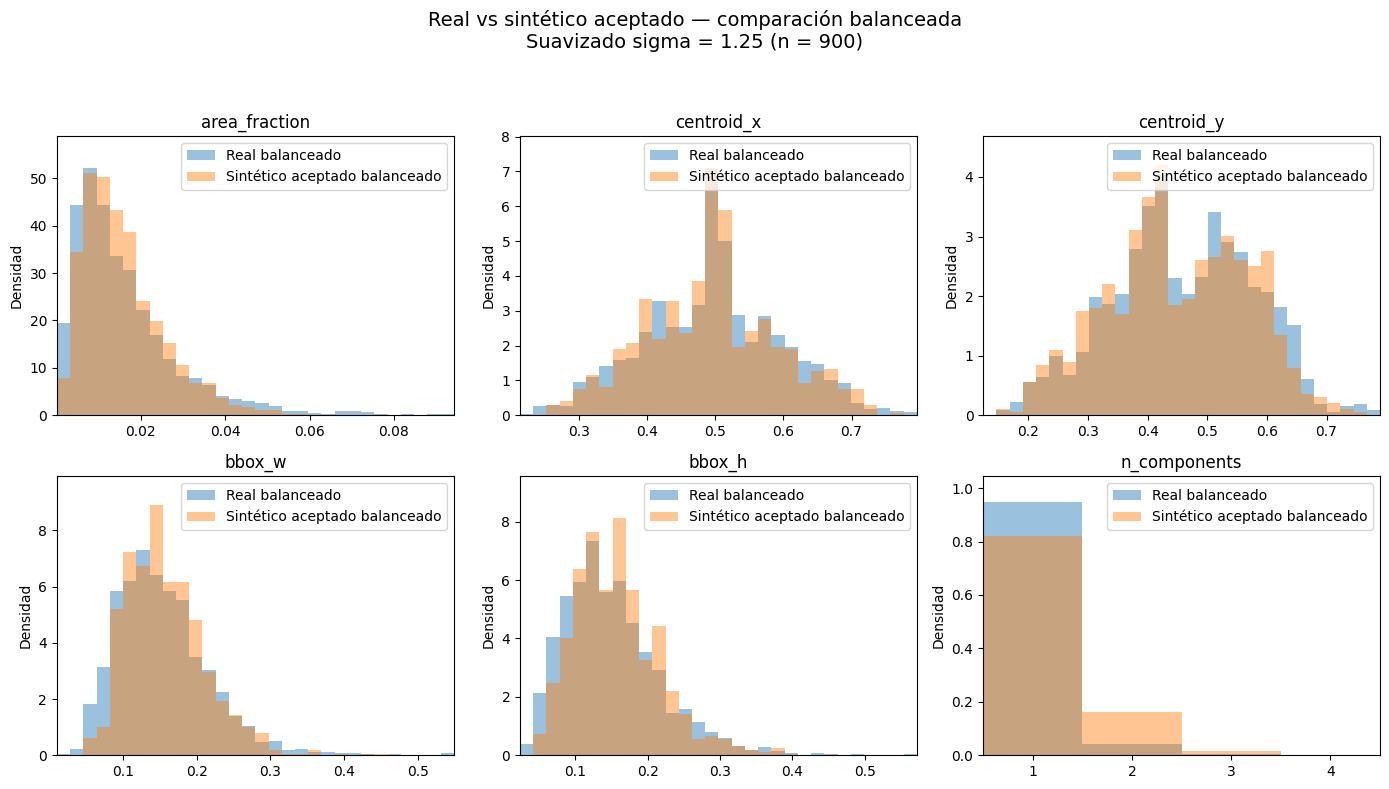

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\comparacion_balanceada\morfologia_balanceada_suavizado125.png


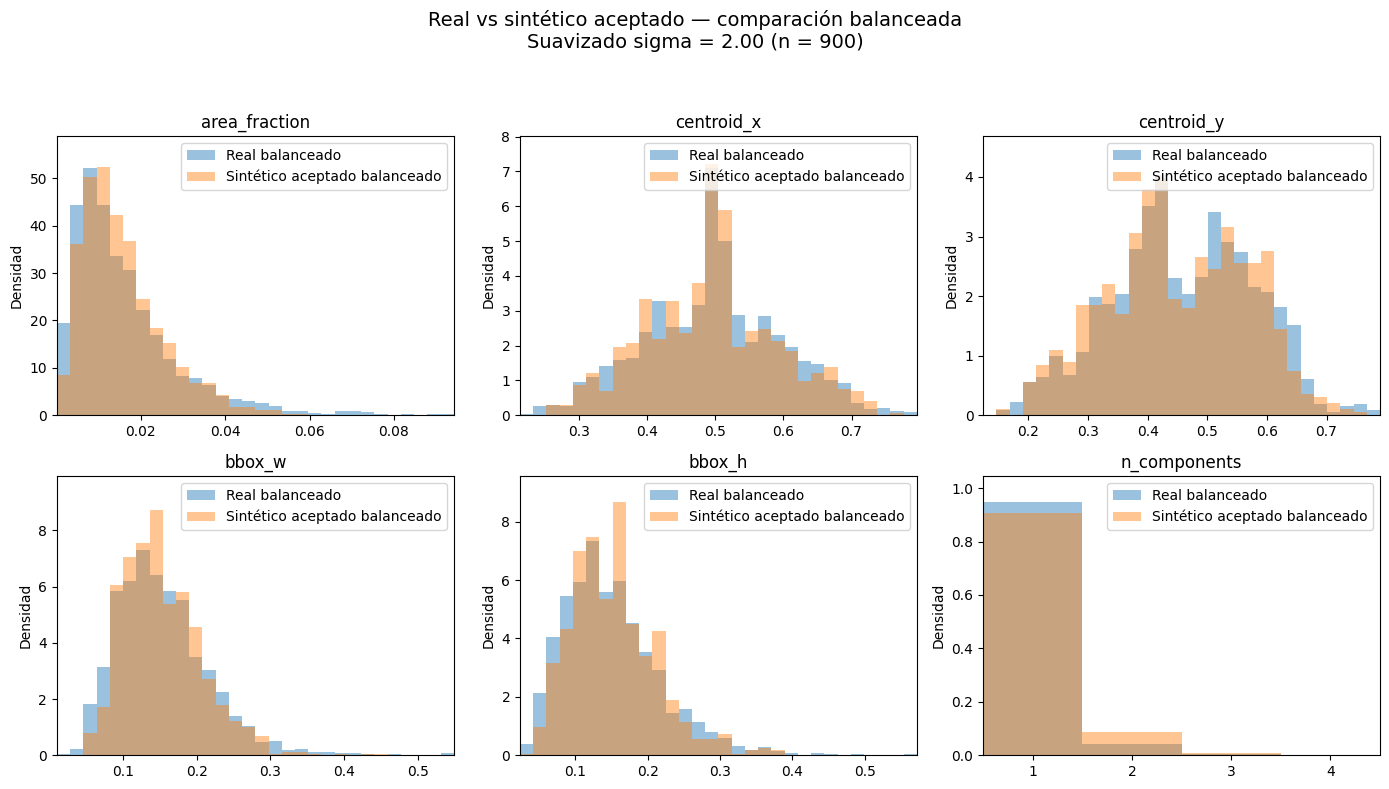

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\comparacion_balanceada\morfologia_balanceada_suavizado200.png


In [46]:
BALANCED_DIAGNOSTIC_DIR = (
    ACCEPTED_DIAGNOSTIC_DIR
    / 'comparacion_balanceada'
)

BALANCED_DIAGNOSTIC_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def balanced_values_weights(
    df,
    metric,
):
    tmp = (
        df[
            ['condition', metric]
        ]
        .dropna()
        .copy()
    )

    condition_counts = (
        tmp['condition']
        .value_counts()
    )

    n_conditions = len(
        condition_counts
    )

    weights = (
        tmp['condition']
        .map(
            lambda condition:
            1.0
            / (
                n_conditions
                * condition_counts[
                    condition
                ]
            )
        )
        .to_numpy()
    )

    values = (
        tmp[metric]
        .to_numpy()
    )

    return values, weights


balanced_ylim = {}

for metric in metrics_plot:

    bins = global_bins[metric]

    real_vals, real_weights = (
        balanced_values_weights(
            real_for_compare,
            metric,
        )
    )

    hist_real, _ = np.histogram(
        real_vals,
        bins=bins,
        weights=real_weights,
        density=True,
    )

    density_max = (
        hist_real.max()
        if len(hist_real)
        else 0.0
    )

    for sigma, accepted_df in (
        accepted_by_sigma.items()
    ):

        synth_vals, synth_weights = (
            balanced_values_weights(
                accepted_df,
                metric,
            )
        )

        hist_synth, _ = np.histogram(
            synth_vals,
            bins=bins,
            weights=synth_weights,
            density=True,
        )

        if len(hist_synth):
            density_max = max(
                density_max,
                hist_synth.max(),
            )

    balanced_ylim[metric] = (
        0,
        density_max * 1.10,
    )


for sigma in POSTPROCESS_SIGMAS:

    if sigma not in accepted_by_sigma:
        continue

    accepted_df = (
        accepted_by_sigma[sigma]
    )

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(14, 8),
    )

    axes = axes.ravel()

    for ax, metric in zip(
        axes,
        metrics_plot,
    ):

        bins = global_bins[metric]

        real_vals, real_weights = (
            balanced_values_weights(
                real_for_compare,
                metric,
            )
        )

        synth_vals, synth_weights = (
            balanced_values_weights(
                accepted_df,
                metric,
            )
        )

        ax.hist(
            real_vals,
            bins=bins,
            weights=real_weights,
            density=True,
            alpha=0.45,
            label='Real balanceado',
        )

        ax.hist(
            synth_vals,
            bins=bins,
            weights=synth_weights,
            density=True,
            alpha=0.45,
            label='Sintético aceptado balanceado',
        )

        ax.set_title(
            metric
        )

        ax.set_xlim(
            global_xlim[metric]
        )

        ax.set_ylim(
            balanced_ylim[metric]
        )

        if metric == 'n_components':

            min_component = int(
                global_bins[
                    metric
                ][0] + 0.5
            )

            max_component = int(
                global_bins[
                    metric
                ][-1] - 0.5
            )

            ax.set_xticks(
                np.arange(
                    min_component,
                    max_component + 1,
                    1,
                )
            )

        ax.set_ylabel(
            'Densidad'
        )

        ax.legend()

    sigma_label = (
        'Sin suavizado'
        if sigma is None
        else (
            f'Suavizado sigma = '
            f'{sigma:.2f}'
        )
    )

    fig.suptitle(
        (
            'Real vs sintético aceptado '
            '— comparación balanceada\n'
            f'{sigma_label} '
            f'(n = {len(accepted_df)})'
        ),
        fontsize=14,
    )

    plt.tight_layout(
        rect=[
            0,
            0,
            1,
            0.94,
        ]
    )

    output_path = (
        BALANCED_DIAGNOSTIC_DIR
        / (
            f'morfologia_balanceada_'
            f'{sigma_folder_name(sigma)}.png'
        )
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches='tight',
    )

    plt.show()

    print(
        f'Guardado: {output_path}'
    )


### 23.3 Diagnóstico de máscaras preliminares

Se comparan las máscaras previas al control final con las distribuciones de referencia.

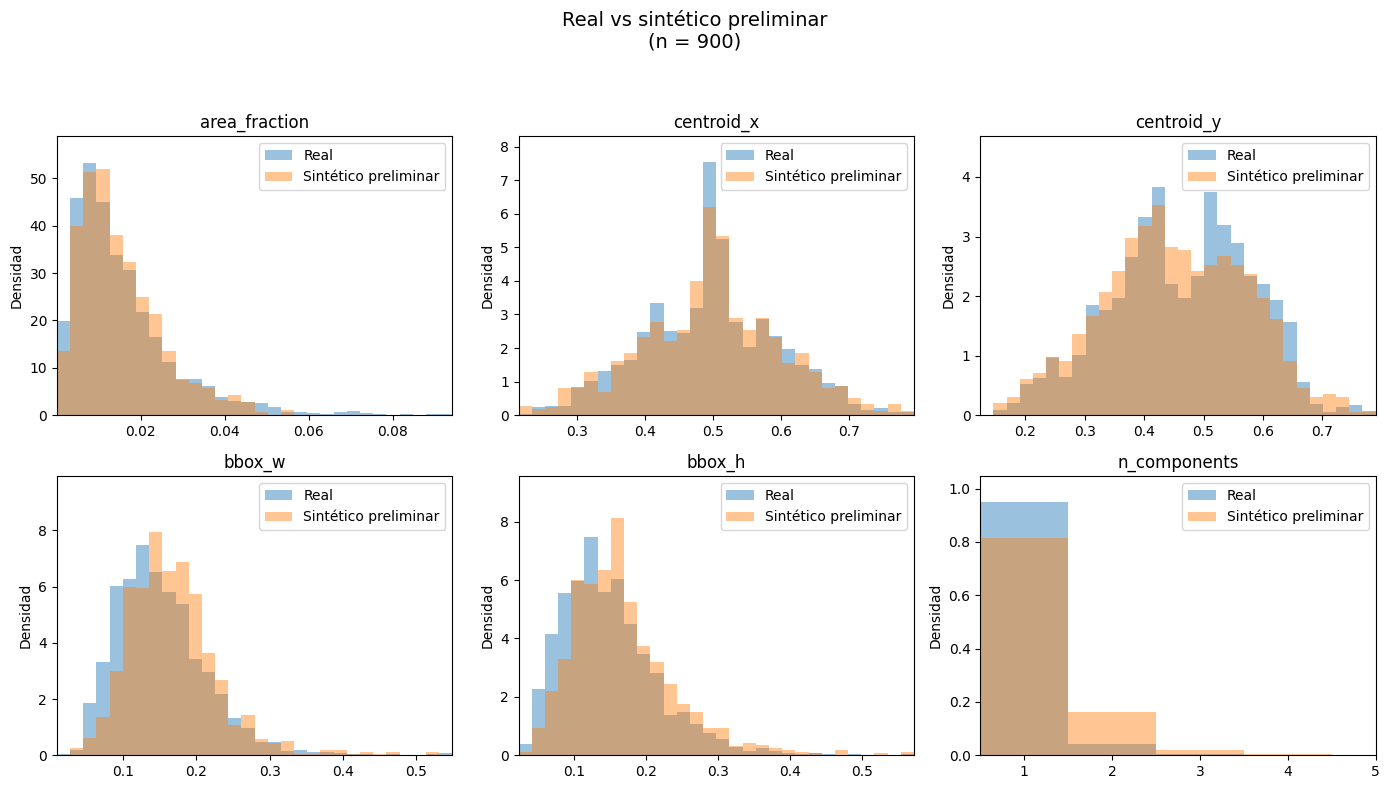

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\morfologia_real_vs_preliminares.png


In [47]:
# Comparación entre máscaras reales y sintéticas preliminares.

ACCEPTED_DIAGNOSTIC_DIR = (
    DIAGNOSTIC_DIR
    / 'comparacion_morfologia_aceptadas'
)

ACCEPTED_DIAGNOSTIC_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

metrics_plot = (
    QC_CONTINUOUS
    + ['n_components']
)

compare_cols = (
    ['condition', 'source']
    + QC_CONTINUOUS
    + ['n_components']
)

manifest_prelim_path = (
    SYNTH_DIR
    / 'manifest_synthetic.csv'
)

if 'synthetic_manifest' in globals():
    prelim_df = synthetic_manifest.copy()
elif manifest_prelim_path.exists():
    prelim_df = pd.read_csv(
        manifest_prelim_path
    )
else:
    raise FileNotFoundError(
        f'No se encontró {manifest_prelim_path}'
    )

if prelim_df.empty:
    raise RuntimeError(
        'El manifest preliminar está vacío.'
    )

real_for_compare = train_df.copy()
real_for_compare['source'] = 'Real'

prelim_for_compare = prelim_df.copy()
prelim_for_compare['source'] = 'Sintético preliminar'

combined_prelim = pd.concat(
    [
        real_for_compare[
            compare_cols
        ],
        prelim_for_compare[
            compare_cols
        ],
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(14, 8),
)

axes = axes.ravel()

for ax, metric in zip(
    axes,
    metrics_plot,
):

    real_vals = (
        combined_prelim.loc[
            combined_prelim[
                'source'
            ] == 'Real',
            metric,
        ]
        .dropna()
    )

    prelim_vals = (
        combined_prelim.loc[
            combined_prelim[
                'source'
            ] == 'Sintético preliminar',
            metric,
        ]
        .dropna()
    )

    if 'global_bins' in globals():
        bins = global_bins[metric]
        xlim = global_xlim[metric]
        ylim = global_ylim[metric]
    else:
        all_vals = np.concatenate(
            [
                real_vals.to_numpy(),
                prelim_vals.to_numpy(),
            ]
        )

        if metric == 'n_components':
            min_value = int(all_vals.min())
            max_value = int(all_vals.max())

            bins = np.arange(
                min_value - 0.5,
                max_value + 1.5,
                1,
            )

            xlim = (
                min_value - 0.5,
                max_value + 0.5,
            )
        else:
            min_value = float(all_vals.min())
            max_value = float(all_vals.max())

            if min_value == max_value:
                min_value -= 0.5
                max_value += 0.5

            bins = np.linspace(
                min_value,
                max_value,
                31,
            )

            xlim = (
                min_value,
                max_value,
            )

        hist_real, _ = np.histogram(
            real_vals,
            bins=bins,
            density=True,
        )
        hist_prelim, _ = np.histogram(
            prelim_vals,
            bins=bins,
            density=True,
        )

        density_max = max(
            hist_real.max() if len(hist_real) else 0.0,
            hist_prelim.max() if len(hist_prelim) else 0.0,
        )

        ylim = (
            0,
            density_max * 1.10,
        )

    ax.hist(
        real_vals,
        bins=bins,
        density=True,
        alpha=0.45,
        label='Real',
    )

    ax.hist(
        prelim_vals,
        bins=bins,
        density=True,
        alpha=0.45,
        label='Sintético preliminar',
    )

    ax.set_title(
        metric
    )

    ax.set_xlim(
        xlim
    )

    if metric == 'n_components':
        ax.set_xticks(
            np.arange(
                int(xlim[0] + 0.5),
                int(xlim[1] + 0.5) + 1,
                1,
            )
        )

    ax.set_ylim(
        ylim
    )

    ax.set_ylabel(
        'Densidad'
    )

    ax.legend()

fig.suptitle(
    (
        'Real vs sintético preliminar\n'
        f'(n = {len(prelim_df)})'
    ),
    fontsize=14,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

output_path = (
    ACCEPTED_DIAGNOSTIC_DIR
    / 'morfologia_real_vs_preliminares.png'
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight',
)

plt.show()

print(
    f'Guardado: {output_path}'
)


### 23.4 Comparación equilibrada de máscaras preliminares

Se representan los descriptores geométricos con ponderación uniforme por condición.

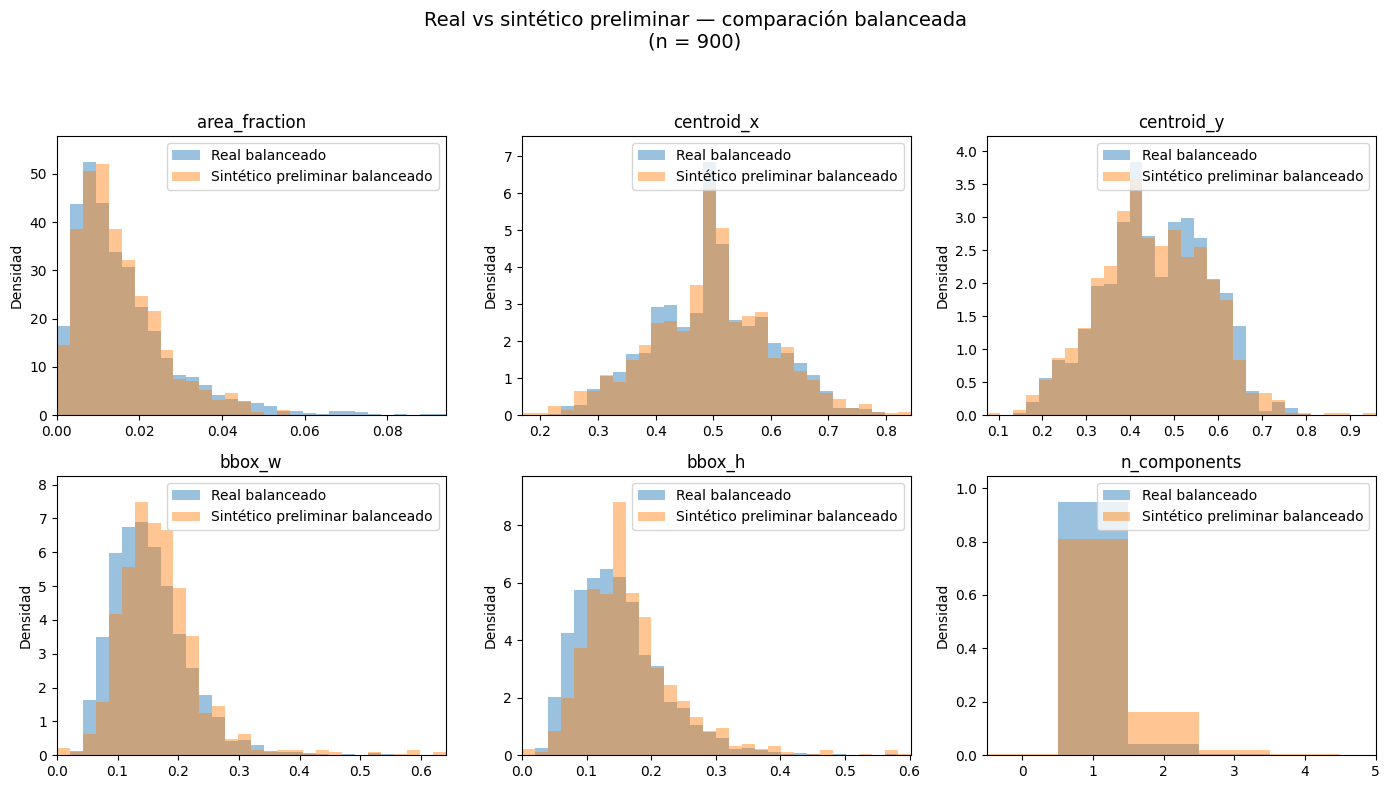

Guardado: K:\Tesis\Github\results\OE2\difusion_bernoulli\final\roiOE1_peso01\diagnosticos\comparacion_morfologia_aceptadas\comparacion_balanceada\morfologia_balanceada_real_vs_preliminares.png


In [48]:
PRELIM_BALANCED_DIAGNOSTIC_DIR = (
    ACCEPTED_DIAGNOSTIC_DIR
    / 'comparacion_balanceada'
)

PRELIM_BALANCED_DIAGNOSTIC_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

metrics_plot = (
    QC_CONTINUOUS
    + ['n_components']
)

manifest_prelim_path = (
    SYNTH_DIR
    / 'manifest_synthetic.csv'
)

if 'synthetic_manifest' in globals():
    prelim_df = synthetic_manifest.copy()
elif manifest_prelim_path.exists():
    prelim_df = pd.read_csv(
        manifest_prelim_path
    )
else:
    raise FileNotFoundError(
        f'No se encontró {manifest_prelim_path}'
    )

if prelim_df.empty:
    raise RuntimeError(
        'El manifest preliminar está vacío.'
    )


def balanced_values_weights(
    df,
    metric,
):
    tmp = (
        df[
            ['condition', metric]
        ]
        .dropna()
        .copy()
    )

    condition_counts = (
        tmp['condition']
        .value_counts()
    )

    n_conditions = len(
        condition_counts
    )

    weights = (
        tmp['condition']
        .map(
            lambda condition:
            1.0
            / (
                n_conditions
                * condition_counts[
                    condition
                ]
            )
        )
        .to_numpy()
    )

    values = (
        tmp[metric]
        .to_numpy()
    )

    return values, weights


real_for_compare = train_df.copy()
prelim_for_compare = prelim_df.copy()

global_bins_prelim = {}
global_xlim_prelim = {}
global_ylim_prelim = {}

for metric in metrics_plot:

    real_vals = (
        real_for_compare[metric]
        .dropna()
        .to_numpy()
    )

    prelim_vals = (
        prelim_for_compare[metric]
        .dropna()
        .to_numpy()
    )

    all_vals = np.concatenate(
        [real_vals, prelim_vals]
    )

    if metric == 'n_components':

        min_value = int(all_vals.min())
        max_value = int(all_vals.max())

        bins = np.arange(
            min_value - 0.5,
            max_value + 1.5,
            1,
        )

        xlim = (
            min_value - 0.5,
            max_value + 0.5,
        )

    else:
        min_value = float(all_vals.min())
        max_value = float(all_vals.max())

        if min_value == max_value:
            min_value -= 0.5
            max_value += 0.5

        bins = np.linspace(
            min_value,
            max_value,
            31,
        )

        xlim = (
            min_value,
            max_value,
        )

    global_bins_prelim[metric] = bins
    global_xlim_prelim[metric] = xlim

    real_vals_bal, real_weights_bal = (
        balanced_values_weights(
            real_for_compare,
            metric,
        )
    )

    prelim_vals_bal, prelim_weights_bal = (
        balanced_values_weights(
            prelim_for_compare,
            metric,
        )
    )

    hist_real, _ = np.histogram(
        real_vals_bal,
        bins=bins,
        weights=real_weights_bal,
        density=True,
    )

    hist_prelim, _ = np.histogram(
        prelim_vals_bal,
        bins=bins,
        weights=prelim_weights_bal,
        density=True,
    )

    density_max = max(
        hist_real.max() if len(hist_real) else 0.0,
        hist_prelim.max() if len(hist_prelim) else 0.0,
    )

    global_ylim_prelim[metric] = (
        0,
        density_max * 1.10,
    )

fig, axes = plt.subplots(
    2,
    3,
    figsize=(14, 8),
)

axes = axes.ravel()

for ax, metric in zip(
    axes,
    metrics_plot,
):

    bins = global_bins_prelim[metric]

    real_vals_bal, real_weights_bal = (
        balanced_values_weights(
            real_for_compare,
            metric,
        )
    )

    prelim_vals_bal, prelim_weights_bal = (
        balanced_values_weights(
            prelim_for_compare,
            metric,
        )
    )

    ax.hist(
        real_vals_bal,
        bins=bins,
        weights=real_weights_bal,
        density=True,
        alpha=0.45,
        label='Real balanceado',
    )

    ax.hist(
        prelim_vals_bal,
        bins=bins,
        weights=prelim_weights_bal,
        density=True,
        alpha=0.45,
        label='Sintético preliminar balanceado',
    )

    ax.set_title(
        metric
    )

    ax.set_xlim(
        global_xlim_prelim[metric]
    )

    if metric == 'n_components':
        ax.set_xticks(
            np.arange(
                int(global_xlim_prelim[metric][0] + 0.5),
                int(global_xlim_prelim[metric][1] + 0.5) + 1,
                1,
            )
        )

    ax.set_ylim(
        global_ylim_prelim[metric]
    )

    ax.set_ylabel(
        'Densidad'
    )

    ax.legend()

fig.suptitle(
    (
        'Real vs sintético preliminar '
        '— comparación balanceada\n'
        f'(n = {len(prelim_df)})'
    ),
    fontsize=14,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

output_path = (
    PRELIM_BALANCED_DIAGNOSTIC_DIR
    / 'morfologia_balanceada_real_vs_preliminares.png'
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight',
)

plt.show()

print(
    f'Guardado: {output_path}'
)


## 24. Registro de configuración y resultados

Se almacenan los parámetros del experimento y un resumen de los archivos generados.

In [49]:
with open(
    OUTPUT_ROOT / 'config_oe2.json',
    'w',
    encoding='utf-8',
) as f:
    json.dump(
        asdict(CFG),
        f,
        indent=2,
        ensure_ascii=False,
    )


summary = {
    'method': 'bernoulli',
    'profile': CFG.PROFILE,
    'roi_definition': (
        'R_i = Omega_i \\ B_i,15; '
        'B_i,15 = componentes de I<=15 conectadas al borde'
    ),
    'roi_threshold': CFG.INTENSITY_THRESHOLD,
    'roi_connectivity': CFG.ROI_CONNECTIVITY,
    'roi_outside_weight': CFG.ROI_OUTSIDE_WEIGHT,
    'mask_threshold': CFG.MASK_THRESHOLD,
    'mask_connectivity': CFG.MASK_CONNECTIVITY,
    'weight_folder': WEIGHT_FOLDER,
    'roi_cache_root': str(ROI_CACHE_ROOT),
    'shared_test_split_csv': str(COMMON_SPLIT_CSV),
    'n_train': int(len(train_df)),
    'n_validation': int(len(val_df)),
    'n_test_final_reserved': int(len(final_test_df)),
    'conditions': sorted(
        masks_df['condition'].unique().tolist()
    ),
    'device': str(DEVICE),
    'torch_version': torch.__version__,
    'best_checkpoint': (
        str(BEST_CKPT)
        if 'BEST_CKPT' in globals()
        else None
    ),
    'lr': CFG.LR,
    'timesteps': CFG.TIMESTEPS,
    'sampling_steps': CFG.SAMPLING_STEPS,
    'lambda_bce': CFG.LAMBDA_BCE,
    'qc': {
        'continuous_features': QC_CONTINUOUS,
        'q_low': CFG.QC_Q_LOW,
        'q_high': CFG.QC_Q_HIGH,
        'components_rule': 'max_train_por_condicion',
        'min_component_pixels_before_smoothing': CFG.MIN_COMPONENT_PIXELS,
        'postprocess_sigma': CFG.POSTPROCESS_SIGMA,
        'postprocess_threshold': CFG.POSTPROCESS_THRESHOLD,
    },
    'validation_metrics': [
        'total_loss',
        'vb_loss',
        'bce_loss',
        'dice',
        'iou',
        'fg_real',
        'fg_pred',
        'empty_pred',
        'fg_mse',
        'bg_mse',
        'flip_real',
        'flip_pred',
    ],
    'diagnostic_files': {
        'history': str(
            TABLE_DIR / 'history.csv'
        ),
        'timestep_history': str(
            TABLE_DIR / 'val_timestep_history.csv'
        ),
        'qc_ranges': str(
            TABLE_DIR / 'qc_ranges_train.csv'
        ),
        'qc_validation': str(
            TABLE_DIR / 'qc_validacion_real.csv'
        ),
    },
}


with open(
    OUTPUT_ROOT / 'resumen_oe2.json',
    'w',
    encoding='utf-8',
) as f:
    json.dump(
        summary,
        f,
        indent=2,
        ensure_ascii=False,
    )


print(
    json.dumps(
        summary,
        indent=2,
        ensure_ascii=False,
    )
)


{
  "method": "bernoulli",
  "profile": "final",
  "roi_definition": "R_i = Omega_i \\ B_i,15; B_i,15 = componentes de I<=15 conectadas al borde",
  "roi_threshold": 15,
  "roi_connectivity": 2,
  "roi_outside_weight": 0.1,
  "mask_threshold": 127,
  "mask_connectivity": 2,
  "weight_folder": "roiOE1_peso01",
  "roi_cache_root": "K:\\Tesis\\Github\\results\\OE2\\preprocesamiento\\roiOE1_umbral15",
  "shared_test_split_csv": "K:\\Tesis\\Github\\results\\OE2\\particiones\\brisc_test_validation_test_50_50.csv",
  "n_train": 3792,
  "n_validation": 420,
  "n_test_final_reserved": 420,
  "conditions": [
    "gl_ax",
    "gl_co",
    "gl_sa",
    "me_ax",
    "me_co",
    "me_sa",
    "pi_ax",
    "pi_co",
    "pi_sa"
  ],
  "device": "cuda",
  "torch_version": "2.11.0+cu128",
  "best_checkpoint": "K:\\Tesis\\Github\\results\\OE2\\difusion_bernoulli\\final\\roiOE1_peso01\\checkpoints\\best.pt",
  "lr": 0.0001,
  "timesteps": 1000,
  "sampling_steps": 100,
  "lambda_bce": 1.0,
  "qc": {
    "